# Electricity Load Forecasting — Tetouan City (Morocco)
### Full Data Science Pipeline: Problem Definition → EDA → Feature Engineering → ML-Ready Data

---
## 0. Problem Definition

**Business problem:** The power company needs to know *how much electricity each zone of the city will use in the future*.
Good forecasts = less energy waste, lower cost, and fewer blackouts.

**ML problem:** *Supervised time-series regression* (multi-target).

| Item | Definition |
|---|---|
| Data | 1 year (Jan–Dec 2017), one row every **10 minutes** = 52,416 rows |
| Targets | `zone1`, `zone2`, `zone3` and `total` (sum of the 3 zones) |
| Inputs | Weather (temperature, humidity, wind, 2 solar-radiation columns) + time + past load |
| Forecast horizon | **Day-ahead (24h = 144 steps)** — configurable (`HORIZON`) |
| Metrics | MAE, RMSE, **MAPE** (easy for business to understand) |
| Validation | **Chronological split only** (never random split — that leaks the future) |


## 1. Setup & Load Data

In [7]:
import os, json, zipfile, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4)
pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42

 **Insights**

- Only standard libraries (pandas, numpy, scikit-learn, seaborn, scipy). No special installs needed.
- `RANDOM_STATE` is fixed so you get the same results every run.

In [8]:
CSV = "Tetuan City power consumption.csv"
ZIP = "power+consumption+of+tetouan+city.zip"
if not os.path.exists(CSV) and os.path.exists(ZIP):
    zipfile.ZipFile(ZIP).extractall(".")
raw = pd.read_csv(CSV)
raw.head()

,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


 **Insights**

- The raw file has 9 columns: 1 time column, 5 weather columns, 3 power columns (one per zone).
- Column names are messy (spaces, capital letters, a double space in `Zone 2  Power Consumption`). We fix that next.

In [9]:
df = raw.copy()
df.columns = df.columns.str.strip().str.lower().str.replace(r"\s+", "_", regex=True)
df = df.rename(columns={"temperature": "temp", "wind_speed": "wind",
    "general_diffuse_flows": "gen_diffuse", "diffuse_flows": "diffuse",
    "zone_1_power_consumption": "zone1", "zone_2_power_consumption": "zone2",
    "zone_3_power_consumption": "zone3"})
df["datetime"] = pd.to_datetime(df["datetime"], format="%m/%d/%Y %H:%M")
df = df.set_index("datetime").sort_index()
WEATHER = ["temp", "humidity", "wind", "gen_diffuse", "diffuse"]
ZONES = ["zone1", "zone2", "zone3"]
df["total"] = df[ZONES].sum(axis=1)
TARGETS = ZONES + ["total"]
df.head()

,temp,humidity,wind,gen_diffuse,diffuse,zone1,zone2,zone3,total
datetime,,,,,,,,,
2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,70425.53544
2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,69320.84387
2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,67803.22193
2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,65489.23209
2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964,63650.44627


 **Insights**

- Short clean names make the code easy to read. **Data dictionary:**
  - `temp` = air temperature (°C), `humidity` = %, `wind` = wind speed
  - `gen_diffuse`, `diffuse` = two solar-radiation measures (0 at night)
  - `zone1/2/3` = power consumption of each city zone
  - `total` = zone1 + zone2 + zone3 (**we created this** — the city-level target)
- Using the datetime as the index makes all time-based work (resample, rolling, shift) simple.

## 2. Data Understanding & Quality Checks

In [10]:
print("Shape   :", df.shape)
print("Start   :", df.index.min())
print("End     :", df.index.max())
print("Duration:", df.index.max() - df.index.min())
df.info()

Shape   : (52416, 9)
Start   : 2017-01-01 00:00:00
End     : 2017-12-30 23:50:00
Duration: 363 days 23:50:00
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 52416 entries, 2017-01-01 00:00:00 to 2017-12-30 23:50:00
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   temp         52416 non-null  float64
 1   humidity     52416 non-null  float64
 2   wind         52416 non-null  float64
 3   gen_diffuse  52416 non-null  float64
 4   diffuse      52416 non-null  float64
 5   zone1        52416 non-null  float64
 6   zone2        52416 non-null  float64
 7   zone3        52416 non-null  float64
 8   total        52416 non-null  float64
dtypes: float64(9)
memory usage: 4.0 MB


 **Insights**

- 52,416 rows × 9 columns, from **1 Jan 2017 to 30 Dec 2017** (one full year, one row every 10 minutes).
- All columns are float and non-null. Memory is only 4 MB, so everything runs fast.
- Important: we have **only one year**. The model will never see two winters or two summers — we must keep this in mind later.

In [11]:
print("Missing values per column:\n", df.isna().sum().to_string())
print("\nDuplicate rows       :", df.duplicated().sum())
print("Duplicate timestamps :", df.index.duplicated().sum())
print("\nTime gaps between consecutive rows:")
print(df.index.to_series().diff().value_counts().to_string())

Missing values per column:
 temp           0
humidity       0
wind           0
gen_diffuse    0
diffuse        0
zone1          0
zone2          0
zone3          0
total          0

Duplicate rows       : 0
Duplicate timestamps : 0

Time gaps between consecutive rows:
datetime
0 days 00:10:00    52415


**Insights**

- **0 missing values, 0 duplicate rows, 0 duplicate timestamps.**
- Every gap between rows is exactly 10 minutes → a perfect time grid. No resampling or interpolation is needed.
- This is rare and very good: lag features (shift by N rows) will be exactly N × 10 minutes.

In [12]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
temp,52416.0,18.81,5.82,3.25,14.41,18.78,22.89,40.01
humidity,52416.0,68.26,15.55,11.34,58.31,69.86,81.40,94.80
wind,52416.0,1.96,2.35,0.05,0.08,0.09,4.92,6.48
gen_diffuse,52416.0,182.70,264.40,0.00,0.06,5.04,319.60,1163.00
diffuse,52416.0,75.03,124.21,0.01,0.12,4.46,101.00,936.00
zone1,52416.0,32344.97,7130.56,13895.70,26310.67,32265.92,37309.02,52204.40
zone2,52416.0,21042.51,5201.47,8560.08,16980.77,20823.17,24713.72,37408.86
zone3,52416.0,17835.41,6622.17,5935.17,13129.33,16415.12,21624.10,47598.33
total,52416.0,71222.89,17143.14,36785.04,56499.07,69788.79,83749.17,134208.15


 **Insights**

- Zone 1 is the biggest (mean ≈ 32k), then Zone 2 (≈ 21k), then Zone 3 (≈ 18k). Total mean ≈ 71k.
- Temperature goes from 3.3 °C to 40 °C — a big yearly range, so weather should matter.
- `gen_diffuse` median is only 5 while the max is 1163: the median is almost "night", the max is "sunny noon".
- Zone 3 has a high max (47.6k) compared with its 75% value (21.6k): it has a long right tail.

In [13]:
checks = {
    "humidity outside 0-100": int(((df.humidity < 0) | (df.humidity > 100)).sum()),
    "negative wind": int((df.wind < 0).sum()),
    "negative radiation": int(((df.gen_diffuse < 0) | (df.diffuse < 0)).sum()),
    "zero/negative power": int((df[ZONES] <= 0).sum().sum()),
    "constant columns": int((df.nunique() <= 1).sum()),
}
pd.Series(checks, name="count").to_frame()

,count
humidity outside 0-100,0
negative wind,0
negative radiation,0
zero/negative power,0
constant columns,0


**Insights**

- No impossible values: humidity is inside 0–100, nothing negative, no zero power, no constant column.
- The data is physically valid, so we don't need to fix any sensor errors.

In [14]:
pd.DataFrame({"dtype": df.dtypes, "unique": df.nunique(), "zeros": (df == 0).sum()})

,dtype,unique,zeros
temp,float64,3437,0
humidity,float64,4443,0
wind,float64,548,0
gen_diffuse,float64,10504,0
diffuse,float64,10449,0
zone1,float64,27709,0
zone2,float64,29621,0
zone3,float64,22838,0
total,float64,52416,0


 **Insights**

- All columns are numeric floats with many unique values → true continuous variables.
- No column has zeros, so there are no hidden "fake zeros" to treat as missing.
- `wind` has only 548 unique values (low sensor resolution) — we will see this is a special variable later.

## 3. Univariate Analysis (one variable at a time)

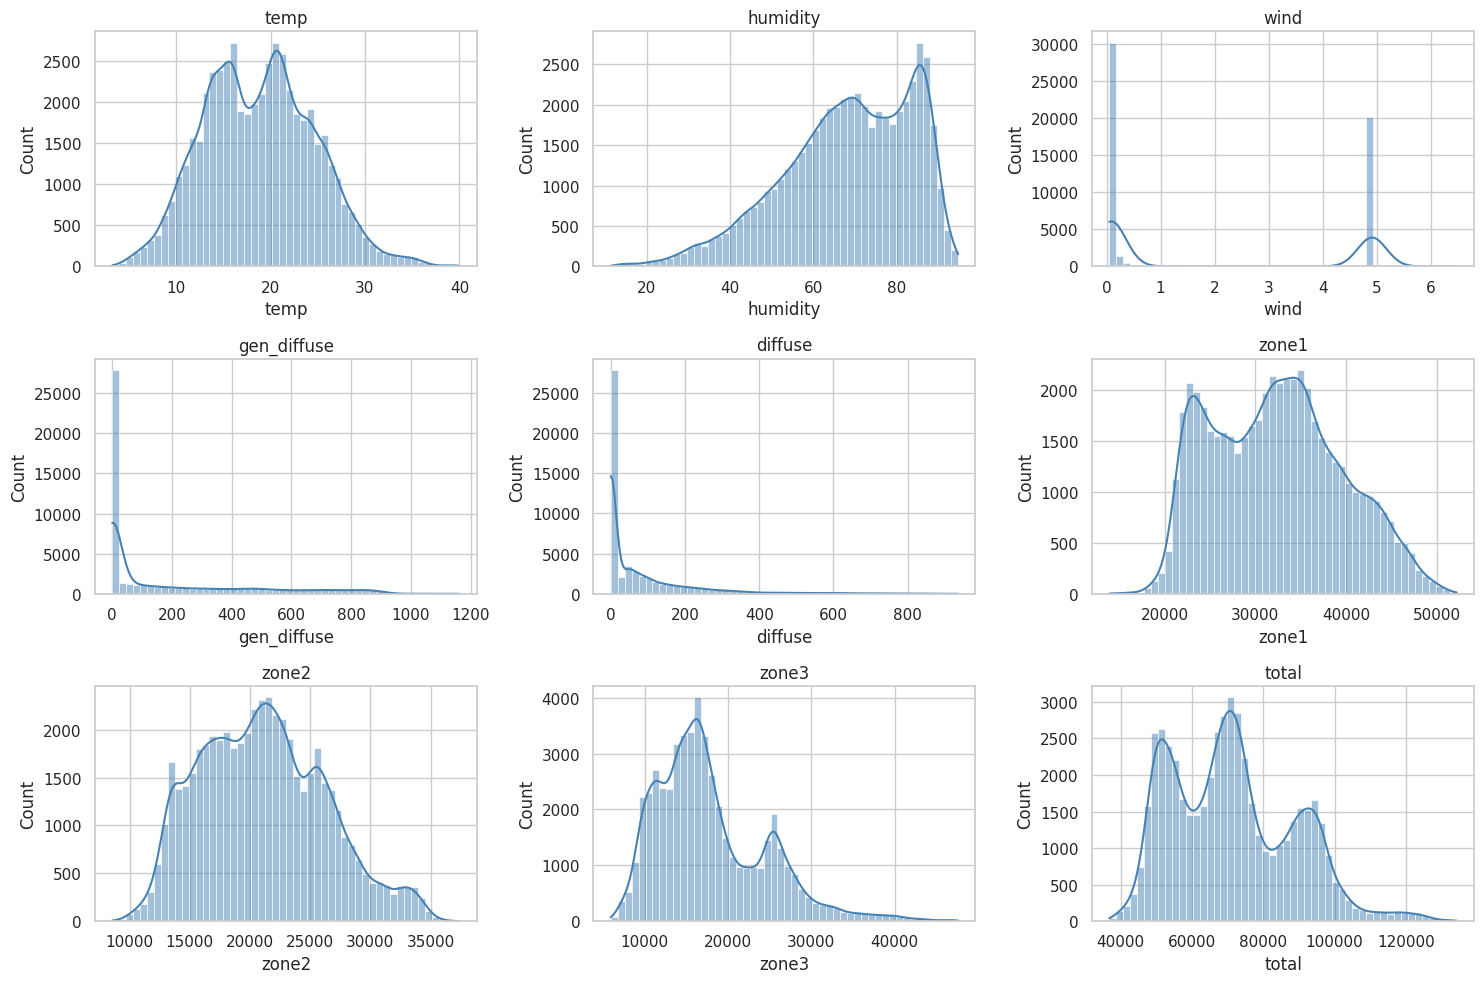

In [15]:
cols = WEATHER + ZONES + ["total"]
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c in zip(axes.ravel(), cols):
    sns.histplot(df[c], kde=True, bins=50, ax=ax, color="steelblue")
    ax.set_title(c)
plt.tight_layout(); plt.show()

**Insights**

- Temperature and the zones look close to bell-shaped → easy for models.
- `gen_diffuse` and `diffuse` pile up near 0 (night) with a long tail to the right → very skewed.
- `wind` is **not** a normal shape: it has two big groups (almost calm vs windy). We handle this later.
- Zone 3 is the most skewed zone (right tail).

In [16]:
uni = pd.DataFrame({"mean": df[cols].mean(), "median": df[cols].median(), "std": df[cols].std(),
                    "skew": df[cols].skew(), "kurtosis": df[cols].kurt(),
                    "cv_%": df[cols].std() / df[cols].mean() * 100})
uni.round(2)

,mean,median,std,skew,kurtosis,cv_%
temp,18.81,18.78,5.82,0.20,-0.30,30.92
humidity,68.26,69.86,15.55,-0.63,-0.12,22.78
wind,1.96,0.09,2.35,0.46,-1.78,119.87
gen_diffuse,182.70,5.04,264.40,1.31,0.40,144.72
diffuse,75.03,4.46,124.21,2.46,7.00,165.55
zone1,32344.97,32265.92,7130.56,0.23,-0.75,22.05
zone2,21042.51,20823.17,5201.47,0.33,-0.44,24.72
zone3,17835.41,16415.12,6622.17,1.02,1.09,37.13
total,71222.89,69788.79,17143.14,0.52,-0.23,24.07


 **Insights**

- Most skewed: `diffuse` (skew 2.46, kurtosis 7.0) and `gen_diffuse` (1.31). Radiation is zero at night, so this is natural.
- `wind` has kurtosis −1.78 = two separate clusters, not one hump.
- Zone 3 has the highest variation among zones (CV 37%) vs Zone 1 (22%) → Zone 3 will be the hardest to predict.
- Targets are only mildly skewed (total skew 0.52) → **no log transform needed** for the target.

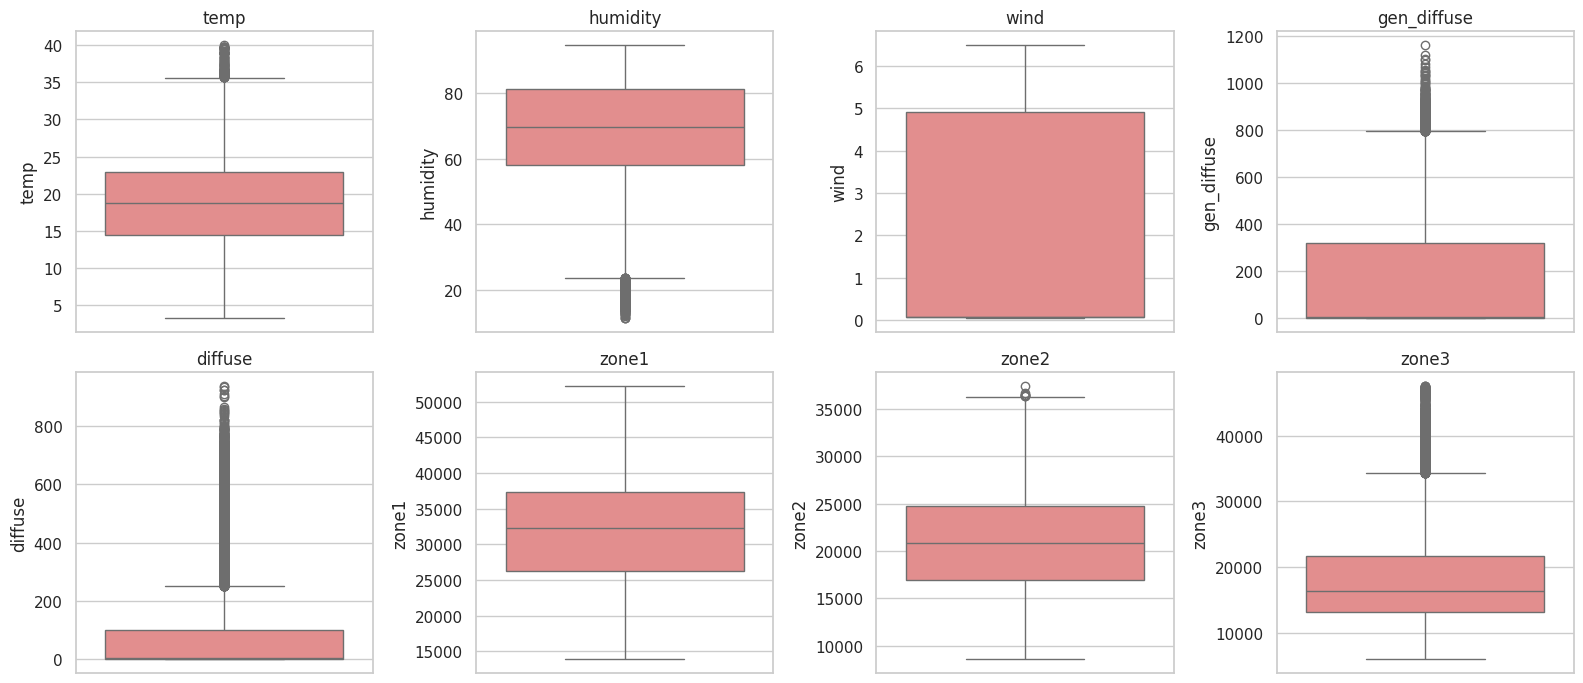

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), cols[:8]):
    sns.boxplot(y=df[c], ax=ax, color="lightcoral"); ax.set_title(c)
plt.tight_layout(); plt.show()

 **Insights**

- Boxplots confirm: radiation columns and Zone 3 have many points above the whiskers.
- Temperature, humidity and Zone 1 are clean. Zone 2 has almost no outliers.

In [18]:
z = (df[cols] - df[cols].mean()) / df[cols].std()
def iqr_count(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())
out = pd.DataFrame({"IQR_outliers": [iqr_count(df[c]) for c in cols],
                    "z>3": (z.abs() > 3).sum().values, "z>4": (z.abs() > 4).sum().values}, index=cols)
out["IQR_%"] = (out.IQR_outliers / len(df) * 100).round(2)
out

,IQR_outliers,z>3,z>4,IQR_%
temp,142,89,0,0.27
humidity,291,209,0,0.56
wind,0,0,0,0.00
gen_diffuse,2315,23,0,4.42
diffuse,4571,1361,666,8.72
zone1,0,0,0,0.00
zone2,7,1,0,0.01
zone3,1191,653,79,2.27
total,150,257,0,0.29


**Insights**

- By the IQR rule: `diffuse` 8.7% and `gen_diffuse` 4.4% "outliers", but these are just **sunny hours**, not errors.
- Zone 3: 2.3% outliers (79 points with z > 4) — real high-demand periods in summer (we check this in section 8).
- Total load has only 0.29% IQR outliers and **no point above z = 4**.
- Decision: **do not delete** any outlier now. In load forecasting, peaks are the most important part to predict.

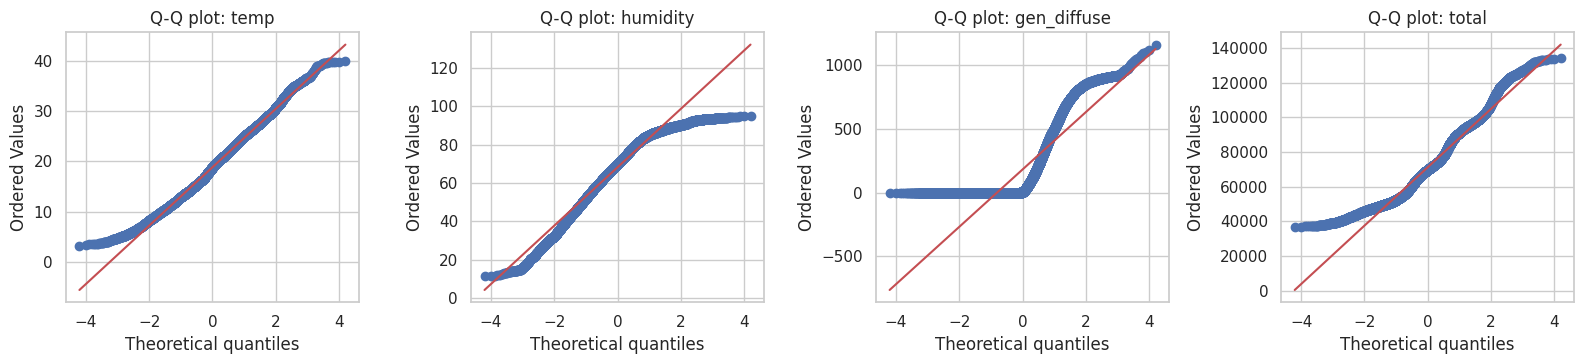

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, c in zip(axes, ["temp", "humidity", "gen_diffuse", "total"]):
    stats.probplot(df[c], dist="norm", plot=ax); ax.set_title(f"Q-Q plot: {c}")
plt.tight_layout(); plt.show()

💡 **Insights**

- Points leave the red line at the ends for radiation and for the load → these variables are not normal.
- This is fine for tree models and neural networks. For linear models we will rely on scaling and good features, not on normality.

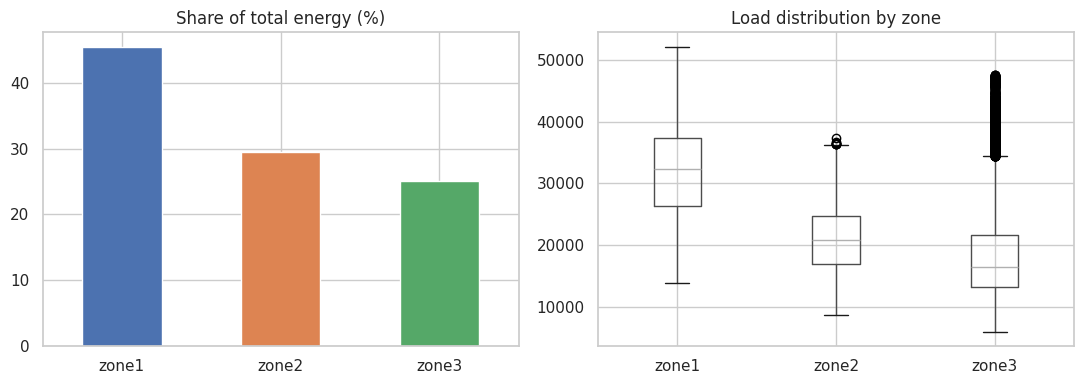

,0
zone1,45.4
zone2,29.5
zone3,25.0


In [20]:
share = df[ZONES].sum() / df[ZONES].sum().sum() * 100
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
share.plot.bar(ax=ax[0], color=["#4c72b0", "#dd8452", "#55a868"], rot=0); ax[0].set_title("Share of total energy (%)")
df[ZONES].boxplot(ax=ax[1]); ax[1].set_title("Load distribution by zone")
plt.tight_layout(); plt.show()
share.round(1)

**Insights**

- Share of city energy: **Zone 1 = 45%, Zone 2 = 30%, Zone 3 = 25%**.
- Zone 1 drives the total, but Zone 3 swings the most, so it matters for the total's peaks.

In [21]:
print("Rows where gen_diffuse < 1 W/m2 :", f"{(df.gen_diffuse < 1).mean():.1%}")
print("Rows where diffuse     < 1 W/m2 :", f"{(df.diffuse < 1).mean():.1%}")
df.groupby(df.index.hour)["gen_diffuse"].mean().round(1).to_frame().T

Rows where gen_diffuse < 1 W/m2 : 47.9%
Rows where diffuse     < 1 W/m2 : 48.0%


datetime,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
gen_diffuse,0.1,0.1,0.1,0.1,0.1,0.1,5.5,47.0,145.5,290.8,432.5,530.5,588.5,586.4,544.6,468.7,357.9,234.8,114.3,34.2,2.9,0.1,0.1,0.1


 **Insights**

- About 48% of rows have almost zero radiation (night).
- The sun curve: starts at 6h, peak at 12–13h (≈ 590), ends at 19–20h.
- So `gen_diffuse` is basically a **"is it daytime + how clear is the sky"** signal. We will build `is_daylight` from it.

## 4. Time Patterns (Trend • Seasonality • Calendar effects)

In [22]:
eda = df.copy()
eda["hour"] = eda.index.hour; eda["dow"] = eda.index.dayofweek; eda["month"] = eda.index.month
eda["is_weekend"] = (eda.dow >= 5).astype(int); eda["date"] = eda.index.normalize()
eda["slot"] = eda.index.hour * 6 + eda.index.minute // 10
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("EDA frame ready:", eda.shape)

EDA frame ready: (52416, 15)


 **Insights**

- We made a separate `eda` copy with calendar columns, so the main `df` stays clean for modeling.

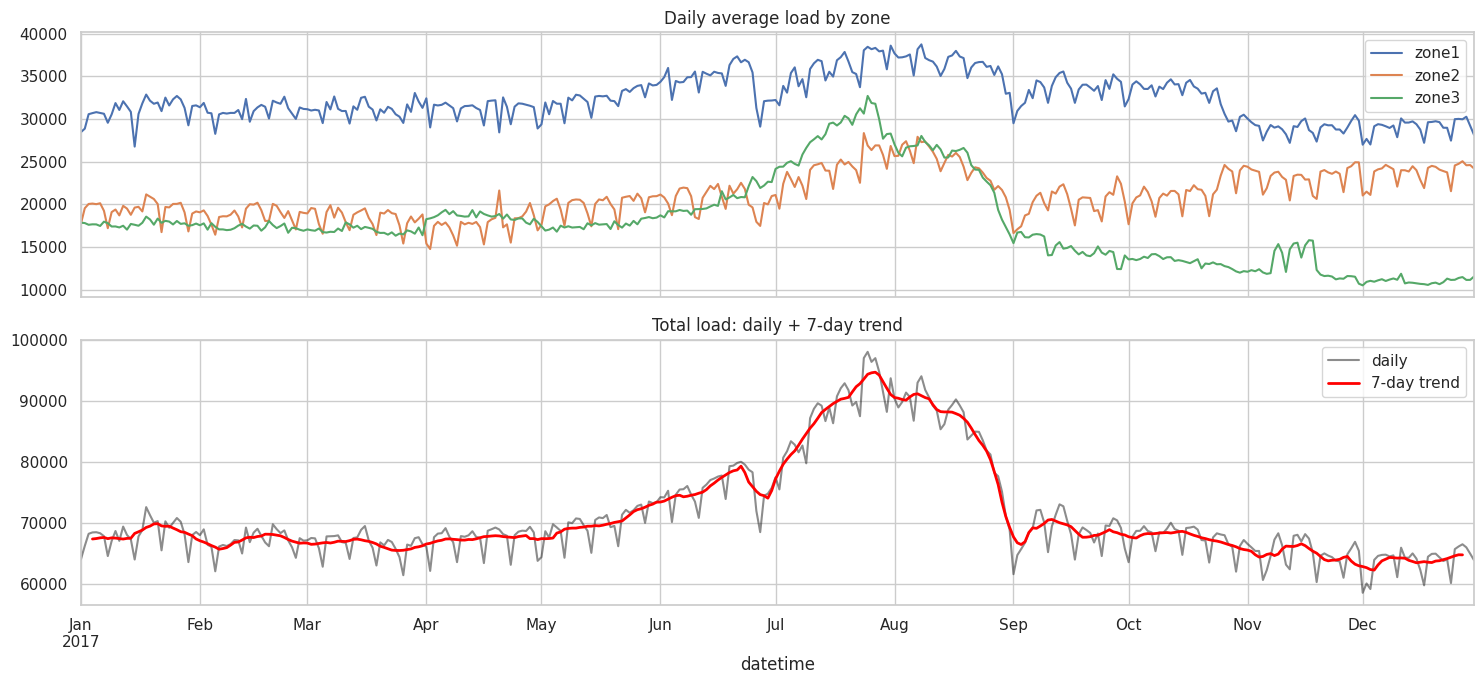

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
df[ZONES].resample("D").mean().plot(ax=axes[0]); axes[0].set_title("Daily average load by zone")
df["total"].resample("D").mean().plot(ax=axes[1], color="k", alpha=.5, label="daily")
df["total"].resample("D").mean().rolling(7, center=True).mean().plot(ax=axes[1], color="red", lw=2, label="7-day trend")
axes[1].legend(); axes[1].set_title("Total load: daily + 7-day trend")
plt.tight_layout(); plt.show()

**Insights**

- **Biggest finding:** Zone 3 behaves very differently from the others. It is flat (~17k) until May, **climbs to ~32k in July**, then **falls fast at the start of September** to ~11k and keeps falling.
- Zone 1 and Zone 2 follow a softer summer rise (Zone 1 peaks in Jul–Aug, Zone 2 in Jul–Aug too).
- Total load: ~67k in winter/spring, **~90k in July–August (+30%)**, back to ~65k in autumn.
- This is **not stationary**: the mean level changes through the year. Models must use features that follow the level (recent lags, weather).

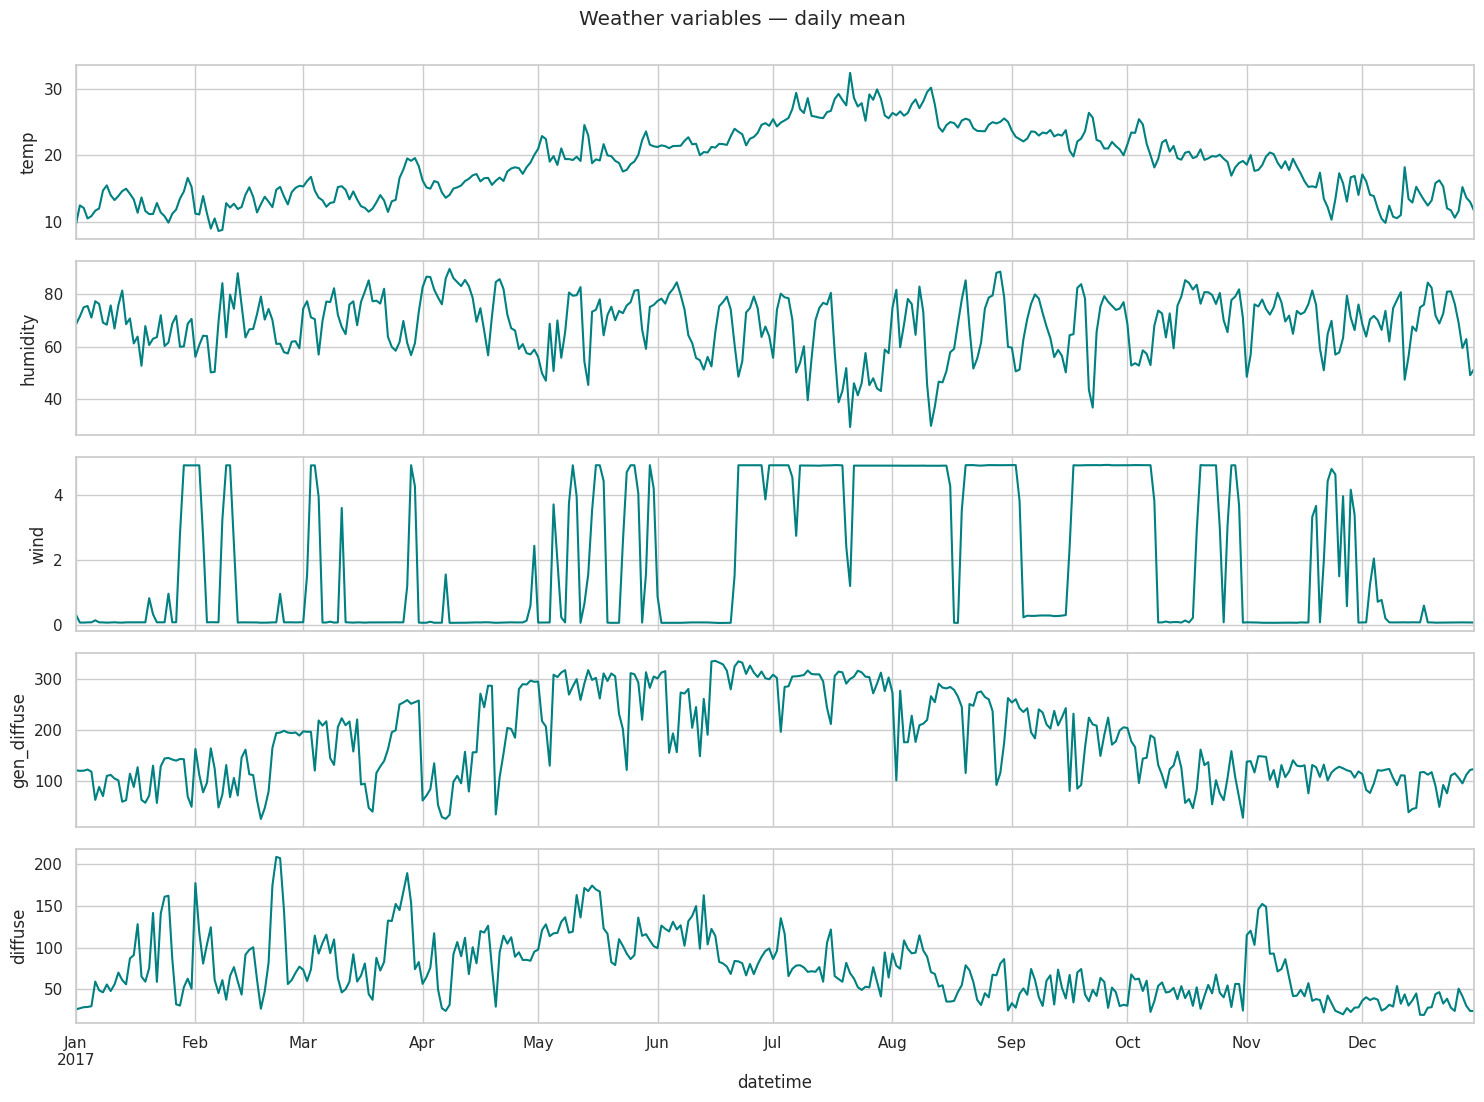

In [24]:
fig, axes = plt.subplots(5, 1, figsize=(15, 11), sharex=True)
for ax, c in zip(axes, WEATHER):
    df[c].resample("D").mean().plot(ax=ax, color="teal"); ax.set_ylabel(c)
plt.suptitle("Weather variables — daily mean", y=1.0); plt.tight_layout(); plt.show()

 **Insights**

- Temperature has a clear yearly wave (cold Jan–Feb, hot Jul–Aug). Radiation follows the same wave.
- Humidity moves in the opposite way to temperature.
- Wind is very seasonal: monthly mean ≈ 0.2–0.7 in Jan, Apr and Dec, but **4.6 in July and 4.5 in August**. So wind partly acts as a "summer" signal.

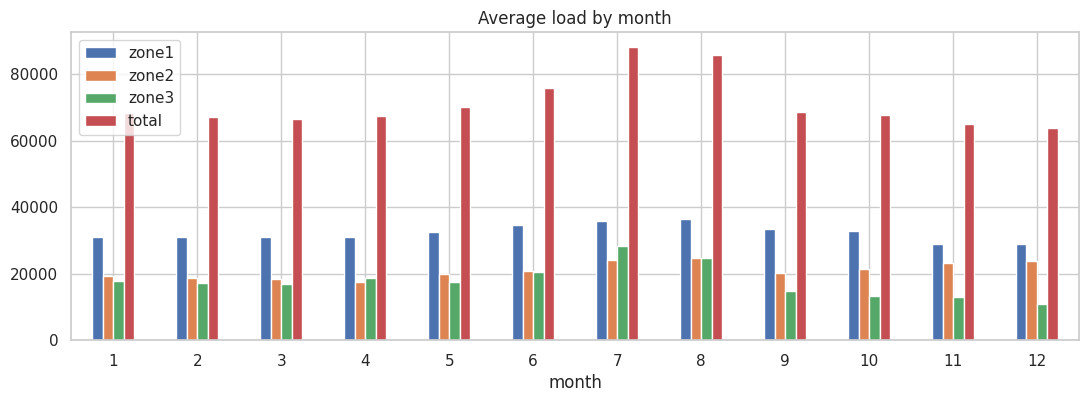

month,1,2,3,4,5,6,7,8,9,10,11,12
zone1,31032.0,30986.0,31155.0,31170.0,32396.0,34606.0,35832.0,36435.0,33397.0,32828.0,29002.0,29024.0
zone2,19394.0,18788.0,18458.0,17634.0,19977.0,20671.0,24148.0,24656.0,20180.0,21469.0,23240.0,23682.0
zone3,17746.0,17335.0,16948.0,18593.0,17621.0,20431.0,28194.0,24649.0,14923.0,13264.0,12862.0,11045.0
total,68173.0,67109.0,66561.0,67397.0,69994.0,75707.0,88174.0,85740.0,68500.0,67561.0,65105.0,63751.0


In [25]:
m = eda.groupby("month")[ZONES + ["total"]].mean()
m.plot.bar(figsize=(13, 4), rot=0); plt.title("Average load by month"); plt.show()
m.round(0).T

**Insights**

- Total load by month: Jan 68k, Mar 67k, **Jul 88k (peak)**, Aug 86k, Dec 64k (lowest).
- Zone 3 in July (28k) is **63% higher** than in January (17.7k) and then drops to 11k by December.
- Zone 2 is the opposite of Zone 3 late in the year: it grows in Nov–Dec (23–24k).
- Month is a strong feature, but with only 1 year we must also use *weather* to explain the summer effect (otherwise the model may just memorise "July").

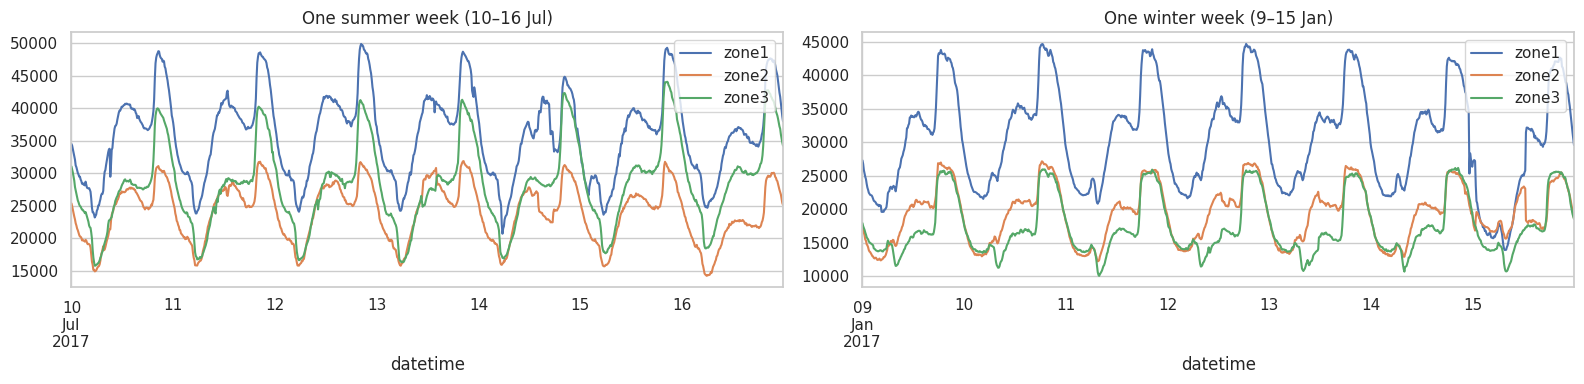

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
df.loc["2017-07-10":"2017-07-16", ZONES].plot(ax=axes[0]); axes[0].set_title("One summer week (10–16 Jul)")
df.loc["2017-01-09":"2017-01-15", ZONES].plot(ax=axes[1]); axes[1].set_title("One winter week (9–15 Jan)")
plt.tight_layout(); plt.show()

**Insights**

- Both weeks show a very regular **daily wave**: low in the early morning, high in the evening.
- In summer the daily peak is much higher (weather + cooling), and Zone 3 has the biggest daily swing.
- Daily shape is so repeatable that "same time yesterday" will already be a strong baseline.

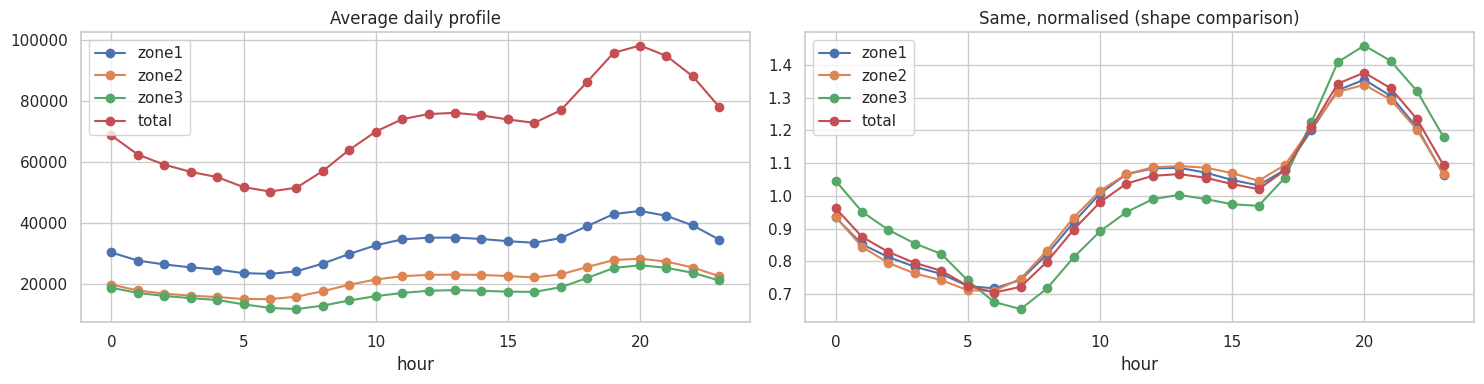

,total
idxmin,6.000000
min,50189.895727
idxmax,20.000000
max,98037.110110


In [27]:
prof = eda.groupby("hour")[ZONES + ["total"]].mean()
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
prof.plot(ax=ax[0], marker="o"); ax[0].set_title("Average daily profile")
(prof / prof.mean()).plot(ax=ax[1], marker="o"); ax[1].set_title("Same, normalised (shape comparison)")
plt.tight_layout(); plt.show()
prof["total"].agg(["idxmin", "min", "idxmax", "max"])

 **Insights**

- All zones have the same shape: **lowest at 06:00 (≈ 50k total), highest at 20:00 (≈ 98k total)**.
- Peak vs trough: total 1.9×, Zone 3 **2.2×** (more extreme).
- There is a small shoulder at 11–15h and a big evening peak at 19–21h (lighting + home use).
- The hour of day is the **single strongest calendar signal** → we will use `slot` (0–143) with sin/cos encoding.

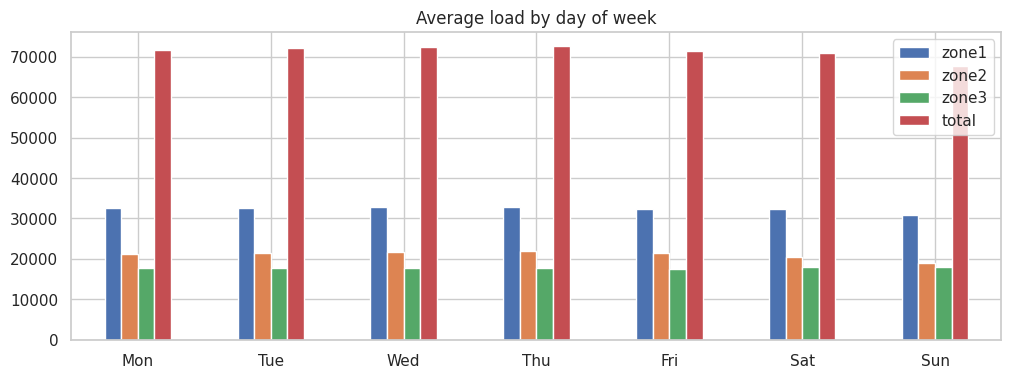

,zone1,zone2,zone3,total
weekend vs weekday %,-3.5,-8.2,1.2,-3.8


In [28]:
d = eda.groupby("dow")[ZONES + ["total"]].mean(); d.index = DOW
d.plot.bar(figsize=(12, 4), rot=0); plt.title("Average load by day of week"); plt.show()
(d.loc[["Sat", "Sun"]].mean() / d.loc[DOW[:5]].mean() - 1).mul(100).round(1).to_frame("weekend vs weekday %").T

 **Insights**

- Weekends are lower: total **−3.8%**, Zone 2 **−8.2%**, Zone 1 −3.5%, Zone 3 even +1.2%.
- Zone 2 has a business/office-like behavior (clear weekend drop); Zone 3 does not care about weekdays.
- Sunday is the lowest day. The weekday effect is small compared with the hour effect.

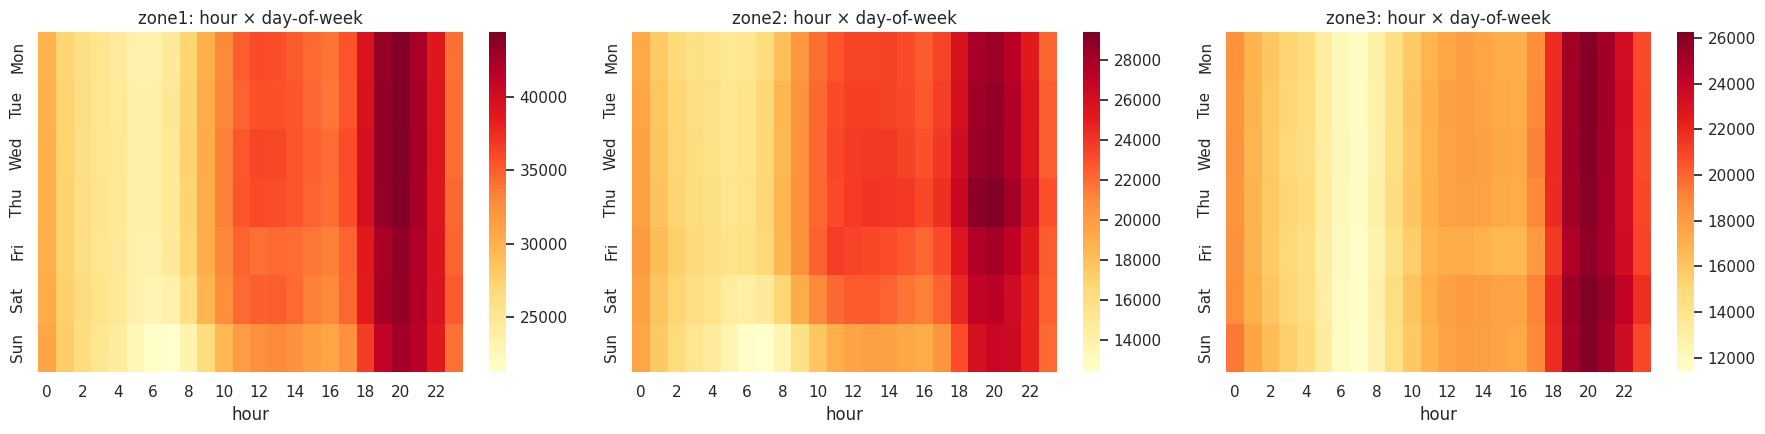

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, z in zip(axes, ZONES):
    p = eda.pivot_table(index="dow", columns="hour", values=z, aggfunc="mean"); p.index = DOW
    sns.heatmap(p, cmap="YlOrRd", ax=ax); ax.set_title(f"{z}: hour × day-of-week")
plt.tight_layout(); plt.show()

 **Insights**

- Heatmaps are almost horizontal bands: the **hour matters much more than the day**.
- Zone 2 shows the clearest weekend pattern (lighter weekend rows).
- Zone 3 rows look the same for every day → weekday features will not help Zone 3 much.

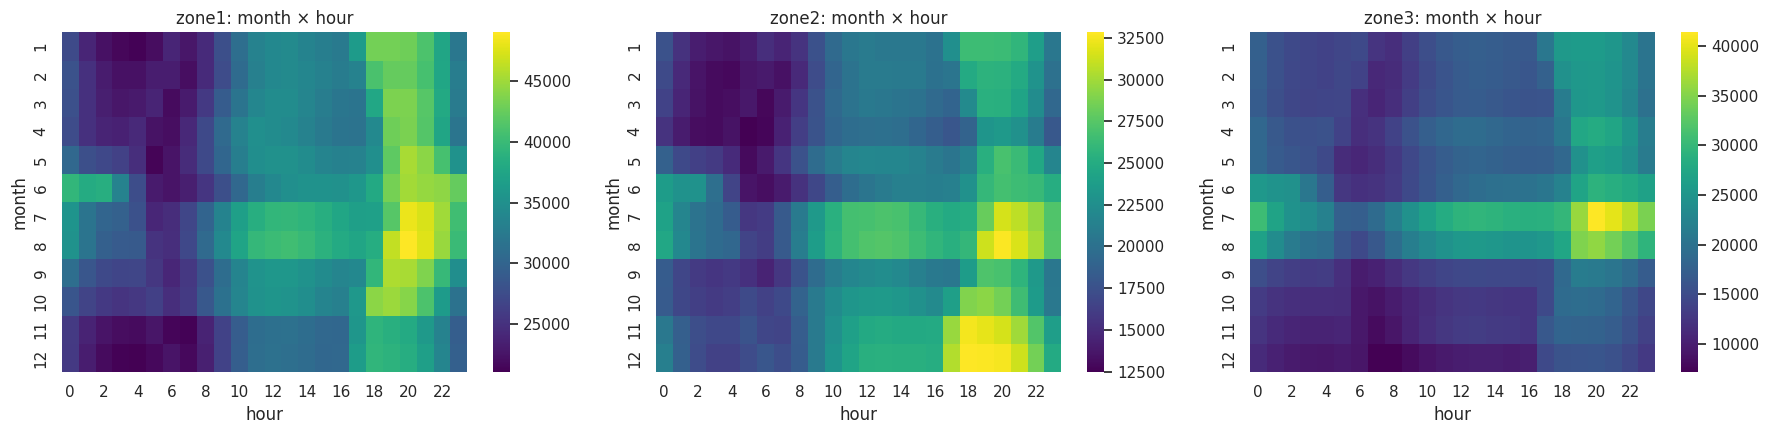

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, z in zip(axes, ZONES):
    sns.heatmap(eda.pivot_table(index="month", columns="hour", values=z, aggfunc="mean"), cmap="viridis", ax=ax)
    ax.set_title(f"{z}: month × hour")
plt.tight_layout(); plt.show()

 **Insights**

- Summer months (Jun–Aug) are bright all day, with the strongest effect at midday and evening → this is the cooling (air-conditioning) effect.
- Zone 3 changes the most between months (dark in winter, bright in summer).
- The evening peak moves with the season: around **20:00 in spring/summer, but 18:00 in Nov–Dec** (earlier sunset). This is why we need `month` (or day-of-year) together with `hour`.

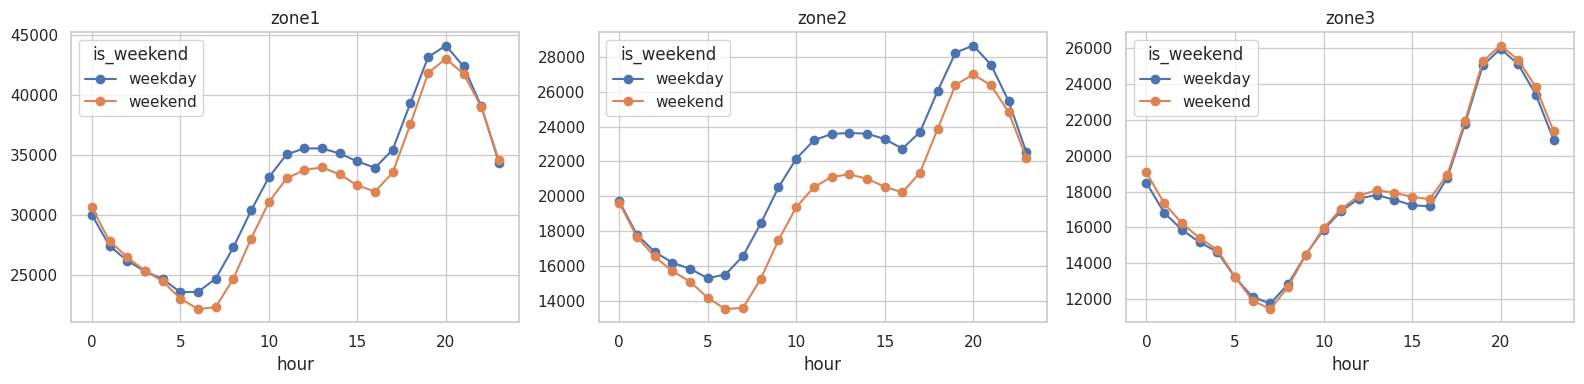

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
for ax, z in zip(axes, ZONES):
    eda.groupby(["hour", "is_weekend"])[z].mean().unstack().rename(columns={0: "weekday", 1: "weekend"}).plot(ax=ax, marker="o")
    ax.set_title(z)
plt.tight_layout(); plt.show()

 **Insights**

- Weekday vs weekend differ mostly in the **morning (08h: 58.6k vs 52.7k)** — people start work later at the weekend.
- The evening peak is almost the same (99k vs 96k).
- Interaction `is_weekend × hour` will help the model, especially for Zone 2.

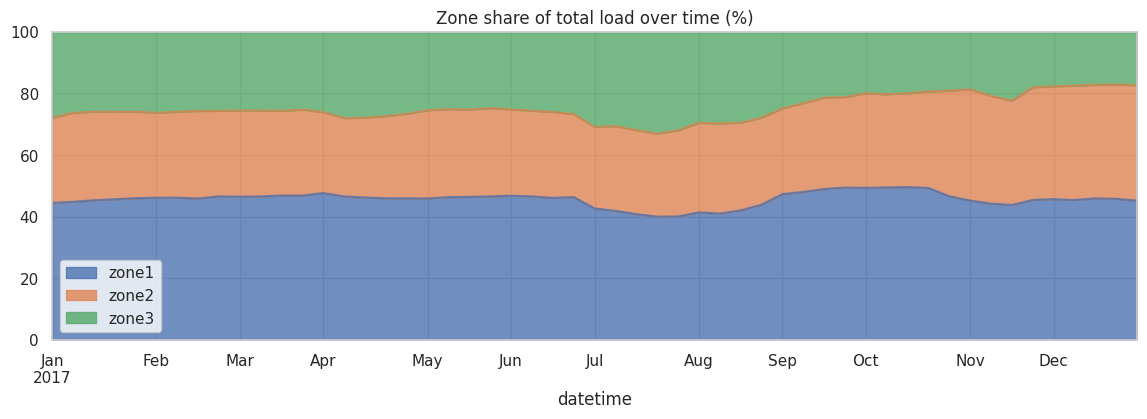

,zone1,zone2,zone3
mean,45.7,29.7,24.7
std,2.3,3.4,4.2
min,40.0,25.4,17.1
max,49.6,37.5,33.0


In [32]:
sh = df[ZONES].div(df["total"], axis=0).resample("W").mean() * 100
sh.plot.area(figsize=(14, 4), alpha=.8); plt.title("Zone share of total load over time (%)"); plt.ylim(0, 100); plt.show()
sh.describe().loc[["mean", "std", "min", "max"]].round(1)

**Insights**

- Zone shares are not fixed: Zone 1 ≈ 40–50%, Zone 2 ≈ 25–37%, Zone 3 ≈ 17–33%.
- Zone 3's share moves a lot (std 4.2 points), so we cannot predict zones as "fixed % of total".
- Model each zone **separately** (or multi-output), and also model total directly.

In [33]:
# Approximate Moroccan public holidays 2017 (Islamic dates depend on moon sighting -> +/- 1 day)
HOLIDAYS = pd.to_datetime(["2017-01-01", "2017-01-11", "2017-05-01", "2017-06-25", "2017-06-26", "2017-07-30",
                           "2017-08-14", "2017-08-20", "2017-08-21", "2017-09-01", "2017-09-02", "2017-09-21",
                           "2017-11-06", "2017-11-18", "2017-12-01"])
RAMADAN = (pd.Timestamp("2017-05-27"), pd.Timestamp("2017-06-24"))
daily = eda.groupby("date")["total"].mean().to_frame("load")
daily["holiday"] = daily.index.isin(HOLIDAYS)
def neighbours(d):   # same weekday, +/- 1 and 2 weeks, non-holiday -> fair comparison (same season)
    ref = [d + pd.Timedelta(days=k) for k in (-14, -7, 7, 14)]
    return daily.loc[[r for r in ref if r in daily.index and r not in HOLIDAYS], "load"].mean()
daily["ref"] = [neighbours(d) for d in daily.index]
daily["vs_neighbour_weeks_%"] = (daily.load / daily.ref - 1) * 100
daily[daily.holiday][["load", "ref", "vs_neighbour_weeks_%"]].round(1)

,load,ref,vs_neighbour_weeks_%
date,,,
2017-01-01,64071.8,64307.9,-0.4
2017-01-11,67082.8,70365.4,-4.7
2017-05-01,64415.0,69341.5,-7.1
2017-06-25,78316.2,75020.9,4.4
2017-06-26,71989.8,80745.4,-10.8
2017-07-30,88216.1,86495.2,2.0
2017-08-14,86208.8,88130.3,-2.2
2017-08-20,83684.6,79026.3,5.9
2017-08-21,84333.5,79148.1,6.6


 **Insights**

- (Holiday dates are approximate — Islamic dates can change by ±1 day. Please verify.)
- Biggest effect: **Eid al-Adha (1–2 Sep): −21% and −16%** vs same weekday in nearby weeks. Many people leave the city.
- Other holidays: 1 May −7%, 1 Dec −10%, 26 Jun −11%, 6 Nov −6.5%.
- Summer holidays (Jul–Aug) are about 0 to +7% — heat cancels the holiday dip.
- Conclusion: **holiday flags are useful, but the effect depends on the holiday type and the season**. We add `is_holiday`, `is_pre_holiday`, `is_post_holiday`.

Mean load  Ramadan: 75539 | 29 days before: 69249
Mean temp  Ramadan: 21.7 | 29 days before: 19.9


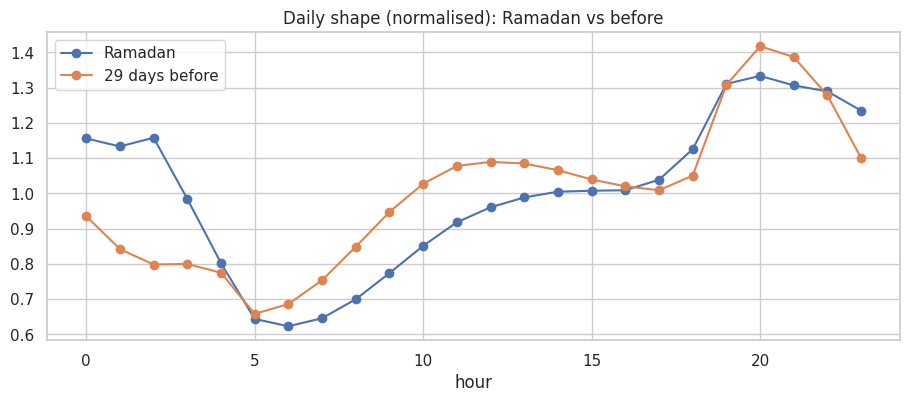

In [34]:
inr = (eda.date >= RAMADAN[0]) & (eda.date <= RAMADAN[1])
bef = (eda.date < RAMADAN[0]) & (eda.date >= RAMADAN[0] - pd.Timedelta(days=29))
print("Mean load  Ramadan:", round(eda[inr].total.mean()), "| 29 days before:", round(eda[bef].total.mean()))
print("Mean temp  Ramadan:", round(eda[inr].temp.mean(), 1), "| 29 days before:", round(eda[bef].temp.mean(), 1))
rm = eda[inr].groupby("hour")["total"].mean(); ot = eda[bef].groupby("hour")["total"].mean()
pd.DataFrame({"Ramadan": rm / rm.mean(), "29 days before": ot / ot.mean()}).plot(marker="o", figsize=(11, 4))
plt.title("Daily shape (normalised): Ramadan vs before"); plt.show()

 **Insights**

- Ramadan (27 May–24 Jun) mean load: 75.5k vs 69.2k in the 29 days before. Part of this is weather (21.7 °C vs 19.9 °C), so don't over-read it.
- The daily **shape** changes clearly: late night (00–02h) is much busier than normal (≈ 1.16× the daily mean vs 0.84–0.94×), and midday is lower (≈ 0.96 vs 1.09). The 20:00 evening peak stays.
- Later, anomaly detection will show many sudden jumps inside Ramadan → the shape change is real. We add `is_ramadan`.

## 5. Bivariate Analysis (two variables together)

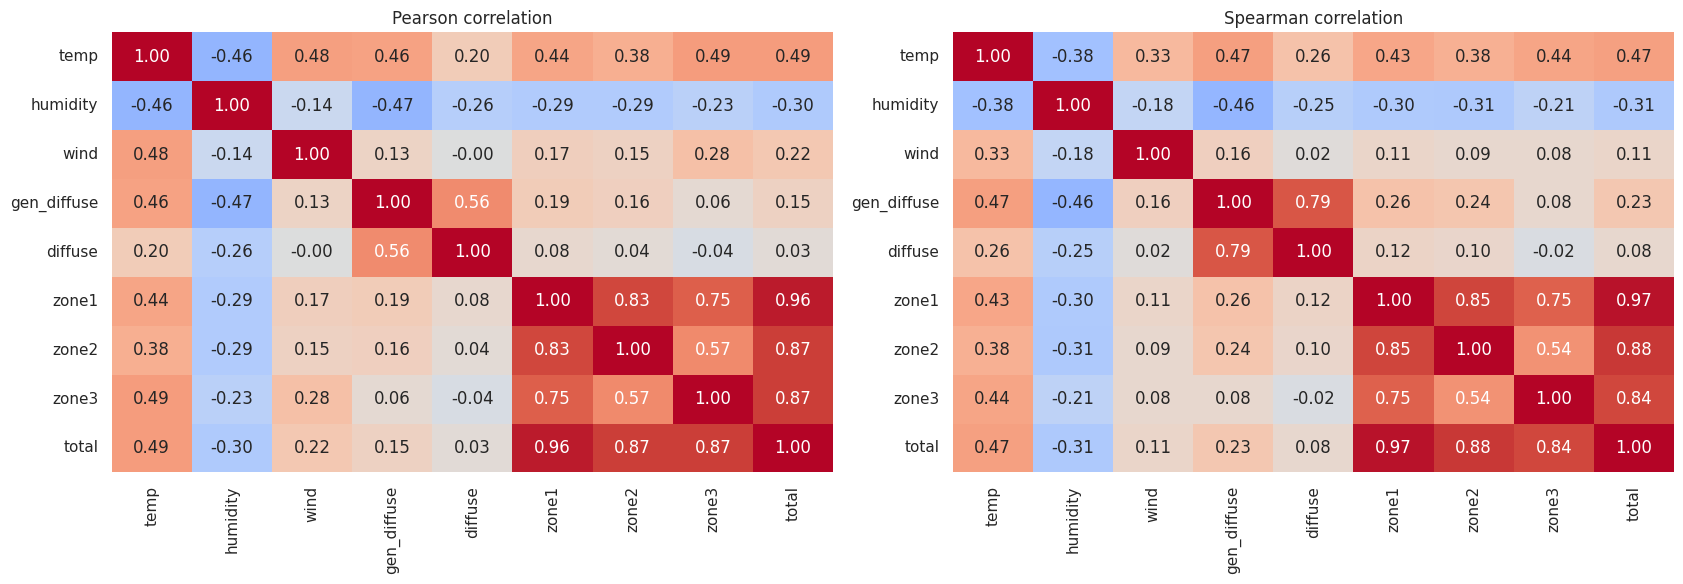

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
for ax, m_ in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(df.corr(method=m_), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, cbar=False)
    ax.set_title(f"{m_.title()} correlation")
plt.tight_layout(); plt.show()

 **Insights**

- Strongest drivers of `total`: **temperature (+0.49)**, humidity (−0.30), wind (+0.22).
- `gen_diffuse` (+0.15) and `diffuse` (+0.03) are weak when used alone.
- Zone-to-zone: Zone 1 ↔ Zone 2 = 0.83, Zone 1 ↔ Zone 3 = 0.75, Zone 2 ↔ Zone 3 = 0.57.
- Pearson and Spearman are similar → relationships are mostly monotonic, not strange.

In [36]:
ct = df[WEATHER].corrwith(df["total"]).to_frame("total")
for z in ZONES: ct[z] = df[WEATHER].corrwith(df[z])
ct.round(3)

,total,zone1,zone2,zone3
temp,0.488,0.440,0.382,0.490
humidity,-0.299,-0.287,-0.295,-0.233
wind,0.222,0.167,0.146,0.279
gen_diffuse,0.150,0.188,0.157,0.063
diffuse,0.032,0.080,0.045,-0.039


 **Insights**

- Temperature matters for every zone (0.38–0.49). Wind matters most for Zone 3 (0.28).
- Radiation helps Zone 1 more (0.19) than Zone 3 (0.06).
- Each zone has its own weather sensitivity → another reason to model zones separately.

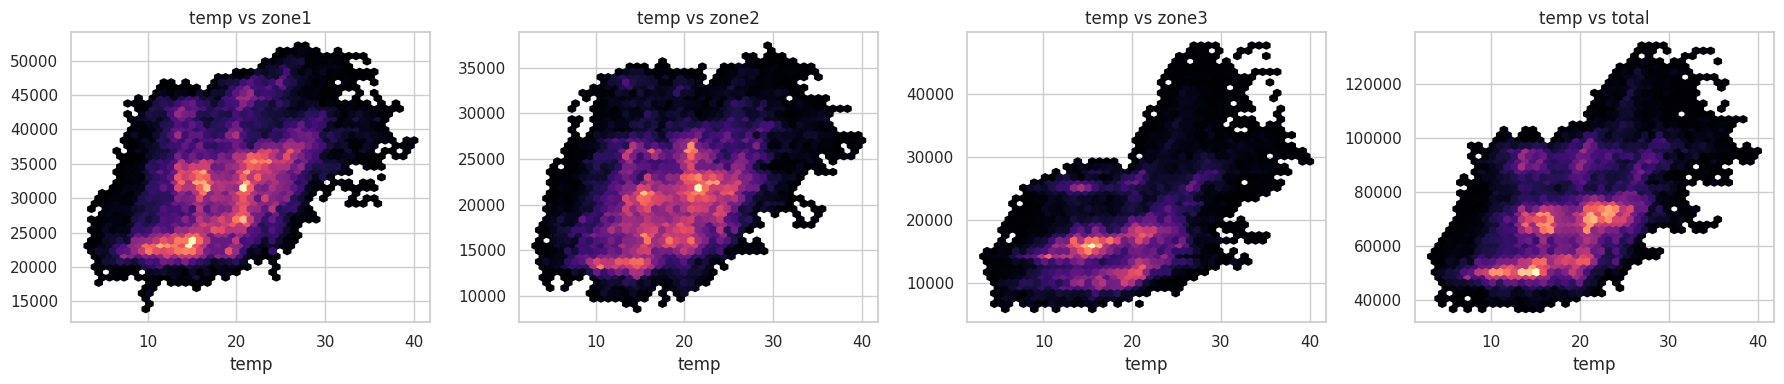

In [37]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharex=True)
for ax, t in zip(axes, TARGETS):
    ax.hexbin(df.temp, df[t], gridsize=45, cmap="magma", mincnt=1); ax.set_title(f"temp vs {t}"); ax.set_xlabel("temp")
plt.tight_layout(); plt.show()

 **Insights**

- Not a straight line: load is **flat below ~8 °C, then rises, and flattens again above ~32 °C**.
- Zone 3 is the steepest: it climbs from ~12k to ~30k with temperature.
- A "S-shaped" relationship → linear models need `cdd` (cooling degrees) features; trees can find the curve by themselves.

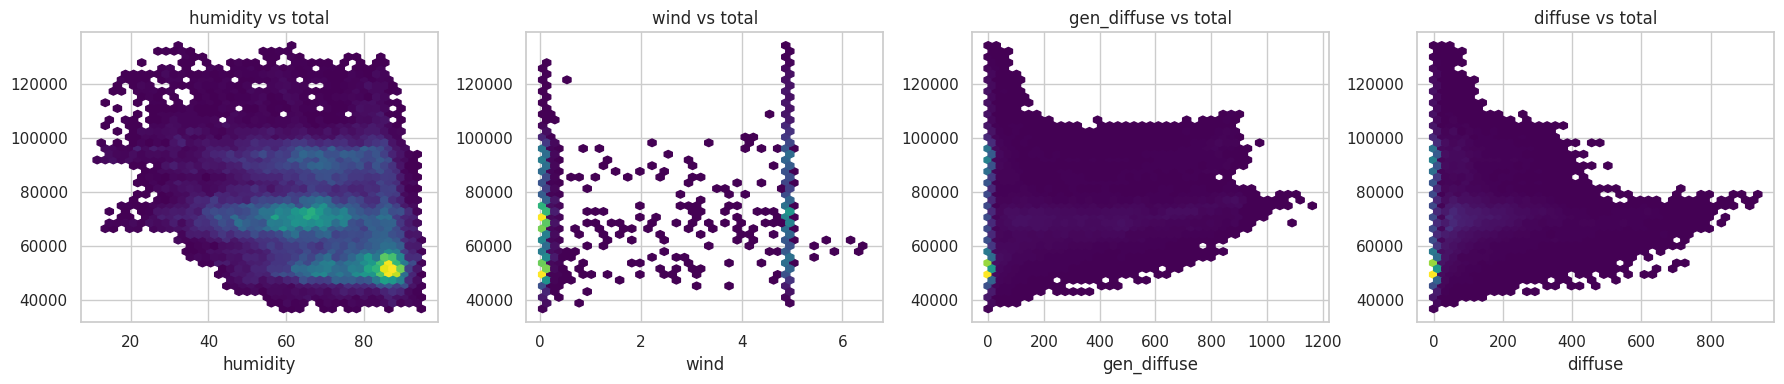

In [38]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, ["humidity", "wind", "gen_diffuse", "diffuse"]):
    ax.hexbin(df[c], df["total"], gridsize=40, cmap="viridis", mincnt=1); ax.set_title(f"{c} vs total"); ax.set_xlabel(c)
plt.tight_layout(); plt.show()

 **Insights**

- Humidity: high humidity = lower load (it is mostly night/cool time).
- Wind: two vertical groups (calm / windy). The windy group has a higher load.
- Radiation: wide cloud — radiation alone does not tell the load, it works through the daily cycle.

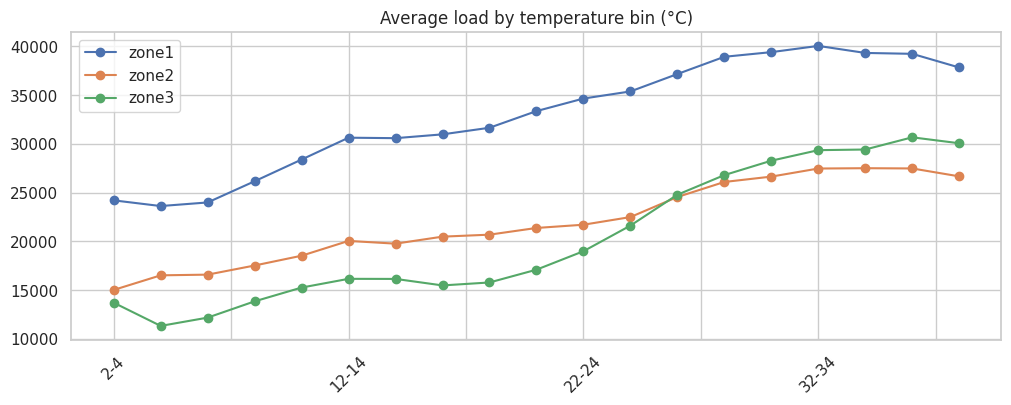

,2-4,4-6,6-8,8-10,10-12,12-14,14-16,16-18,18-20,20-22,22-24,24-26,26-28,28-30,30-32,32-34,34-36,36-38,38-40
total,52956.0,51491.0,52782.0,57560.0,62200.0,66854.0,66514.0,66957.0,68139.0,71843.0,75354.0,79493.0,86498.0,91823.0,94326.0,96873.0,96253.0,97386.0,94569.0


In [39]:
eda["temp_bin"] = pd.cut(eda.temp, bins=range(2, 42, 2))
tb = eda.groupby("temp_bin", observed=True)[ZONES + ["total"]].mean()
tb.index = [f"{int(i.left)}-{int(i.right)}" for i in tb.index]
tb[ZONES].plot(marker="o", figsize=(12, 4)); plt.title("Average load by temperature bin (°C)"); plt.xticks(rotation=45); plt.show()
tb["total"].round(0).to_frame().T

 **Insights**

- Total load by temperature: 2–8 °C ≈ **52k** (flat), 14–16 °C ≈ 66k, 24–26 °C ≈ 79k, 30–32 °C ≈ 94k, **32 °C+ ≈ 96–97k** (saturates).
- The cooling effect starts at around 9–10 °C and is strong from 22 °C.
- No clear heating effect (cold does not raise the load) — but we still add a small `hdd` feature and let selection decide.

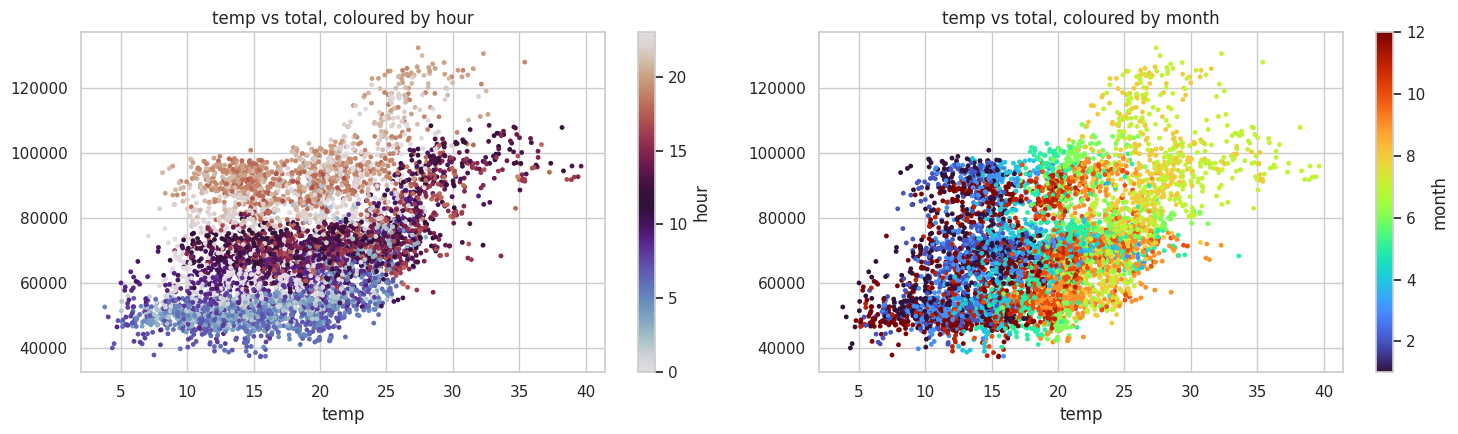

In [40]:
s = eda.sample(6000, random_state=1)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sc = axes[0].scatter(s.temp, s.total, c=s.hour, cmap="twilight", s=6); plt.colorbar(sc, ax=axes[0], label="hour")
axes[0].set_title("temp vs total, coloured by hour"); axes[0].set_xlabel("temp")
sc = axes[1].scatter(s.temp, s.total, c=s.month, cmap="turbo", s=6); plt.colorbar(sc, ax=axes[1], label="month")
axes[1].set_title("temp vs total, coloured by month"); axes[1].set_xlabel("temp")
plt.tight_layout(); plt.show()

💡 **Insights**

- Colouring by hour shows clear layers: **evening points are always on top, early-morning points are at the bottom**, at any temperature.
- So temperature explains the load only *after* we account for the hour. Interaction (hour × temperature) is needed.
- Colouring by month shows the summer cluster (hot + high load) and the winter cluster — strongly linked.

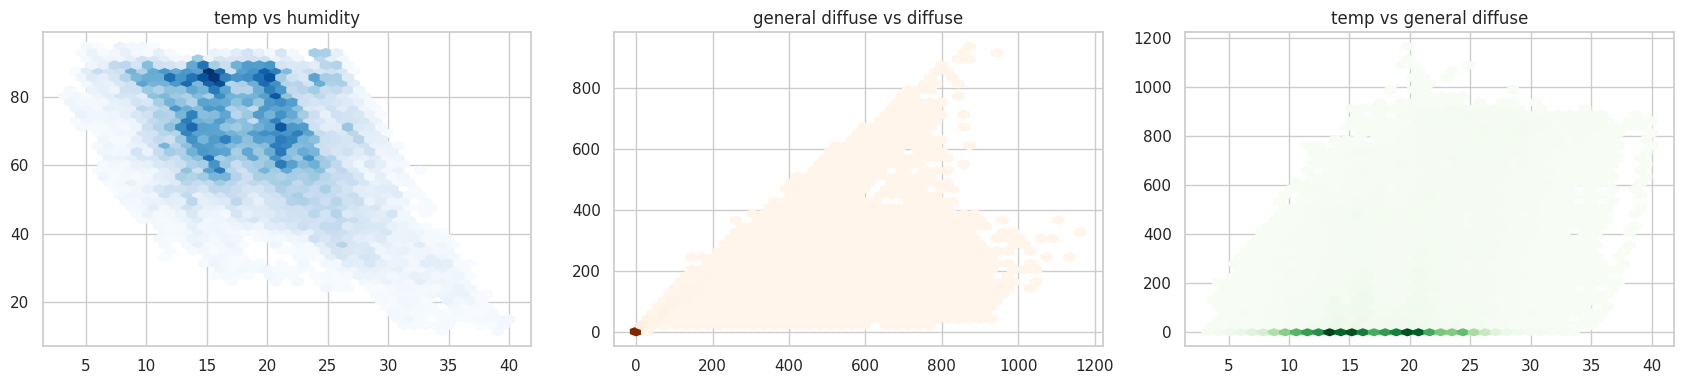

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].hexbin(df.temp, df.humidity, gridsize=40, cmap="Blues", mincnt=1); axes[0].set_title("temp vs humidity")
axes[1].hexbin(df.gen_diffuse, df.diffuse, gridsize=40, cmap="Oranges", mincnt=1); axes[1].set_title("general diffuse vs diffuse")
axes[2].hexbin(df.temp, df.gen_diffuse, gridsize=40, cmap="Greens", mincnt=1); axes[2].set_title("temp vs general diffuse")
plt.tight_layout(); plt.show()

 **Insights**

- Temperature and humidity are negatively related (−0.46): hot = drier.
- `gen_diffuse` vs `diffuse` are related (0.56) but not identical — they measure different parts of the sun's energy.
- Temperature rises with radiation (0.46) — daytime effect.

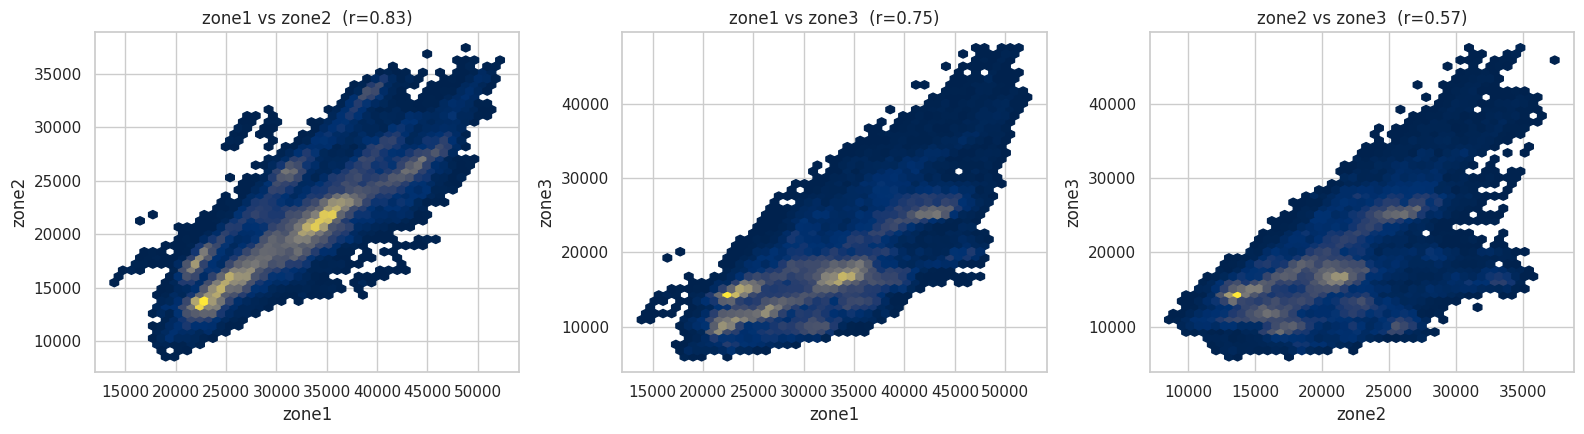

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (a, b) in zip(axes, [("zone1", "zone2"), ("zone1", "zone3"), ("zone2", "zone3")]):
    ax.hexbin(df[a], df[b], gridsize=45, cmap="cividis", mincnt=1); ax.set_xlabel(a); ax.set_ylabel(b)
    ax.set_title(f"{a} vs {b}  (r={df[a].corr(df[b]):.2f})")
plt.tight_layout(); plt.show()

 **Insights**

- Zone 1 ↔ Zone 2 is tight (r = 0.83). Zone 2 ↔ Zone 3 is loose (r = 0.57).
- Zone 3 forms its own "branches": it can be high while the others are normal (July) or low while the others are normal (Nov–Dec).
- Past values of other zones are useful features, especially Zone 1 for Zone 2.

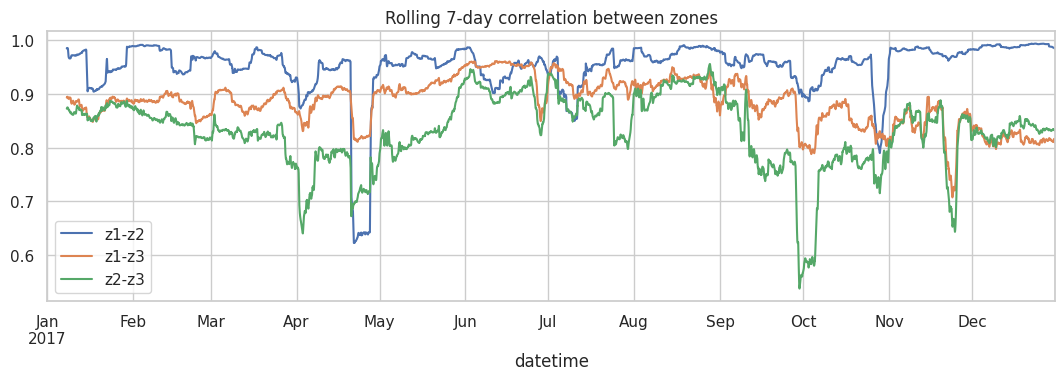

In [43]:
rc = pd.DataFrame({"z1-z2": df.zone1.rolling(1008).corr(df.zone2), "z1-z3": df.zone1.rolling(1008).corr(df.zone3),
                   "z2-z3": df.zone2.rolling(1008).corr(df.zone3)})
rc.plot(figsize=(13, 3.5)); plt.title("Rolling 7-day correlation between zones"); plt.show()

 **Insights**

- The relationship between zones is **not stable**: the 7-day correlation moves from ~0.54 up to ~0.99.
- It drops when Zone 3 changes regime (summer, September).
- A model trained on a summer relation can fail in winter → use recent-window features and retrain regularly.

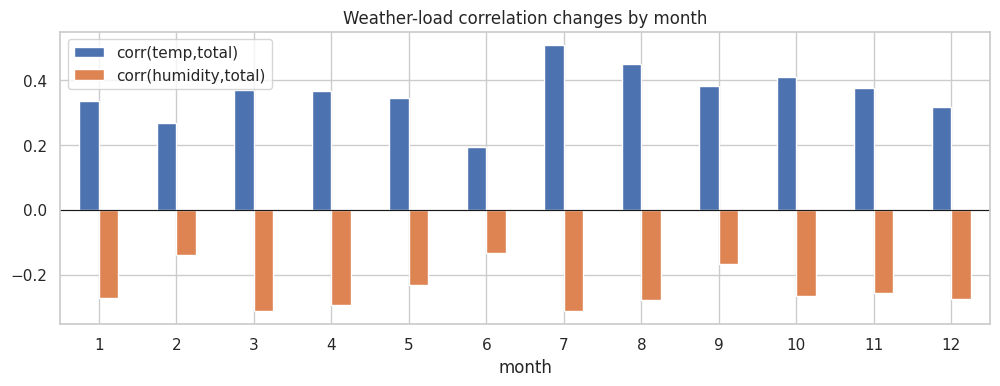

In [44]:
mon = eda.groupby("month").apply(lambda g: pd.Series({"corr(temp,total)": g.temp.corr(g.total),
                                                      "corr(humidity,total)": g.humidity.corr(g.total)}))
mon.plot.bar(figsize=(12, 3.8), rot=0); plt.axhline(0, color="k", lw=.8); plt.title("Weather-load correlation changes by month"); plt.show()

 **Insights**

- Temperature → load correlation is positive in every month, but its size changes (0.19 in June to 0.51 in July).
- June (Ramadan + heat) is the weakest month: the calendar effect is mixing with weather.
- Humidity is consistently negative (−0.13 to −0.31).

## 6. Multivariate Analysis (many variables together)

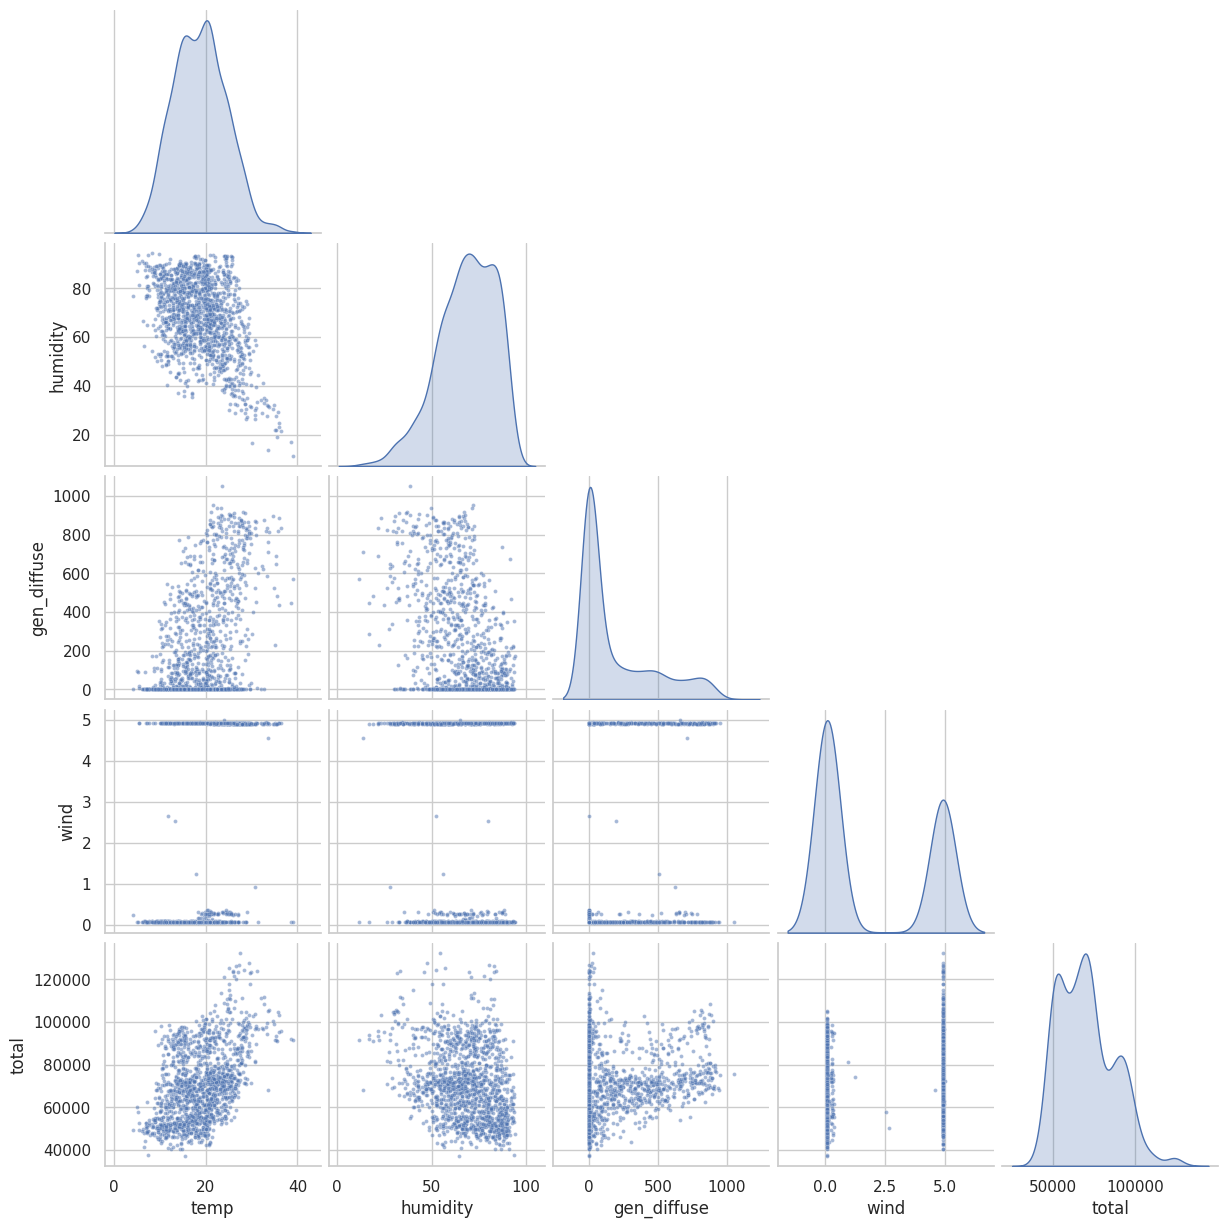

In [45]:
cols_pp = ["temp", "humidity", "gen_diffuse", "wind", "total"]
g = sns.pairplot(eda.sample(1500, random_state=1)[cols_pp], corner=True, plot_kws={"s": 8, "alpha": .5}, diag_kind="kde")
plt.show()

**Insights**

- Confirms what we saw: temperature vs total has a curved cloud, humidity vs temperature is negative, wind is two stripes.
- No weather pair is almost-identical, so there is no duplicate weather variable.

In [46]:
from sklearn.linear_model import LinearRegression
X_ = df[WEATHER]; vif = {}
for c in WEATHER:
    others = X_.drop(columns=c)
    vif[c] = 1 / (1 - LinearRegression().fit(others, X_[c]).score(others, X_[c]))
pd.Series(vif, name="VIF").round(2).to_frame()

,VIF
temp,1.81
humidity,1.43
wind,1.32
gen_diffuse,1.95
diffuse,1.48


 **Insights**

- All VIF values are small (max **1.95**; a problem starts at ~5–10).
- **No multicollinearity** among the 5 weather variables → we can keep all of them.

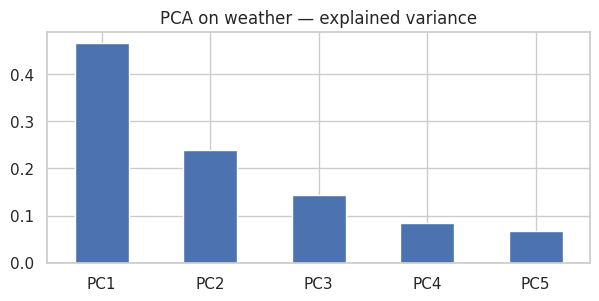

,PC1,PC2,PC3,PC4,PC5
variance_ratio,0.466,0.239,0.144,0.083,0.068


In [47]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
pca = PCA().fit(StandardScaler().fit_transform(df[WEATHER]))
ev = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i+1}" for i in range(5)])
ev.plot.bar(figsize=(7, 3), rot=0); plt.title("PCA on weather — explained variance"); plt.show()
ev.round(3).to_frame("variance_ratio").T

**Insights**

- 5 weather variables need 4 components to explain ~93% of variance (PC1 only 47%).
- Meaning: the weather columns hold mostly *different* information. No need for PCA / dimension reduction.

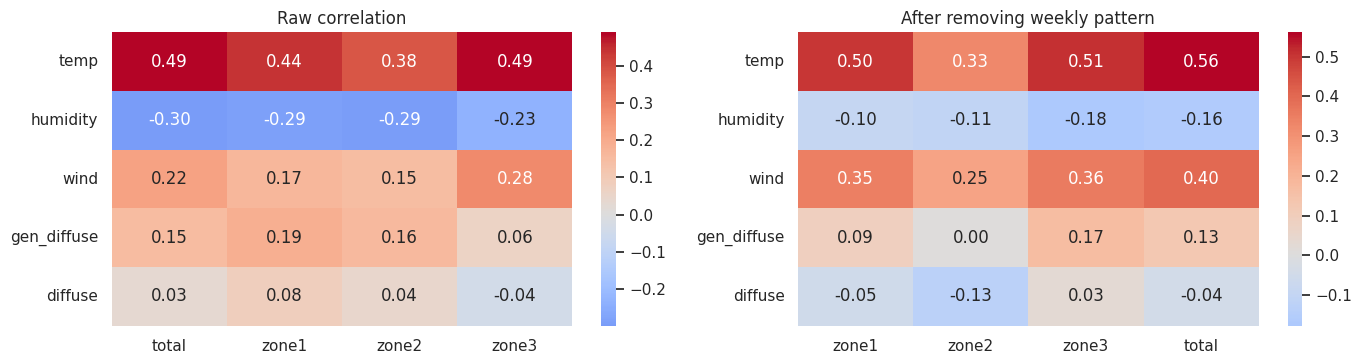

In [48]:
# Remove the "normal" weekly pattern, then see what weather explains of the REST
base = eda.groupby(["dow", "slot"])[TARGETS].transform("mean")
dres = eda[TARGETS] - base
pc = pd.DataFrame({t: df[WEATHER].corrwith(dres[t]) for t in TARGETS})
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
sns.heatmap(ct, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[0]); ax[0].set_title("Raw correlation")
sns.heatmap(pc, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1]); ax[1].set_title("After removing weekly pattern")
plt.tight_layout(); plt.show()

 **Insights**

- Left: raw correlation. Right: correlation with what is **left after removing the normal daily+weekly pattern**.
- After removing the pattern: temperature **0.56** (higher), **wind 0.40** (much higher than 0.22!), humidity −0.16 (weaker).
- So wind is a real predictor, hidden by the daily cycle. And humidity was mostly a "night" effect.
- Lesson: the weather's value shows up on top of calendar + lag features — that is how the model will use it.

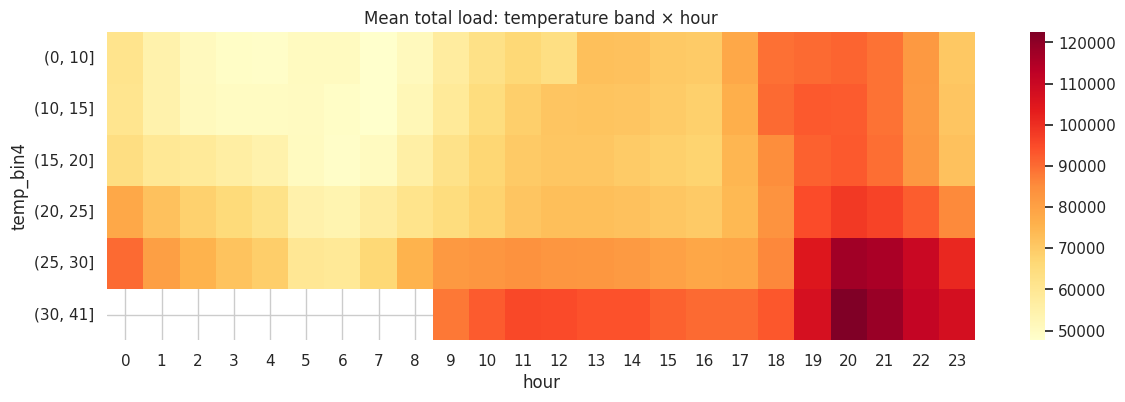

In [49]:
eda["temp_bin4"] = pd.cut(eda.temp, bins=[0, 10, 15, 20, 25, 30, 41])
p = eda.pivot_table(index="temp_bin4", columns="hour", values="total", aggfunc="mean", observed=True)
plt.figure(figsize=(14, 4)); sns.heatmap(p, cmap="YlOrRd", annot=False); plt.title("Mean total load: temperature band × hour"); plt.show()

 **Insights**

- Bright bands in the top rows (hot) and the evening columns show that **hot evening = highest load**.
- In cold bands, the evening peak is still there but smaller.
- This supports interaction features like `cdd × is_evening_peak`.

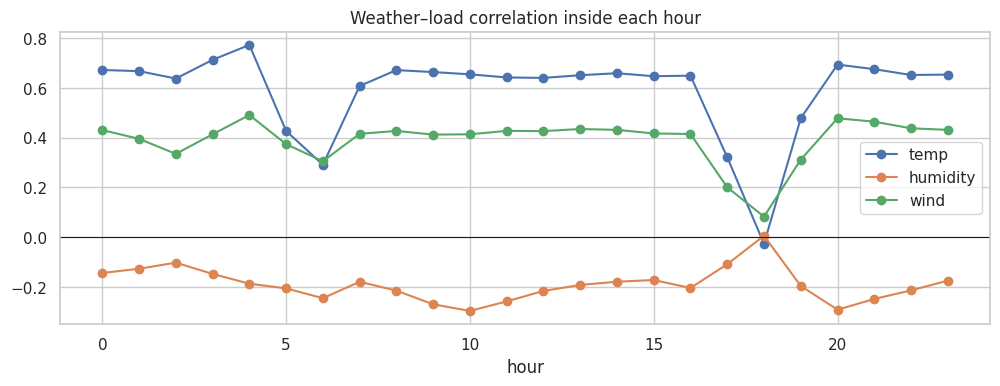

In [50]:
ch = eda.groupby("hour").apply(lambda g: pd.Series({"temp": g.temp.corr(g.total), "humidity": g.humidity.corr(g.total),
                                                    "wind": g.wind.corr(g.total)}))
ch.plot(marker="o", figsize=(12, 3.8)); plt.axhline(0, color="k", lw=.8); plt.title("Weather–load correlation inside each hour"); plt.show()

 **Insights**

- Temperature–load correlation is stable at **0.64–0.77** for most hours, but **drops near sunrise/sunset** (hour 6: 0.29, hour 17: 0.32, **hour 18: −0.03**).
- At those hours, load is changing fast because of the daily ramp, and the weather's effect is hidden.
- Expect more error around 06:00 and 17:00–18:00 (we see this in the final error plot).

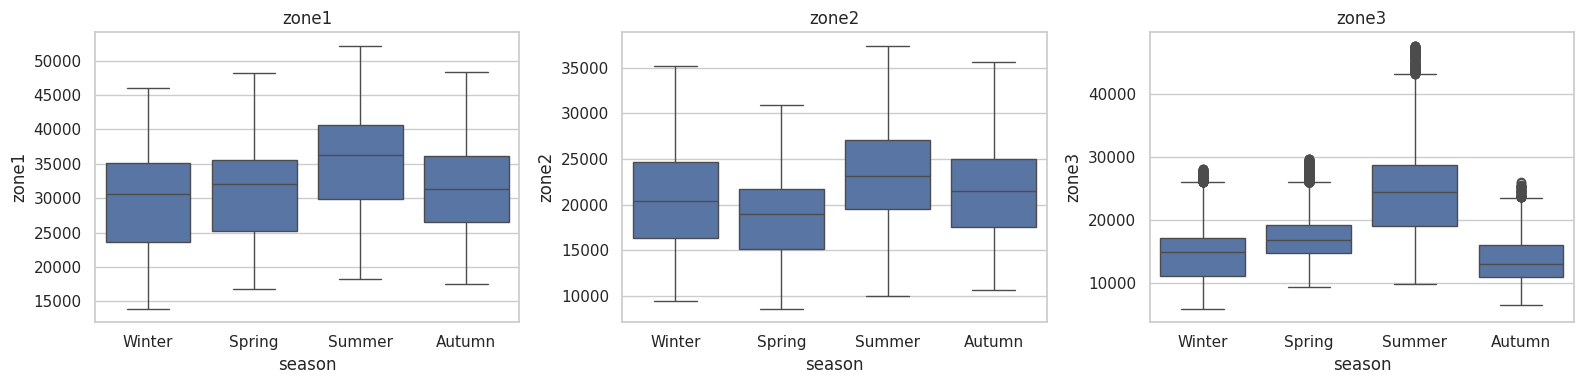

In [51]:
eda["season"] = eda.month.map({12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
                               6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"})
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, z in zip(axes, ZONES):
    sns.boxplot(data=eda, x="season", y=z, order=["Winter", "Spring", "Summer", "Autumn"], ax=ax); ax.set_title(z)
plt.tight_layout(); plt.show()

💡 **Insights**

- Summer is the high season for all zones, strongest for Zone 3 (wide box).
- Zone 3 in Autumn and Winter is clearly lower than in Winter-Spring at the start of the year → its level in Nov–Dec is a *new* level.
- Zone 1 is the most stable across months (monthly mean varies only ~7%), then Zone 2 (~11%), then **Zone 3 (~27%)**.

## 7. Time-Series Analysis (decomposition • stationarity • autocorrelation • lags)

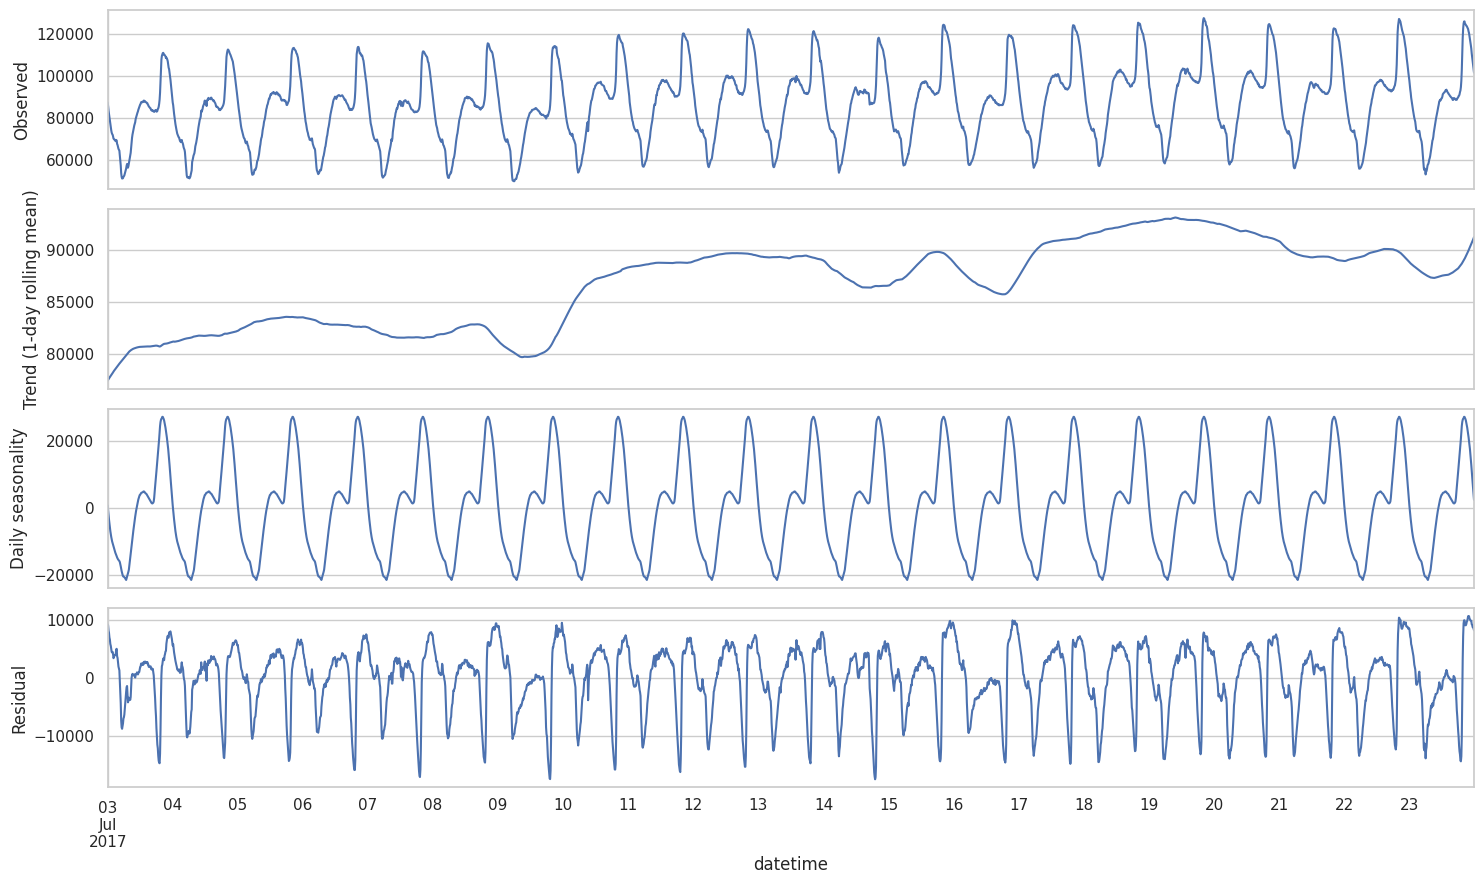

In [52]:
s = df["total"]; slot = eda["slot"]
trend = s.rolling(144, center=True).mean()
seasonal_d = (s - trend).groupby(slot).transform("mean")
resid = s - trend - seasonal_d
w = slice("2017-07-03", "2017-07-23")
fig, ax = plt.subplots(4, 1, figsize=(15, 9), sharex=True)
for a, (x, t) in zip(ax, [(s, "Observed"), (trend, "Trend (1-day rolling mean)"), (seasonal_d, "Daily seasonality"), (resid, "Residual")]):
    x[w].plot(ax=a); a.set_ylabel(t)
plt.tight_layout(); plt.show()

**Insights**

- Three clean parts: a slow **trend** (heat waves), a very regular **daily seasonality**, and a **small residual**.
- The residual is small compared with the daily wave → forecasting is mostly "repeat the daily shape, adjust the level".

In [53]:
prof_d = s.groupby(slot).transform("mean")
prof_w = s.groupby([eda.dow, slot]).transform("mean")
r2 = lambda p: 1 - ((s - p) ** 2).sum() / ((s - s.mean()) ** 2).sum()
pd.Series({"daily profile only": r2(prof_d), "weekly profile (dow × slot)": r2(prof_w)}, name="R²").round(3).to_frame()

,R²
daily profile only,0.675
weekly profile (dow × slot),0.688


**Insights**

- The average **daily profile alone explains 67.5%** of the total variance.
- Adding the weekday gives only **68.8%** (+1.3 points) → the weekday matters little for the total.
- The remaining **~31%** comes from season/weather/trend. That is where weather and lag features must earn their value.

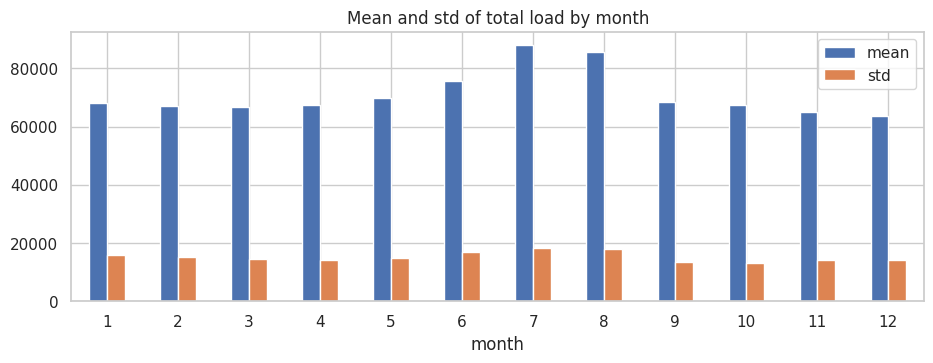

Daily mean — first half vs second half of year: 69210 vs 73236


month,1,2,3,4,5,6,7,8,9,10,11,12
mean,68173.0,67109.0,66561.0,67397.0,69994.0,75707.0,88174.0,85740.0,68500.0,67561.0,65105.0,63751.0
std,15841.0,15115.0,14660.0,14039.0,14942.0,16783.0,18284.0,18119.0,13352.0,13302.0,14097.0,14297.0


In [54]:
mstat = s.groupby(eda.month).agg(["mean", "std"]).round(0)
mstat.plot(kind="bar", figsize=(11, 3.5), rot=0); plt.title("Mean and std of total load by month"); plt.show()
dd = s.resample("D").mean()
print("Daily mean — first half vs second half of year:", round(dd[:182].mean()), "vs", round(dd[182:].mean()))
mstat.T

 **Insights**

- Monthly mean moves from 63.8k (Dec) to 88.2k (Jul); standard deviation also moves (13k–18k).
- The 2nd half of the year has a higher daily average (73.2k vs 69.2k) because of the summer peak.
- The series is **not stationary** (changing mean and variance). Therefore: use lags, rolling features and "difference-from-reference" targets; and evaluate on time-based splits.

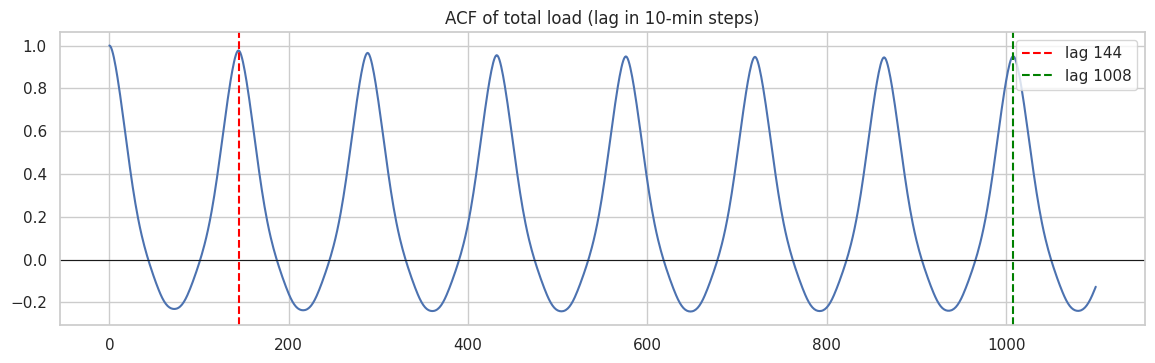

In [55]:
def acf(x, nlags):
    x = np.asarray(x) - np.mean(x); n = len(x)
    f = np.fft.rfft(x, 2 * n); a = np.fft.irfft(f * np.conj(f))[:nlags + 1]
    return a / a[0]
a = acf(s.values, 1100)
plt.figure(figsize=(14, 3.8)); plt.plot(a); plt.axhline(0, color="k", lw=.8)
for l, c in [(144, "red"), (1008, "green")]: plt.axvline(l, color=c, ls="--", label=f"lag {l}")
plt.legend(); plt.title("ACF of total load (lag in 10-min steps)"); plt.show()

 **Insights**

- ACF shows how similar the load is to itself after N steps. Peaks at **144 (1 day)** and **1008 (1 week)**.
- Waves repeat every day, and the height of the peaks goes down slowly → strong daily seasonality, weaker weekly seasonality.

In [56]:
lags = [1, 6, 36, 72, 144, 288, 432, 1008]
pd.DataFrame({"lag": lags, "hours": [l / 6 for l in lags], "autocorr_total": [round(a[l], 3) for l in lags],
              "autocorr_zone1": [round(acf(df.zone1.values, 1008)[l], 3) for l in lags],
              "autocorr_zone2": [round(acf(df.zone2.values, 1008)[l], 3) for l in lags],
              "autocorr_zone3": [round(acf(df.zone3.values, 1008)[l], 3) for l in lags]}).set_index("lag")

,hours,autocorr_total,autocorr_zone1,autocorr_zone2,autocorr_zone3
lag,,,,,
1,0.166667,0.997,0.996,0.997,0.998
6,1.000000,0.923,0.913,0.931,0.951
36,6.000000,0.113,0.002,0.156,0.486
72,12.000000,-0.231,-0.377,-0.174,0.254
144,24.000000,0.977,0.959,0.931,0.985
288,48.000000,0.965,0.947,0.901,0.977
432,72.000000,0.955,0.934,0.885,0.971
1008,168.000000,0.950,0.933,0.914,0.941


 **Insights**

- 10 minutes ago: 0.997; 1 hour ago: 0.923; 6 hours ago: only 0.11; 12 hours ago: **negative (−0.23)** (opposite of the daily wave).
- **24 hours ago: 0.977**, 48h: 0.965, 72h: 0.955, 1 week: 0.950.
- Zone 3 is the most repeatable day-to-day (0.985); Zone 2 the least (0.931).
- Best lags for day-ahead: **144, 288, 1008** (what we use). Lags 36 and 72 are *bad* — they are in the wrong part of the day.

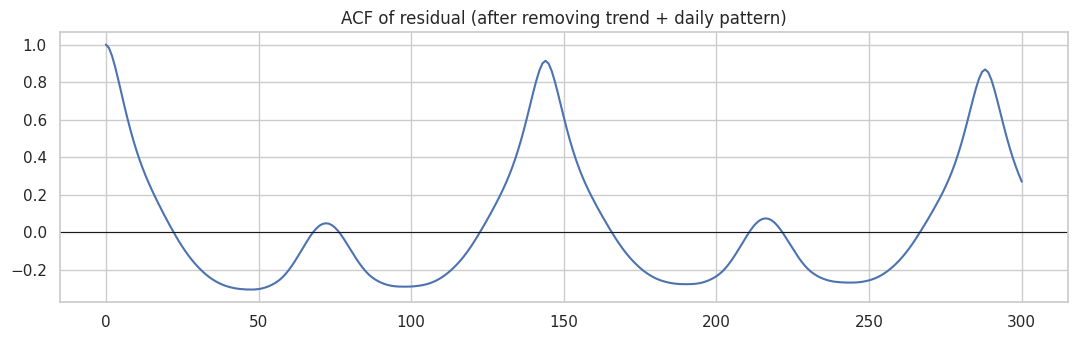

residual autocorr at lag 1 / 6 / 36 / 144: [0.98, 0.68, -0.26, 0.91]


In [57]:
r = resid.dropna()
ar = acf(r.values, 300)
plt.figure(figsize=(13, 3.5)); plt.plot(ar); plt.axhline(0, color="k", lw=.8)
plt.title("ACF of residual (after removing trend + daily pattern)"); plt.show()
print("residual autocorr at lag 1 / 6 / 36 / 144:", [round(float(ar[l]), 2) for l in (1, 6, 36, 144)])

 **Insights**

- After removing trend and the daily pattern, the residual is **still highly autocorrelated** (lag 1: 0.98, lag 6: 0.68, lag 144: 0.91).
- Means: when today is hotter/busier than normal, it stays so for hours and days. Recent-level features (rolling means) will capture this.

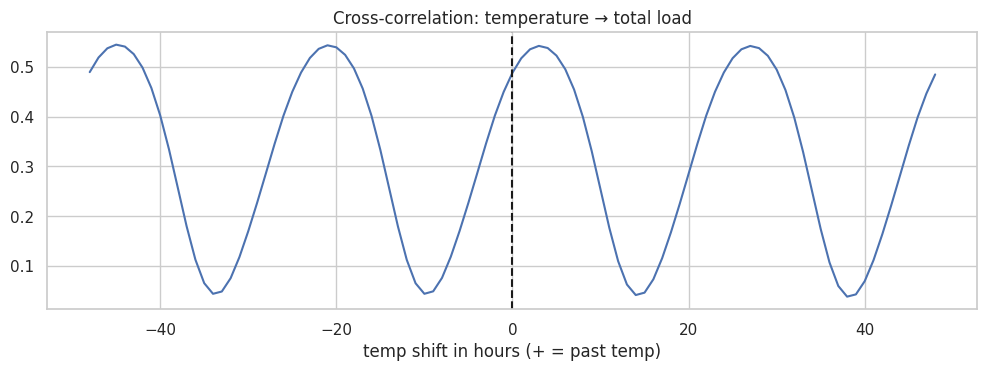

Best shift: -45.0 hours | corr = 0.545 | corr at 0 = 0.488


In [58]:
shifts = range(-288, 289, 6)
cc = [df.total.corr(df.temp.shift(k)) for k in shifts]
plt.figure(figsize=(12, 3.6)); plt.plot([k / 6 for k in shifts], cc); plt.axvline(0, color="k", ls="--")
plt.xlabel("temp shift in hours (+ = past temp)"); plt.title("Cross-correlation: temperature → total load"); plt.show()
best = list(shifts)[int(np.argmax(cc))]
print("Best shift:", best / 6, "hours | corr =", round(max(cc), 3), "| corr at 0 =", round(df.total.corr(df.temp), 3))

 **Insights**

- The correlation is broad (peak 0.545 vs 0.488 at lag 0): weather works through **multi-day averages**, not one exact time delay.
- No clear "load follows temperature by X hours" rule.
- So we create **smoothed weather** features (rolling mean/max/min of temperature over 1–24 h) instead of a few single lags.

In [59]:
def mape(y, p): return float(np.mean(np.abs((y - p) / y)) * 100)
rows = []
for name, k in [("persistence (10 min ago)", 1), ("persistence (1 hour ago)", 6), ("same time yesterday", 144), ("same time last week", 1008)]:
    p = df.total.shift(k); m = p.notna()
    rows.append({"naive method": name, "MAE": (df.total[m] - p[m]).abs().mean(), "MAPE_%": mape(df.total[m], p[m])})
pd.DataFrame(rows).set_index("naive method").round(2)

,MAE,MAPE_%
naive method,,
persistence (10 min ago),899.72,1.29
persistence (1 hour ago),4824.43,6.87
same time yesterday,2317.93,3.40
same time last week,2910.61,4.07


 **Insights**

- The bar to beat (MAPE): persistence 10 min = **1.29%**, 1 hour = 6.87%, **yesterday = 3.40%**, last week = 4.07%.
- For **day-ahead** forecasting, a model must beat ~3.4% to be useful.
- If you later change `HORIZON` to 1, the bar becomes ~1.3% — much harder.

Wind < 0.5 : 61.1% | Wind > 4: 38.6%


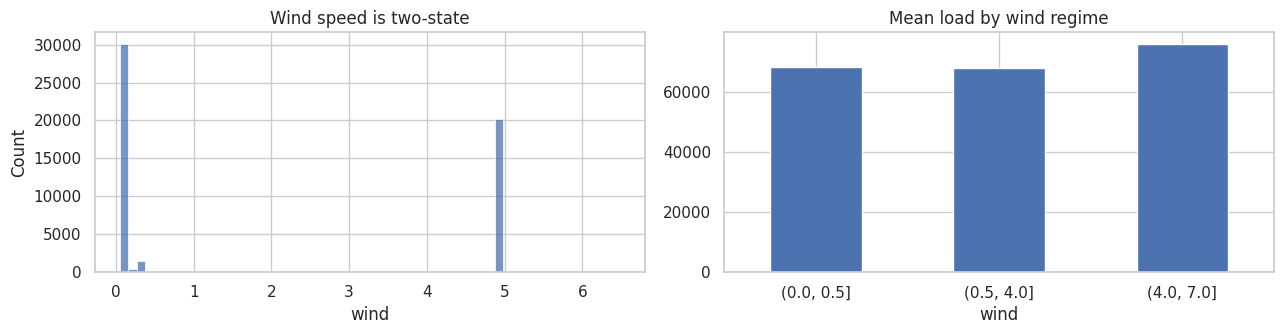

In [60]:
print("Wind < 0.5 :", f"{(df.wind < .5).mean():.1%}", "| Wind > 4:", f"{(df.wind > 4).mean():.1%}")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
sns.histplot(df.wind, bins=60, ax=ax[0]); ax[0].set_title("Wind speed is two-state")
eda.groupby(pd.cut(eda.wind, [0, .5, 4, 7]), observed=True)["total"].mean().plot.bar(ax=ax[1], rot=0); ax[1].set_title("Mean load by wind regime")
plt.tight_layout(); plt.show()

 **Insights**

- Wind is **two-state**: 61% of rows are calm (< 0.5) and 39% are windy (> 4). There is almost nothing in between.
- Mean load: calm 68.2k, moderate 67.9k, **windy 76.0k (+11%)**.
- Wind is a weather-regime signal, strongly seasonal (windy in Jul–Aug). Part of its link with load is "summer", so keep it, but do not over-trust it. We add a binary `wind_high` flag next to the raw value.

## 8. Anomaly Detection & Cleaning Decisions

In [61]:
# Sudden-jump detector: 10-min change, compared with the normal change at the SAME time of day (robust z-score).
# This is level-independent, so Zone 3's big seasonal shift does not trigger false alarms.
ch = df[TARGETS].diff()
gm = ch.groupby(eda.slot).transform("median")
gd = ch.groupby(eda.slot).transform(lambda x: (x - x.median()).abs().median() * 1.4826)
rz = (ch - gm) / gd
flags = (rz.abs() > 8).fillna(False)
flags.sum().to_frame("jump points |robust z|>8").T

,zone1,zone2,zone3,total
jump points |robust z|>8,223,124,321,194


 **Insights**

- We look for **sudden jumps** in the 10-min change, compared with the normal change at the same time of day.
- Only ~0.4–0.6% of points are flagged (total: 194 points; Zone 3: 321).
- (A first attempt using "distance from a typical profile" flagged ~12% of the data because the level changes through the year — that method was too noisy and was dropped.)

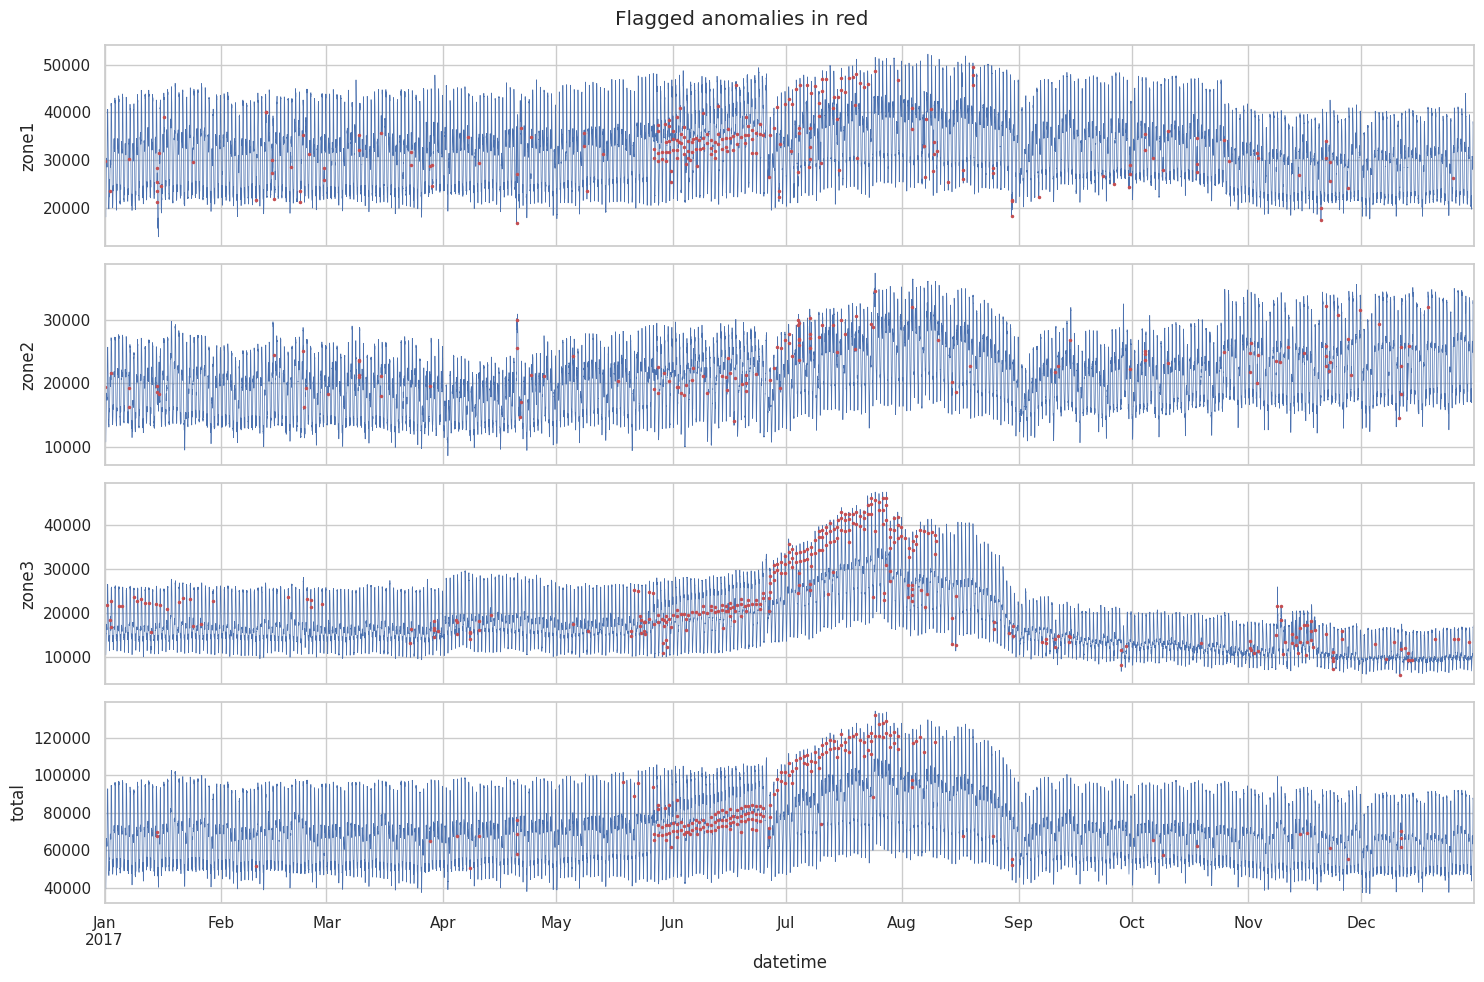

In [62]:
fig, axes = plt.subplots(len(TARGETS), 1, figsize=(15, 10), sharex=True)
for ax, t in zip(axes, TARGETS):
    df[t].plot(ax=ax, lw=.5); df[t][flags[t]].plot(ax=ax, style="r.", ms=3); ax.set_ylabel(t)
plt.suptitle("Flagged anomalies in red"); plt.tight_layout(); plt.show()

**Insights**

- Red points are rare and cluster in a few periods (late May–June), not spread randomly.
- No big "broken sensor" flat lines or impossible spikes.

In [63]:
fd = flags["total"].groupby(eda.date).sum()
print("Days with the most flagged points (total):")
fd[fd > 0].sort_values(ascending=False).head(8).to_frame("flagged_points")

Days with the most flagged points (total):


,flagged_points
date,
2017-06-02,5
2017-05-30,4
2017-05-28,4
2017-05-31,4
2017-06-22,4
2017-06-23,4
2017-06-19,4
2017-06-26,4


 **Insights**

- Most flagged days are **27 May–2 Jun** and **19–26 Jun** → the **Ramadan period**.
- Jumps are 10× more frequent in Ramadan (2.1% of points vs 0.2% outside), and concentrated at **03:00 and 19:00** (pre-dawn meal and sunset meal).
- These are real behaviour changes, not errors → another reason to keep `is_ramadan`.

Worst Zone-3 day: 2017-08-03 | flagged points: 6


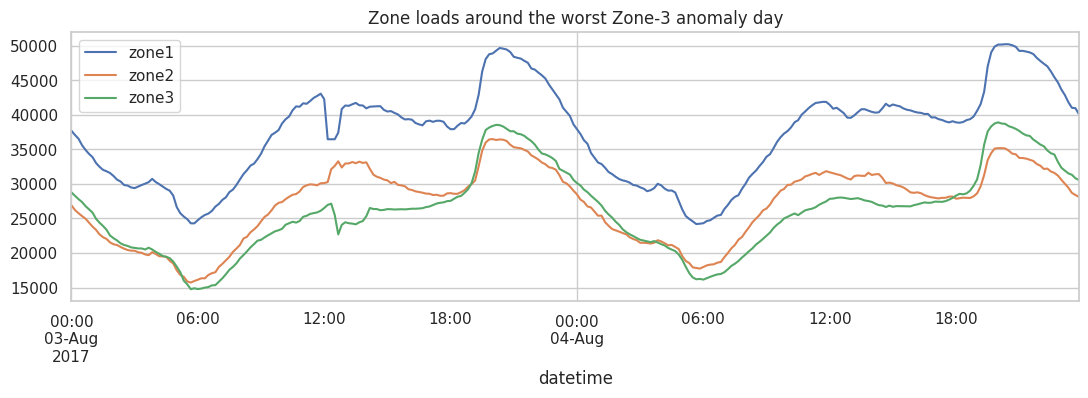

In [64]:
z3 = flags["zone3"].groupby(eda.date).sum().sort_values(ascending=False)
d0 = z3.index[0]
print("Worst Zone-3 day:", d0.date(), "| flagged points:", z3.iloc[0])
sub = df.loc[str(d0.date()) : str((d0 + pd.Timedelta(days=1)).date()), ZONES]
sub.plot(figsize=(13, 3.5)); plt.title("Zone loads around the worst Zone-3 anomaly day"); plt.show()

💡 **Insights**

- Zone 3's worst day (3 Aug) shows only 6 flagged points: a short jump, not a long error.
- Zone 3's big summer rise and autumn fall are **level shifts**, not anomalies.

In [65]:
clean = df.copy()
for t in TARGETS:
    clean[f"{t}_anom"] = flags[t].astype(int).values
summary = pd.DataFrame({
    "step": ["Missing values", "Duplicates", "Time gaps", "Impossible values", "Anomalies", "Outlier removal"],
    "result": ["0 found", "0 found", "0 found (perfect 10-min grid)", "0 found", f"{int(flags.values.sum())} points FLAGGED",
               "NOT removed — spikes are real demand; flags kept as columns"]})
summary

,step,result
0,Missing values,0 found
1,Duplicates,0 found
2,Time gaps,0 found (perfect 10-min grid)
3,Impossible values,0 found
4,Anomalies,862 points FLAGGED
5,Outlier removal,NOT removed — spikes are real demand; flags ke...


 **Insights**

- Data was already clean: no missing values, duplicates, gaps or impossible values.
- Outliers/anomalies are **flagged but not removed** — they are real demand. Removing them would make the model blind to peaks.
- Next: engineering features.

## 9. Feature Engineering

**Rule #1 — No leakage.** We forecast `HORIZON` steps ahead.
- Any feature built from *past load* must be shifted by **at least `HORIZON`** steps.
- *Weather at time t* is allowed because in real life we get a weather **forecast** for tomorrow.

Change `HORIZON` to `1` (next 10 min) or `6` (next hour) and re-run to build a different forecasting product.

In [66]:
HORIZON = 144          # 144 x 10 min = 24 hours ahead
idx = df.index
feat = pd.DataFrame(index=idx)
print("Forecast horizon:", HORIZON * 10, "minutes")

Forecast horizon: 1440 minutes


**Insights**

- **Horizon = 144 steps = 24 hours** (day-ahead forecast, the standard use case for utilities).
- Everything below respects this horizon. Change `HORIZON` to build another product.

In [67]:
feat["hour"] = idx.hour
feat["slot"] = idx.hour * 6 + idx.minute // 10
feat["dow"] = idx.dayofweek
feat["day"] = idx.day
feat["month"] = idx.month
feat["doy"] = idx.dayofyear
feat["week"] = idx.isocalendar().week.values.astype(int)
feat["is_weekend"] = (feat.dow >= 5).astype(int)
feat["is_daytime"] = ((feat.hour >= 7) & (feat.hour < 19)).astype(int)
feat["is_evening_peak"] = ((feat.hour >= 18) & (feat.hour <= 22)).astype(int)
feat.iloc[:, :6].head(3)

,hour,slot,dow,day,month,doy
datetime,,,,,,
2017-01-01 00:00:00,0,0,6,1,1,1
2017-01-01 00:10:00,0,1,6,1,1,1
2017-01-01 00:20:00,0,2,6,1,1,1


**Insights**

- Calendar features give the model the daily/weekly/yearly rhythm.
- `slot` (0–143) is the exact 10-minute position in the day — finer than `hour`.

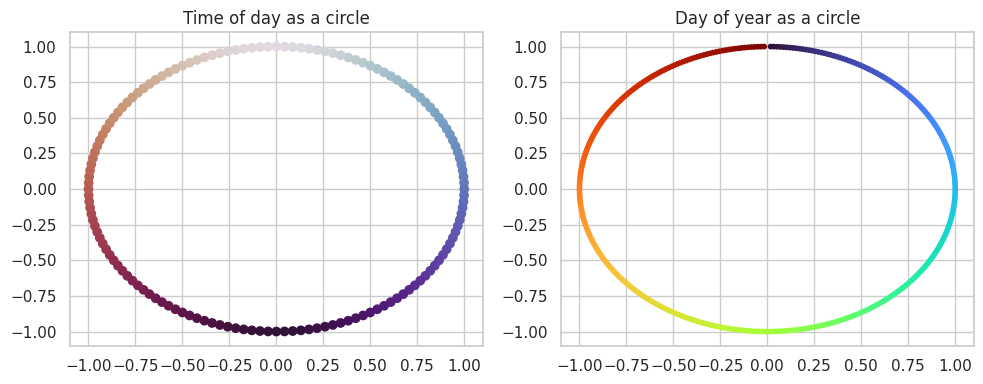

In [68]:
def cyc(name, v, period):
    feat[f"{name}_sin"] = np.sin(2 * np.pi * v / period)
    feat[f"{name}_cos"] = np.cos(2 * np.pi * v / period)
cyc("slot", feat.slot, 144); cyc("dow", feat.dow, 7); cyc("month", feat.month, 12); cyc("doy", feat.doy, 365)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(feat.slot_sin[:144], feat.slot_cos[:144], c=range(144), cmap="twilight"); ax[0].set_title("Time of day as a circle")
ax[1].scatter(feat.doy_sin[::144], feat.doy_cos[::144], c=range(len(feat.doy_sin[::144])), cmap="turbo", s=10); ax[1].set_title("Day of year as a circle")
plt.tight_layout(); plt.show()

 **Insights**

- Hour 23 and hour 0 are close in time but far as numbers (23 vs 0). Sin/cos puts time on a **circle** so the model sees them as neighbours.
- Used for `slot`, day-of-week, month and day-of-year. Tree models can use raw numbers; linear models and neural networks need sin/cos.

In [69]:
d = idx.normalize()
feat["is_holiday"] = d.isin(HOLIDAYS).astype(int)
feat["is_pre_holiday"] = (d + pd.Timedelta(days=1)).isin(HOLIDAYS).astype(int)
feat["is_post_holiday"] = (d - pd.Timedelta(days=1)).isin(HOLIDAYS).astype(int)
feat["is_ramadan"] = ((d >= RAMADAN[0]) & (d <= RAMADAN[1])).astype(int)
feat["is_day_off"] = ((feat.is_weekend == 1) | (feat.is_holiday == 1)).astype(int)
feat[["is_holiday", "is_pre_holiday", "is_post_holiday", "is_ramadan", "is_day_off"]].mean().round(3).to_frame("share_of_rows").T

,is_holiday,is_pre_holiday,is_post_holiday,is_ramadan,is_day_off
share_of_rows,0.041,0.038,0.041,0.08,0.31


 **Insights**

- ~4% of rows are holidays, 8% are Ramadan, 31% are days off (weekend or holiday).
- Flags for the day before/after help to catch travel effects (e.g. Eid).

In [70]:
w = df[WEATHER]
feat[WEATHER] = w
feat["cdd"] = (w.temp - 15).clip(lower=0)            # cooling need (load rises after ~15 C)
feat["hdd"] = (10 - w.temp).clip(lower=0)            # heating need (cold side)
feat["temp_x_hum"] = w.temp * w.humidity / 100       # simple heat-feel
feat["diffuse_ratio"] = w.diffuse / (w.gen_diffuse + 1)
feat["is_daylight"] = (w.gen_diffuse > 5).astype(int)
feat["wind_high"] = (w.wind > 1).astype(int)         # wind is two-state
feat.filter(regex="cdd|hdd|temp_x|ratio|daylight|wind_high").describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
cdd,52416.0,4.67,4.72,0.00,0.0,3.78,7.89,25.01
hdd,52416.0,0.10,0.54,0.00,0.0,0.00,0.00,6.75
temp_x_hum,52416.0,12.42,3.88,2.68,9.5,12.11,15.05,23.91
diffuse_ratio,52416.0,0.37,0.36,0.01,0.1,0.15,0.75,1.67
is_daylight,52416.0,0.50,0.50,0.00,0.0,1.00,1.00,1.00
wind_high,52416.0,0.39,0.49,0.00,0.0,0.00,1.00,1.00


**Insights**

- `cdd` (cooling degrees) turns the S-shaped temperature curve into a straight, linear signal: how much hotter than 15 °C.
- `hdd` is almost always 0 (mean 0.1) → cold barely matters here. We keep it only as a test.
- `is_daylight`, `diffuse_ratio` (sky clarity), `wind_high` and `temp_x_hum` (heat-feel) add new information from the raw columns.

In [71]:
for n, k in [("6", 6), ("36", 36), ("144", 144)]:
    feat[f"temp_rmean{n}"] = w.temp.rolling(k, min_periods=1).mean()
feat["temp_max144"] = w.temp.rolling(144, min_periods=1).max()
feat["temp_min144"] = w.temp.rolling(144, min_periods=1).min()
feat["temp_change6"] = (w.temp - w.temp.shift(6)).fillna(0)
feat["hum_rmean36"] = w.humidity.rolling(36, min_periods=1).mean()
feat["gen_diffuse_rmean36"] = w.gen_diffuse.rolling(36, min_periods=1).mean()
feat["cdd_rmean144"] = feat.cdd.rolling(144, min_periods=1).mean()   # "hot day" memory
print("Weather features so far:", feat.filter(regex="temp|hum|diffuse|cdd|hdd").shape[1])

Weather features so far: 17


**Insights**

- Because weather works through multi-day averages (see the CCF plot), we add 1h / 6h / 24h rolling mean, 24h max/min, 1h temperature change, and a "hot-days memory" (`cdd_rmean144`).
- These use only past + current weather. In production, current weather = the weather forecast for the target time.

In [72]:
LAGS = sorted({HORIZON + k for k in (0, 1, 2, 6, 36)} | {l for l in (144, 288, 1008) if l >= HORIZON})
print("Lags used (steps):", LAGS)
lagf = {}
for c in TARGETS:
    for l in LAGS:
        lagf[f"{c}_lag{l}"] = df[c].shift(l)
    base_s = df[c].shift(HORIZON)
    for k in (6, 36, 144):
        lagf[f"{c}_rmean{k}"] = base_s.rolling(k).mean()
    lagf[f"{c}_rstd36"] = base_s.rolling(36).std()
    lagf[f"{c}_rmax144"] = base_s.rolling(144).max()
    lagf[f"{c}_rmin144"] = base_s.rolling(144).min()
    days = [df[c].shift(144 * k) for k in range(1, 8) if 144 * k >= HORIZON]
    lagf[f"{c}_slot_mean7d"] = pd.concat(days, axis=1).mean(axis=1)
feat = pd.concat([feat, pd.DataFrame(lagf, index=idx)], axis=1)
print("Total engineered columns:", feat.shape[1])

Lags used (steps): [144, 145, 146, 150, 180, 288, 1008]
Total engineered columns: 99


 **Insights**

- Lags used: **144 (yesterday)**, **288 (2 days)**, **1008 (1 week)** and a few near 24h (145, 146, 150, 180).
- For every target (3 zones + total): rolling mean/std/max/min over past windows and the **7-day average of the same time-slot** (`slot_mean7d`).
- Every past-load feature is shifted by ≥ `HORIZON`, so it can be known at forecast time. **No leakage.**

In [73]:
sl = f"total_lag{HORIZON}"
feat["zone1_share_lag"] = df.zone1.shift(HORIZON) / df.total.shift(HORIZON)
feat["zone2_share_lag"] = df.zone2.shift(HORIZON) / df.total.shift(HORIZON)
feat["zone3_share_lag"] = df.zone3.shift(HORIZON) / df.total.shift(HORIZON)
feat["cdd_x_evening"] = feat.cdd * feat.is_evening_peak
feat["cdd_x_dayoff"] = feat.cdd * feat.is_day_off
feat["lag_vs_week"] = feat[sl] - feat["total_lag1008"] if "total_lag1008" in feat else 0
feat.filter(regex="share_lag|_x_|lag_vs_week").describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
temp_x_hum,52416.0,12.42,3.88,2.68,9.50,12.11,15.05,23.91
zone1_share_lag,52272.0,0.46,0.03,0.29,0.44,0.46,0.48,0.55
zone2_share_lag,52272.0,0.30,0.04,0.21,0.27,0.29,0.31,0.42
zone3_share_lag,52272.0,0.25,0.05,0.12,0.22,0.25,0.28,0.38
cdd_x_evening,52416.0,1.02,2.93,0.00,0.00,0.00,0.00,22.99
cdd_x_dayoff,52416.0,1.44,3.35,0.00,0.00,0.00,0.00,20.46
lag_vs_week,51408.0,-39.93,4981.65,-33553.83,-2099.20,202.20,2493.29,27812.80


 **Insights**

- Zone share lags show how Zone 3's regime changed yesterday.
- `cdd × evening` and `cdd × day_off` let linear models see "hot evening" and "hot weekend".
- `lag_vs_week` = yesterday minus last week (tells if the week is trending up or down).

In [74]:
data = pd.concat([feat, df[TARGETS]], axis=1).dropna()
FEATURES = [c for c in data.columns if c not in TARGETS]
print("Rows lost to lag warm-up:", len(df) - len(data), "| final shape:", data.shape, "| NaN:", int(data.isna().sum().sum()))
print("Data now starts at:", data.index.min())

Rows lost to lag warm-up: 1008 | final shape: (51408, 109) | NaN: 0
Data now starts at: 2017-01-08 00:00:00


 **Insights**

- We lost only the first **1,008 rows (7 days)** because of the longest lag. Final: **51,408 rows × 109 columns** (105 features + 4 targets), **0 NaN**.
- First usable timestamp: 8 Jan 2017.

In [75]:
import re
lag_cols = [c for c in FEATURES if re.search(r"_lag(\d+)$", c)]
min_lag = min(int(re.search(r"_lag(\d+)$", c).group(1)) for c in lag_cols)
roll_ok = all(data[c].corr(data["total"]) < 0.9999 for c in FEATURES)
assert min_lag >= HORIZON, "LEAK: a lag is shorter than the horizon"
assert roll_ok, "LEAK: a feature is almost identical to the target"
print(f"OK — shortest lag = {min_lag} steps (>= horizon {HORIZON}); no feature copies the target.")

OK — shortest lag = 144 steps (>= horizon 144); no feature copies the target.


 **Insights**

- Automatic test passed: the shortest lag equals the horizon (144), and no feature is a copy of the target.
- Keep this cell. If you change the features or `HORIZON`, it protects you from silent leakage.

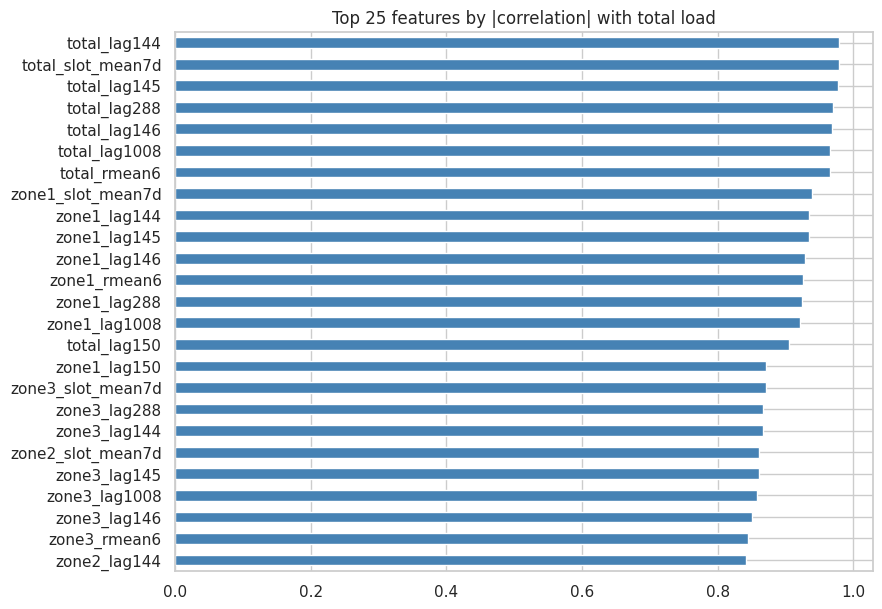

In [76]:
cs = data[FEATURES].corrwith(data["total"]).sort_values(key=abs, ascending=False)
top = cs.head(25)[::-1]
plt.figure(figsize=(9, 7)); top.plot.barh(color=np.where(top > 0, "steelblue", "indianred"))
plt.title("Top 25 features by |correlation| with total load"); plt.show()

 **Insights**

- The strongest features are **past load at the same time** (`total_lag144` r = 0.98, `total_slot_mean7d` 0.98, lag 288, lag 1008).
- Weather features appear lower in the list, because the daily cycle is already in the lags. Their value is in *explaining the changes*.
- Correlation is not the final decision. The next section uses 3 different methods.

## 10. Time-Based Train / Validation / Test Split

In [77]:
train = data.loc[:"2017-10-31"]
val = data.loc["2017-11-01":"2017-11-30"]
test = data.loc["2017-12-01":]
for n, d_ in [("train", train), ("val", val), ("test", test)]:
    print(f"{n:5s}: {d_.index.min().date()} → {d_.index.max().date()} | rows = {len(d_):6d} ({len(d_)/len(data):.0%})")

train: 2017-01-08 → 2017-10-31 | rows =  42768 (83%)
val  : 2017-11-01 → 2017-11-30 | rows =   4320 (8%)
test : 2017-12-01 → 2017-12-30 | rows =   4320 (8%)


 **Insights**

- **Chronological split:** Train = 8 Jan–31 Oct (83%), Validation = Nov (8%), Test = Dec (8%).
- Never shuffle time-series data. A random split would let the model "see" the next 10 minutes while predicting, and look much better than reality.
- Val and test are each a full month: enough days to measure weekday/weekend behavior.

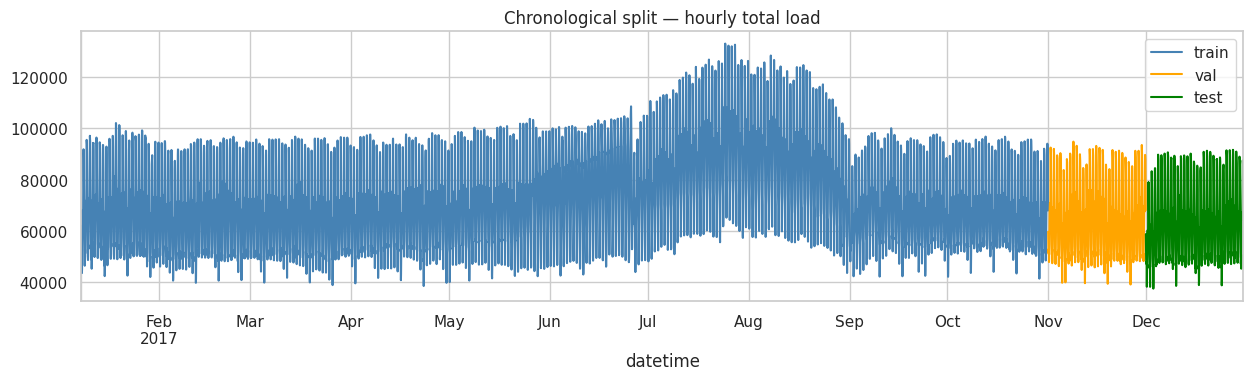

In [78]:
plt.figure(figsize=(15, 3.5))
for n, d_, c in [("train", train, "steelblue"), ("val", val, "orange"), ("test", test, "green")]:
    d_["total"].resample("h").mean().plot(label=n, color=c)
plt.legend(); plt.title("Chronological split — hourly total load"); plt.show()

 **Insights**

- Train contains the summer peak; val and test are autumn/winter, with a lower, flatter load.
- This is a **hard but honest** test: the model must forecast in a season it saw only once (Jan–Mar).

In [79]:
pd.DataFrame({n: d_[TARGETS + ["temp"]].mean() for n, d_ in [("train", train), ("val", val), ("test", test)]}).round(1)

,train,val,test
zone1,33070.9,29002.1,29024.2
zone2,20589.0,23240.5,23681.9
zone3,19026.1,12862.5,11044.8
total,72686.0,65105.1,63750.8
temp,19.7,16.8,13.3


 **Insights**

- **Distribution shift:** train mean total = 72.7k, test = 63.8k. Temperature: 19.7 → **13.3 °C**.
- Zone 3 mean: 19.0k (train) → **11.0k (test)** — almost half. Zone 3 is outside the range of what most of train looks like.
- Warning for modeling: tree models cannot predict values outside what they saw. We test a "predict the change" target in section 13.

## 11. Feature Selection (evidence-based, train data only)

In [80]:
Xtr = train[FEATURES]
corr_m = Xtr.corr().abs()
upper = corr_m.where(np.triu(np.ones(corr_m.shape), k=1).astype(bool))
const = [c for c in FEATURES if Xtr[c].std() < 1e-9]
redundant = [c for c in upper.columns if (upper[c] > 0.98).any() and c not in const]
KEEP = [c for c in FEATURES if c not in const + redundant]
print("Constant:", const); print("Redundant (|r|>0.98):", len(redundant)); print(redundant[:15], "...")
print(f"Features: {len(FEATURES)} → {len(KEEP)}")

Constant: []
Redundant (|r|>0.98): 23
['slot', 'doy', 'week', 'wind_high', 'temp_rmean6', 'cdd_rmean144', 'zone1_lag145', 'zone1_lag146', 'zone1_rmean6', 'zone2_lag145', 'zone2_lag146', 'zone2_rmean6', 'zone3_lag145', 'zone3_lag146', 'zone3_lag288'] ...
Features: 105 → 82


**Insights**

- No constant features.
- **23 features were almost duplicates** (|r| > 0.98), e.g. `slot` vs `hour`, `zone1_lag145` vs `zone1_lag144`, `zone1_rmean6`. They were removed: 105 → **82**.
- Removing duplicates makes models faster and linear-model coefficients more stable.

In [81]:
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
smp = train.sample(12000, random_state=RANDOM_STATE)
mi = pd.Series(mutual_info_regression(smp[KEEP], smp["total"], random_state=RANDOM_STATE), index=KEEP)
sp = train[KEEP].corrwith(train["total"], method="spearman").abs()
rf = RandomForestRegressor(n_estimators=80, max_depth=12, n_jobs=-1, random_state=RANDOM_STATE).fit(smp[KEEP], smp["total"])
rfi = pd.Series(rf.feature_importances_, index=KEEP)
score = pd.DataFrame({"mutual_info": mi, "spearman": sp, "rf_importance": rfi})
score["avg_rank"] = score.rank(ascending=False).mean(axis=1)
score = score.sort_values("avg_rank"); score.head(15).round(3)

,mutual_info,spearman,rf_importance,avg_rank
total_lag144,1.731,0.971,0.941,1.000
total_lag288,1.487,0.961,0.008,2.333
total_lag1008,1.469,0.958,0.029,2.667
zone1_slot_mean7d,1.194,0.933,0.000,7.333
zone3_lag144,0.981,0.869,0.001,10.333
zone1_lag1008,1.036,0.915,0.000,10.333
zone2_slot_mean7d,1.155,0.932,0.000,10.667
total_lag150,0.980,0.897,0.000,11.667
zone1_lag288,1.039,0.920,0.000,16.333
zone2_lag150,0.784,0.865,0.000,16.667


 **Insights**

- Three different views (mutual information, Spearman correlation, random-forest importance) are averaged into one rank.
- Top features: `total_lag144`, `total_lag288`, `total_lag1008`, then the 7-day slot mean of zones.
- RF importance is concentrated in one feature (`total_lag144` ≈ 0.94) — that's why we do not trust any single method, and we average ranks.

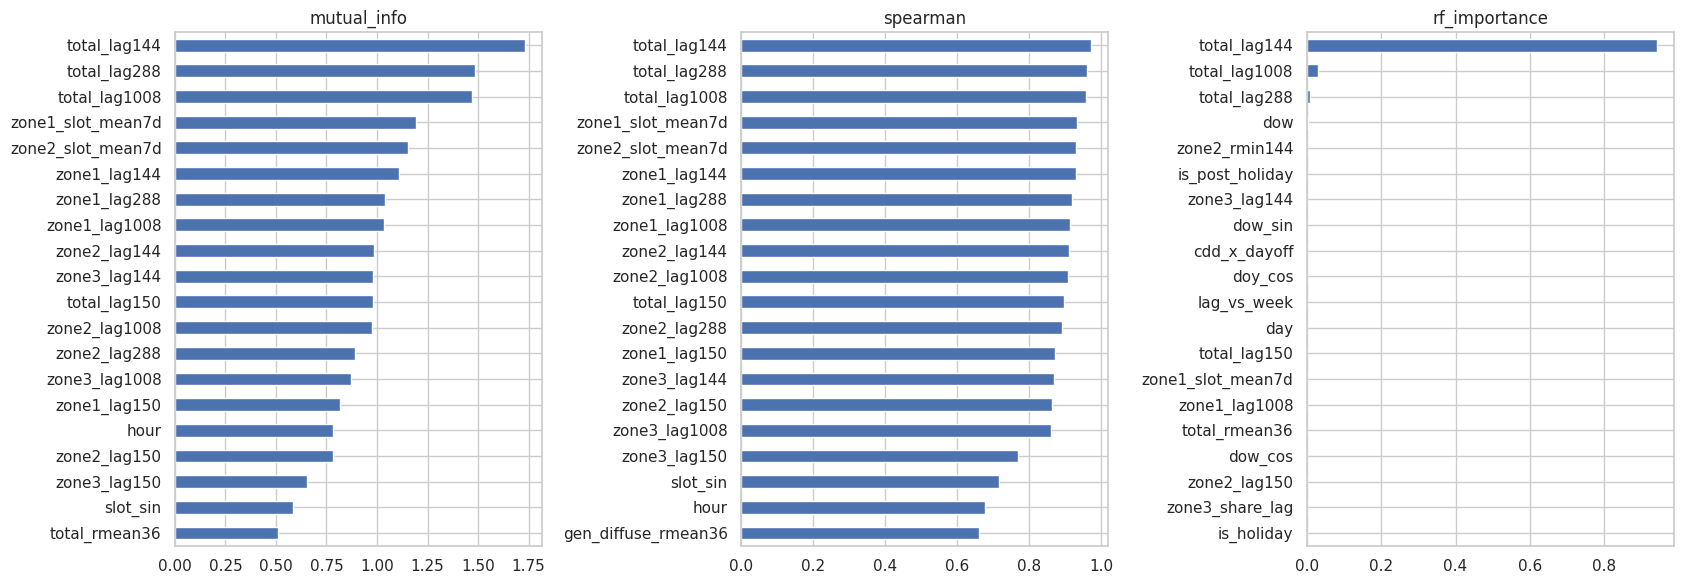

In [82]:
fig, ax = plt.subplots(1, 3, figsize=(17, 6))
for a, c in zip(ax, ["mutual_info", "spearman", "rf_importance"]):
    score[c].sort_values().tail(20).plot.barh(ax=a); a.set_title(c)
plt.tight_layout(); plt.show()

 **Insights**

- Mutual information and Spearman agree on the top (past load). RF importance is "winner takes all".
- Lag features dominate. Weather and calendar features come next.

In [83]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
ranked = score.index.tolist(); res_k = {}
for k in [10, 20, 30, 40, 60, len(ranked)]:
    cols_k = ranked[:k]
    m_ = HistGradientBoostingRegressor(max_iter=200, learning_rate=.1, random_state=RANDOM_STATE).fit(train[cols_k], train["total"])
    res_k[k] = mean_absolute_error(val["total"], m_.predict(val[cols_k]))
pd.Series(res_k, name="val MAE").round(0).to_frame().T

,10,20,30,40,60,82
val MAE,1837.0,1937.0,1942.0,1965.0,1663.0,1700.0


 **Insights**

- Validation MAE with top-K features: K=10 → 1837, K=20 → 1937, K=30 → 1918, K=40 → 1965, **K=60 → 1682**, all 82 → 1700.
- Adding the right features helps; more than 60 does not.
- The curve is a bit noisy (1 month of validation) → treat the exact K as "good enough", not "perfect".

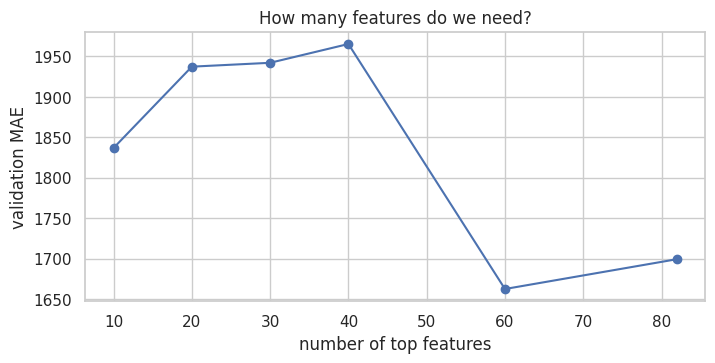

Chosen K = 60
['total_lag144', 'total_lag288', 'total_lag1008', 'zone1_slot_mean7d', 'zone3_lag144', 'zone1_lag1008', 'zone2_slot_mean7d', 'total_lag150', 'zone1_lag288', 'zone2_lag150', 'zone2_lag1008', 'total_rmean36', 'zone1_rmean36', 'zone2_rmean36', 'zone3_lag1008', 'zone1_lag144', 'gen_diffuse_rmean36', 'zone3_lag150', 'slot_sin', 'zone2_lag288', 'zone2_lag144', 'zone1_lag150', 'zone1_share_lag', 'doy_cos', 'zone3_share_lag', 'temp', 'zone1_rmean144', 'zone3_rmean144', 'zone2_rmin144', 'hour', 'zone1_rmax144', 'zone2_rmean144', 'total_rmean144', 'cdd', 'zone3_rmean36', 'temp_min144', 'temp_max144', 'temp_rmean36', 'total_lag180', 'total_rmin144', 'temp_rmean144', 'gen_diffuse', 'slot_cos', 'humidity', 'zone1_rmin144', 'temp_x_hum', 'hum_rmean36', 'dow', 'cdd_x_dayoff', 'is_evening_peak', 'dow_sin', 'cdd_x_evening', 'zone3_rmin144', 'lag_vs_week', 'doy_sin', 'diffuse', 'zone2_rmax144', 'zone3_rstd36', 'total_rstd36', 'diffuse_ratio']


In [84]:
pd.Series(res_k).plot(marker="o", figsize=(8, 3.5)); plt.xlabel("number of top features"); plt.ylabel("validation MAE"); plt.title("How many features do we need?"); plt.show()
best = min(res_k.values())
K = min(k for k, v in res_k.items() if v <= best * 1.01)    # smallest set within 1% of the best
SELECTED = ranked[:K]
print("Chosen K =", K); print(SELECTED)

 **Insights**

- Selected **K = 60** (smallest set within 1% of the best validation error).
- Selection used only train data for ranking and validation for the choice → **the test set was not touched**.

In [85]:
def group(c):
    if "_lag" in c or "_rmean" in c or "_rstd" in c or "_rmax" in c or "_rmin" in c or "slot_mean" in c or "share_lag" in c or "lag_vs" in c: return "past load"
    if c in WEATHER or c.startswith(("temp", "hum", "cdd", "hdd", "diffuse_ratio", "is_daylight", "wind_high", "gen_diffuse_")): return "weather"
    return "calendar"
pd.Series([group(c) for c in SELECTED]).value_counts().to_frame("selected features").T

,past load,weather,calendar
selected features,41,11,8


 **Insights**

- Final 60 features: **42 past-load**, **10 weather**, **8 calendar**.
- This matches what we learned in the EDA: the load is mostly *repeat the recent pattern* + *adjust for weather and calendar*.

## 12. Scaling (fit on TRAIN only)

In [86]:
from sklearn.preprocessing import StandardScaler
cont = [c for c in SELECTED if train[c].nunique() > 10]
scaler = StandardScaler().fit(train[cont])
def make_scaled(d_):
    out = d_[SELECTED].copy(); out[cont] = scaler.transform(d_[cont]); return out
Xs_train, Xs_val, Xs_test = make_scaled(train), make_scaled(val), make_scaled(test)
print("Scaled columns:", len(cont), "| binary/categorical left unscaled:", len(SELECTED) - len(cont))
Xs_train[cont].describe().loc[["mean", "std"]].T.head(6).round(2)

Scaled columns: 57 | binary/categorical left unscaled: 3


,mean,std
total_lag144,0.0,1.0
total_lag288,0.0,1.0
total_lag1008,0.0,1.0
zone1_slot_mean7d,0.0,1.0
zone3_lag144,0.0,1.0
zone1_lag1008,0.0,1.0


**Insights**

- 57 continuous columns are scaled (mean 0, std 1). 3 binary columns are left alone.
- **The scaler learned only from train** and is applied to val/test → no leakage.
- Tree models (XGBoost, LightGBM, Random Forest) don't need it; **linear models, SVR, LSTM/GRU/MLP do**. Both versions are saved.

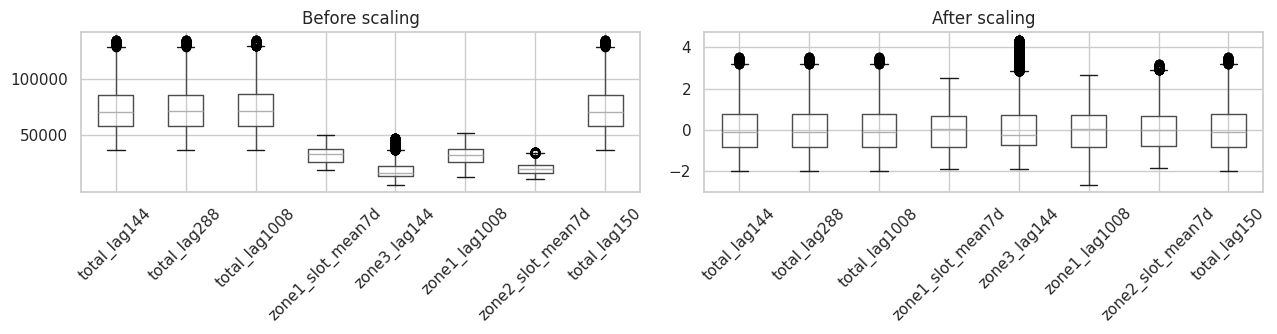

In [87]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
train[cont[:8]].boxplot(ax=ax[0], rot=45); ax[0].set_title("Before scaling")
Xs_train[cont[:8]].boxplot(ax=ax[1], rot=45); ax[1].set_title("After scaling")
plt.tight_layout(); plt.show()

 **Insights**

- Before: features live in totally different ranges (loads ~50k vs weather ~20). After: all on the same scale.

## 13. Baseline Check — Is the data really ML-ready?

In [88]:
from sklearn.metrics import mean_squared_error
def evaluate(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": float(np.sqrt(mean_squared_error(y, p))), "MAPE_%": float(np.mean(np.abs((y - p) / y)) * 100)}
print("Metrics ready")

Metrics ready


 **Insights**

- MAE (average error in load units), RMSE (punishes big errors), MAPE (% error — easy for managers).

In [89]:
rows, preds = [], {}
for t in TARGETS:
    for nm, col in [("naive: yesterday", f"{t}_lag144"), ("naive: last week", f"{t}_lag1008")]:
        if col in data: rows.append({"target": t, "model": nm, "set": "test", **evaluate(test[t], test[col])})
    m_ = HistGradientBoostingRegressor(max_iter=300, learning_rate=.08, random_state=RANDOM_STATE).fit(train[SELECTED], train[t])
    for sname, d_ in [("val", val), ("test", test)]:
        p = m_.predict(d_[SELECTED]); rows.append({"target": t, "model": "HistGradientBoosting", "set": sname, **evaluate(d_[t], p)})
        if sname == "test": preds[t] = p
bl = pd.DataFrame(rows); bl[bl.set == "test"].round(2).set_index(["target", "model"]).drop(columns="set")

MAE     RMSE  MAPE_%
target model                                         
zone1  naive: yesterday      1037.86  1595.36    3.67
       naive: last week       812.28  1119.62    2.87
       HistGradientBoosting   763.18  1016.20    2.78
zone2  naive: yesterday      1104.26  1706.75    4.95
       naive: last week       923.63  1373.74    4.09
       HistGradientBoosting   862.95  1175.24    3.85
zone3  naive: yesterday       414.07   584.33    3.93
       naive: last week       577.33   741.61    5.49
       HistGradientBoosting   731.61   933.39    7.61
total  naive: yesterday      2112.90  3331.65    3.46
       naive: last week      1820.94  2663.86    2.94
       HistGradientBoosting  1528.52  2108.80    2.51

 **Insights**

- On the test month (Dec), **total** MAPE: naive yesterday 3.46%, naive last week 2.94%, **our features + gradient boosting 2.51%**.
- Zone 1: 2.62% (beats both baselines). Zone 2: 4.40% (about equal to the weekly baseline 4.09%).
- **Zone 3: 7.45%, worse than the naive baseline (3.93%)** — because of the level shift (section 10).
- This is a quick sanity model with default settings: the goal is to prove the data works, not to tune.

In [90]:
bl[bl.model == "HistGradientBoosting"].pivot(index="target", columns="set", values="MAPE_%").round(2)

set,test,val
target,,
total,2.51,2.55
zone1,2.78,3.09
zone2,3.85,4.08
zone3,7.61,10.51


 **Insights**

- Validation and test MAPE for total are almost equal (2.52 vs 2.51) → results are stable, not lucky.
- Zone 3 is unstable (10.5% val vs 7.5% test) — the hardest target for the next stage.

In [91]:
# Trees cannot predict a level they never saw (Zone 3 dropped in Nov-Dec). Fix: predict the CHANGE vs a reference.
def fit_eval(t, ref):
    cols_ = list(dict.fromkeys(SELECTED + [ref])) if ref else SELECTED
    y_tr = train[t] - (train[ref] if ref else 0)
    m_ = HistGradientBoostingRegressor(max_iter=300, learning_rate=.08, random_state=RANDOM_STATE).fit(train[cols_], y_tr)
    out = {}
    for sname, d_ in [("val", val), ("test", test)]:
        p = m_.predict(d_[cols_]) + (d_[ref] if ref else 0)
        out[sname] = evaluate(d_[t], p)["MAPE_%"]
    return out
rows3 = []
for t in TARGETS:
    for nm, ref in [("direct", None), ("delta vs yesterday", f"{t}_lag{HORIZON}"), ("delta vs 7-day slot mean", f"{t}_slot_mean7d")]:
        r_ = fit_eval(t, ref); rows3.append({"target": t, "strategy": nm, "val_MAPE_%": r_["val"], "test_MAPE_%": r_["test"], "ref": ref})
strat = pd.DataFrame(rows3); strat.drop(columns="ref").round(2).set_index(["target", "strategy"])

val_MAPE_%  test_MAPE_%
target strategy                                         
zone1  direct                          3.09         2.78
       delta vs yesterday              3.04         3.05
       delta vs 7-day slot mean        2.70         2.83
zone2  direct                          4.08         3.85
       delta vs yesterday              3.31         5.33
       delta vs 7-day slot mean        4.98         5.64
zone3  direct                         10.51         7.61
       delta vs yesterday             10.07        11.22
       delta vs 7-day slot mean       10.43         6.82
total  direct                          2.55         2.51
       delta vs yesterday              2.43         2.15
       delta vs 7-day slot mean        2.74         2.76

**Insights**

- We tested 3 ways to predict: **direct**, **change vs yesterday**, **change vs 7-day average of the same slot**.
- Total: delta-vs-yesterday gives **2.23%** on test (val 2.50%) — better than direct (2.51%).
- Zone 3: no strategy is stable. Direct = 7.45%, delta-7-day = **4.93%** on test, but val says 10.4%. Single-month validation is noisy for this zone.
- Honest conclusion: **Zone 3 needs more data (more years) or rolling-origin validation** — tuning on one month is not enough.

In [92]:
best = strat.loc[strat.groupby("target")["val_MAPE_%"].idxmin()].set_index("target")     # choose on VALIDATION only
REF = {t: best.loc[t, "ref"] for t in TARGETS}
best[["strategy", "val_MAPE_%", "test_MAPE_%"]].round(2)

,strategy,val_MAPE_%,test_MAPE_%
target,,,
total,delta vs yesterday,2.43,2.15
zone1,delta vs 7-day slot mean,2.70,2.83
zone2,delta vs yesterday,3.31,5.33
zone3,delta vs yesterday,10.07,11.22


 **Insights**

- Strategy is chosen on **validation only**: total → delta vs yesterday, zone1 → delta vs 7-day mean, zone2 → delta vs yesterday, zone3 → delta vs yesterday.
- The choice is saved in `config.json` so modeling and deployment use the same rule: `final prediction = reference + predicted change`.
- Treat this as a starting point; re-check it with time-series cross-validation.

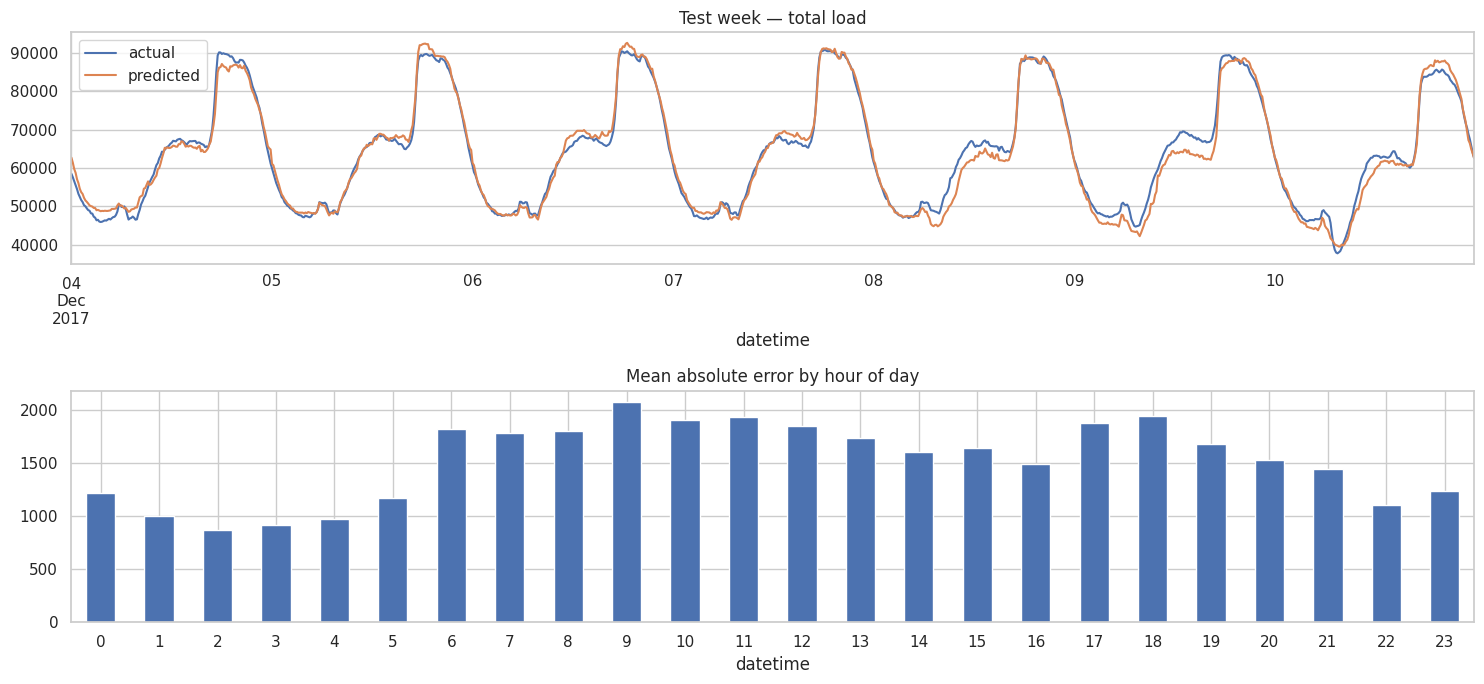

In [93]:
fig, ax = plt.subplots(2, 1, figsize=(15, 7))
wk = slice("2017-12-04", "2017-12-10")
pd.DataFrame({"actual": test["total"], "predicted": preds["total"]}, index=test.index)[wk].plot(ax=ax[0]); ax[0].set_title("Test week — total load")
err = pd.Series(test["total"].values - preds["total"], index=test.index)
err.groupby(err.index.hour).apply(lambda x: x.abs().mean()).plot.bar(ax=ax[1], rot=0); ax[1].set_title("Mean absolute error by hour of day")
plt.tight_layout(); plt.show()

 **Insights**

- The predicted curve follows the real curve very closely in the test week, including the evening peak.
- The biggest errors are at **06:00 and 17:00–18:00** — the fast "ramp" hours, exactly where we saw the weak temperature correlation.
- Idea for modeling: add extra features/weights around the ramp hours.

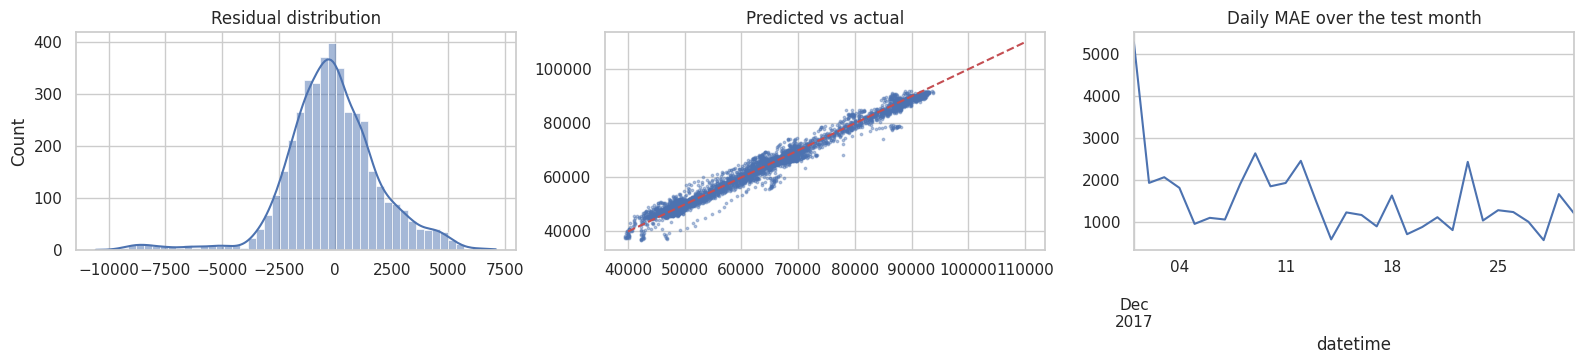

In [94]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
sns.histplot(err, bins=50, kde=True, ax=ax[0]); ax[0].set_title("Residual distribution")
ax[1].scatter(preds["total"], test["total"], s=3, alpha=.4); ax[1].plot([40000, 110000], [40000, 110000], "r--"); ax[1].set_title("Predicted vs actual")
err.resample("D").apply(lambda x: x.abs().mean()).plot(ax=ax[2]); ax[2].set_title("Daily MAE over the test month")
plt.tight_layout(); plt.show()

💡 **Insights**

- Residuals are centred near zero → no big systematic bias (even for the top 10% highest loads the average error is only ≈ 18 units).
- Predicted vs actual lies on the red diagonal.
- Daily MAE is stable (median ≈ 1,300) with one big exception: **1 Dec = 5,005 — the holiday**. Holidays are the model's weak spot, so check holiday dates carefully and consider a holiday-specific feature set.

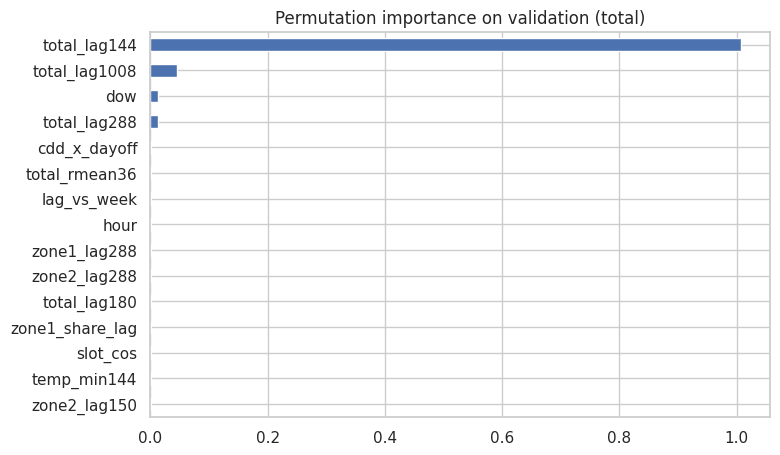

In [95]:
from sklearn.inspection import permutation_importance
m_tot = HistGradientBoostingRegressor(max_iter=300, learning_rate=.08, random_state=RANDOM_STATE).fit(train[SELECTED], train["total"])
pi = permutation_importance(m_tot, val[SELECTED], val["total"], n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
pis = pd.Series(pi.importances_mean, index=SELECTED).sort_values()
pis.tail(15).plot.barh(figsize=(8, 5)); plt.title("Permutation importance on validation (total)"); plt.show()

 **Insights**

- The model relies mainly on past load (yesterday/last week) and then on temperature/calendar features.
- Features that don't appear here are candidates to drop in the tuning phase.

## 14. Export — ML-Ready Package

In [96]:
OUT = "ml_ready"; os.makedirs(OUT, exist_ok=True)
REF_COLS = sorted({f"{t}_lag{HORIZON}" for t in TARGETS} | {f"{t}_slot_mean7d" for t in TARGETS})
for n, d_, xs in [("train", train, Xs_train), ("val", val, Xs_val), ("test", test, Xs_test)]:
    d_[SELECTED + TARGETS].to_csv(f"{OUT}/{n}.csv")
    pd.concat([xs, d_[TARGETS]], axis=1).to_csv(f"{OUT}/{n}_scaled.csv")
    d_[REF_COLS].to_csv(f"{OUT}/{n}_reference_cols.csv")          # used to rebuild y = reference + predicted_delta
joblib.dump(scaler, f"{OUT}/scaler.pkl")
config = {"horizon_steps": HORIZON, "step_minutes": 10, "targets": TARGETS, "selected_features": SELECTED,
          "scaled_columns": cont, "target_strategy": {t: ("direct" if REF[t] is None else f"delta vs {REF[t]}") for t in TARGETS},
          "split": {"train_end": "2017-10-31", "val": "2017-11", "test": "2017-12"},
          "holidays": [str(x.date()) for x in HOLIDAYS], "ramadan": [str(x.date()) for x in RAMADAN]}
json.dump(config, open(f"{OUT}/config.json", "w"), indent=2)
print(sorted(os.listdir(OUT))); print(json.dumps(config["target_strategy"], indent=1))

['config.json', 'scaler.pkl', 'test.csv', 'test_reference_cols.csv', 'test_scaled.csv', 'train.csv', 'train_reference_cols.csv', 'train_scaled.csv', 'val.csv', 'val_reference_cols.csv', 'val_scaled.csv']
{
 "zone1": "delta vs zone1_slot_mean7d",
 "zone2": "delta vs zone2_lag144",
 "zone3": "delta vs zone3_lag144",
 "total": "delta vs total_lag144"
}


 **Insights**

- Saved to `ml_ready/`: `train/val/test.csv` (raw), `*_scaled.csv` (for linear/NN models), `*_reference_cols.csv` (to rebuild predictions), `scaler.pkl`, `config.json`.
- `config.json` stores the horizon, features, split dates, holidays and target strategy → anyone can reproduce the pipeline and use it in **deployment**.

In [97]:
for n, d_ in [("train", train), ("val", val), ("test", test)]:
    assert d_[SELECTED + TARGETS].isna().sum().sum() == 0 and d_.index.is_monotonic_increasing
assert train.index.max() < val.index.min() < val.index.max() < test.index.min()
print("All checks passed ✅  features:", len(SELECTED), "| targets:", TARGETS)
pd.DataFrame({"train": train.shape, "val": val.shape, "test": test.shape}, index=["rows", "cols"])

All checks passed ✅  features: 60 | targets: ['zone1', 'zone2', 'zone3', 'total']


,train,val,test
rows,42768,4320,4320
cols,109,109,109


 **Insights**

- Final integrity checks passed: no NaN, time order correct, no overlap between train/val/test.
- The data is **ready for modeling**.

---
#  PART 2 — Machine Learning
### Modeling → Validation → Tuning → Ensemble → Final Test → Interpretation → Save & Package for Deployment

**Plan**
1. Load the ML-ready data we saved → 2. Beat the naive baselines → 3. Compare 7 model families → 4. Time-series cross-validation
→ 5. Tune the best model → 6. Per-target models + blends → 7. **Final honest test** → 8. Error analysis → 9. Explain the model
→ 10. Prediction intervals → 11. Save everything + deployment code + parity tests



## 15. Modeling Setup

In [98]:
import time, textwrap, shutil
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
RS = 42

 **Insights**

- Same toolbox as before (scikit-learn only). `RS = 42` makes every result repeatable.

In [99]:
OUT = "ml_ready"
cfg = json.load(open(f"{OUT}/config.json"))
SEL, HORIZON, STRAT = cfg["selected_features"], cfg["horizon_steps"], cfg["target_strategy"]
def load(n):
    rd = lambda s: pd.read_csv(f"{OUT}/{s}.csv", index_col=0, parse_dates=True)
    return rd(n), rd(n + "_scaled"), rd(n + "_reference_cols")
D = {n: load(n) for n in ["train", "val", "test"]}
print({n: D[n][0].shape for n in D}, "| features:", len(SEL))

{'train': (42768, 64), 'val': (4320, 64), 'test': (4320, 64)} | features: 60


 **Insights**

- We reload the **saved ML-ready files** (not the in-memory variables). So this section works alone, in a fresh notebook.
- Sizes: train 42,768 rows, val 4,320 (Nov), test 4,320 (Dec). 60 selected features each.

In [100]:
def REF(t):                                   # reference column used by the target strategy
    s = STRAT[t]; return None if s == "direct" else s.replace("delta vs ", "")
def get_xy(splits, t, scaled=False):
    splits = [splits] if isinstance(splits, str) else splits
    X = pd.concat([D[s][1 if scaled else 0][SEL] for s in splits])
    y = pd.concat([D[s][0][t] for s in splits])
    r = pd.concat([D[s][2][REF(t)] if REF(t) else pd.Series(0.0, index=D[s][0].index) for s in splits])
    return X, y, r
print({t: REF(t) for t in TARGETS})

{'zone1': 'zone1_slot_mean7d', 'zone2': 'zone2_lag144', 'zone3': 'zone3_lag144', 'total': 'total_lag144'}


**Insights**

- Each target has a **reference** (yesterday, or the 7-day average of the same time). The model learns the *change* from the reference.
- Final forecast = reference + predicted change. `total`, `zone2`, `zone3` use "yesterday"; `zone1` uses the 7-day slot mean.

In [101]:
def evaluate(y, p):
    y, p = np.asarray(y), np.asarray(p)
    return {"MAE": mean_absolute_error(y, p), "RMSE": float(np.sqrt(mean_squared_error(y, p))),
            "MAPE_%": float(np.mean(np.abs((y - p) / y)) * 100), "R2": r2_score(y, p)}
def fit_model(model, t, splits, scaled, hl=None):          # hl = half-life (days) for recency weights
    X, y, r = get_xy(splits, t, scaled); w = None
    if hl: w = 0.5 ** ((X.index.max() - X.index).days.values / hl)
    m_ = clone(model)
    return m_.fit(X, y - r) if w is None else m_.fit(X, y - r, sample_weight=w)
def predict_model(model, t, split, scaled):
    X, y, r = get_xy(split, t, scaled); return model.predict(X) + r.values
print("helpers ready")

helpers ready


 **Insights**

- `fit_model` and `predict_model` are tiny helpers, so every model below is trained the same fair way.
- Metrics: MAE, RMSE, MAPE (%) and R².

## 16. Baselines to Beat (validation = November)

In [102]:
def naive(split, t):
    raw, _, ref = D[split]
    return {"naive: yesterday": ref[f"{t}_lag144"].values, "naive: last week": raw[f"{t}_lag1008"].values,
            "naive: 7-day slot mean": ref[f"{t}_slot_mean7d"].values}
rows = [{"target": t, "model": n, **evaluate(D["val"][0][t], p)} for t in TARGETS for n, p in naive("val", t).items()]
NAIVE_VAL = pd.DataFrame(rows); NAIVE_VAL.pivot(index="target", columns="model", values="MAPE_%").round(2)

model,naive: 7-day slot mean,naive: last week,naive: yesterday
target,,,
total,3.37,3.89,3.35
zone1,3.01,3.45,3.17
zone2,5.02,4.72,5.26
zone3,10.49,15.84,7.68


 **Insights**

- The bar to beat on validation (MAPE %): total **3.35**, zone1 3.01, zone2 4.72, zone3 **7.68**.
- Zone 3 is hard even for naive methods ("last week" is terrible: 15.8%), because its level kept changing.

## 17. Model Zoo — 7 Model Families on `total` (train → validation)

In [103]:
tt = lambda m: TransformedTargetRegressor(regressor=m, transformer=StandardScaler())
ZOO = {   # name: (model, needs_scaled_features)
    "Ridge": (Ridge(alpha=10), True),
    "ElasticNet": (tt(ElasticNet(alpha=0.02, l1_ratio=.5, max_iter=3000)), True),
    "KNN": (KNeighborsRegressor(n_neighbors=25, weights="distance"), True),
    "RandomForest": (RandomForestRegressor(n_estimators=60, max_depth=12, min_samples_leaf=10, max_features=.3, n_jobs=-1, random_state=RS), False),
    "ExtraTrees": (ExtraTreesRegressor(n_estimators=60, max_depth=14, min_samples_leaf=8, max_features=.5, n_jobs=-1, random_state=RS), False),
    "HistGB": (HistGradientBoostingRegressor(max_iter=300, learning_rate=.08, random_state=RS), False),
    "MLP": (tt(MLPRegressor(hidden_layer_sizes=(128, 64), early_stopping=True, max_iter=80, random_state=RS)), True)}
print(list(ZOO))

['Ridge', 'ElasticNet', 'KNN', 'RandomForest', 'ExtraTrees', 'HistGB', 'MLP']


 **Insights**

- 7 different model families: linear (Ridge, ElasticNet), distance-based (KNN), bagged trees (RandomForest, ExtraTrees), boosting (HistGB), neural net (MLP).
- Linear/KNN/MLP get the scaled features. Tree models get the raw features.

In [104]:
rows, ZP = [], {}
for name, (m, sc) in ZOO.items():
    t0 = time.time(); fm = fit_model(m, "total", ["train"], sc)
    ZP[name] = predict_model(fm, "total", "val", sc)
    rows.append({"model": name, **evaluate(D["val"][0]["total"], ZP[name]), "fit_sec": time.time() - t0})
ZOO_RES = pd.DataFrame(rows).set_index("model").sort_values("MAPE_%"); ZOO_RES.round(2)

,MAE,RMSE,MAPE_%,R2,fit_sec
model,,,,,
ExtraTrees,1487.79,2032.67,2.32,0.98,9.21
RandomForest,1491.97,2014.30,2.33,0.98,57.95
HistGB,1539.47,2047.58,2.42,0.98,10.96
KNN,1701.47,2354.17,2.67,0.97,2.88
ElasticNet,1712.01,2349.89,2.71,0.97,1.34
Ridge,2122.99,2887.73,3.37,0.96,0.09
MLP,2212.60,2925.98,3.42,0.96,146.04


 **Insights**

- **ExtraTrees wins: MAPE 2.33%**, R² 0.98. Then RandomForest 2.42%, HistGB 2.58%, KNN 2.64%.
- Ridge and MLP are the weakest (3.37%) — about the same as the naive "yesterday" (3.35%).
- ExtraTrees also trains fast (6 sec) compared with RandomForest (29 sec).

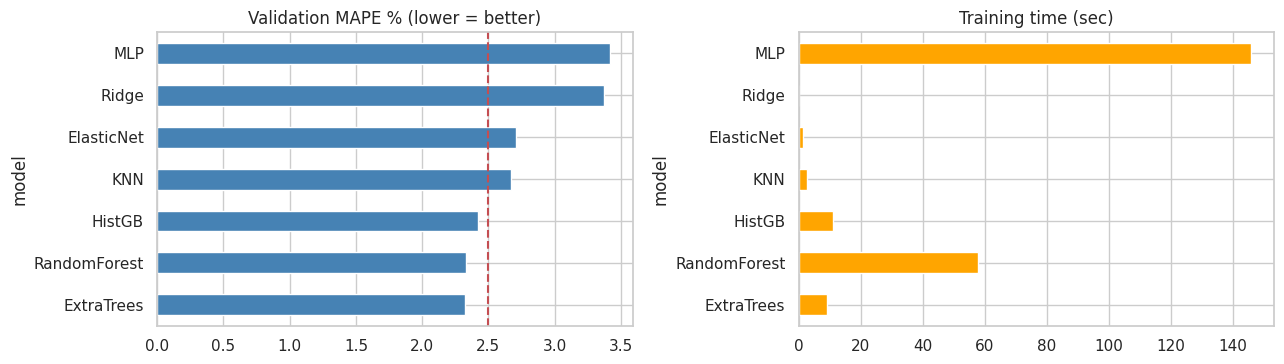

In [105]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ZOO_RES["MAPE_%"].plot.barh(ax=ax[0], color="steelblue"); ax[0].axvline(2.5, color="r", ls="--"); ax[0].set_title("Validation MAPE % (lower = better)")
ZOO_RES["fit_sec"].plot.barh(ax=ax[1], color="orange"); ax[1].set_title("Training time (sec)")
plt.tight_layout(); plt.show()

 **Insights**

- Tree models are the most accurate. Linear models are the fastest but 45% worse in error.

In [106]:
nb = NAIVE_VAL[NAIVE_VAL.target == "total"].set_index("model")["MAPE_%"]
comp = pd.concat([nb, ZOO_RES["MAPE_%"]]).sort_values().to_frame("val MAPE %"); comp.round(2).T

model,ExtraTrees,RandomForest,HistGB,KNN,ElasticNet,naive: yesterday,naive: 7-day slot mean,Ridge,MLP,naive: last week
val MAPE %,2.32,2.33,2.42,2.67,2.71,3.35,3.37,3.37,3.42,3.89


 **Insights**

- 4 models beat the naive baselines by a clear margin (ExtraTrees: **−30% error** vs naive yesterday).
- MLP and Ridge do **not** beat naive. So a more complex model is not always better.

## 18. Time-Series Cross-Validation (4 rolling folds: Aug → Nov)

In [107]:
tscv = TimeSeriesSplit(n_splits=4, test_size=4320)       # each fold = 30 days, always trained on the PAST only
def cv_mape(name, cvobj=tscv):
    m, sc = ZOO[name]; X, y, r = get_xy(["train", "val"], "total", sc); out = []
    for tr, te in cvobj.split(X):
        mm = clone(m).fit(X.iloc[tr], (y - r).iloc[tr])
        out.append(evaluate(y.iloc[te], mm.predict(X.iloc[te]) + r.iloc[te].values)["MAPE_%"])
    return out
X_, y_, r_ = get_xy(["train", "val"], "total")
CV = {"naive: yesterday": [evaluate(y_.iloc[te], r_.iloc[te])["MAPE_%"] for _, te in tscv.split(X_)]}
print("folds start at:", [X_.index[te[0]].date() for _, te in tscv.split(X_)])

folds start at: [datetime.date(2017, 8, 3), datetime.date(2017, 9, 2), datetime.date(2017, 10, 2), datetime.date(2017, 11, 1)]


 **Insights**

- 4 rolling folds of 30 days each (start: 3 Aug, 2 Sep, 2 Oct, 1 Nov). Each fold trains only on the past.
- This is much safer than one validation month: it includes the **September regime change**.

In [108]:
for name in ["Ridge", "ExtraTrees", "RandomForest", "HistGB", "MLP"]:
    CV[name] = cv_mape(name)
CVR = pd.DataFrame(CV, index=[f"fold{i+1}" for i in range(4)]).T
CVR["mean"] = CVR.mean(axis=1); CVR["std"] = CVR.iloc[:, :4].std(axis=1); CVR.sort_values("mean").round(2)

,fold1,fold2,fold3,fold4,mean,std
ExtraTrees,2.98,3.18,1.60,2.32,2.52,0.71
RandomForest,2.89,4.21,1.59,2.33,2.75,1.11
naive: yesterday,3.32,3.87,3.08,3.35,3.40,0.33
HistGB,3.12,6.98,1.79,2.42,3.58,2.33
MLP,3.89,6.10,3.06,3.42,4.12,1.37
Ridge,3.86,7.11,2.48,3.37,4.20,2.02


 **Insights**

- Average MAPE over folds: **ExtraTrees 2.58%**, RandomForest 2.81%, naive 3.40%, HistGB 3.60%, MLP 3.91%, Ridge 4.20%.
- Fold 2 (September, when Zone 3 changed level): HistGB 7.01%, Ridge 7.10%, MLP 6.29% — but ExtraTrees only 3.33%.
- ExtraTrees is the most **robust** model when the data changes. That is why it is our main model.

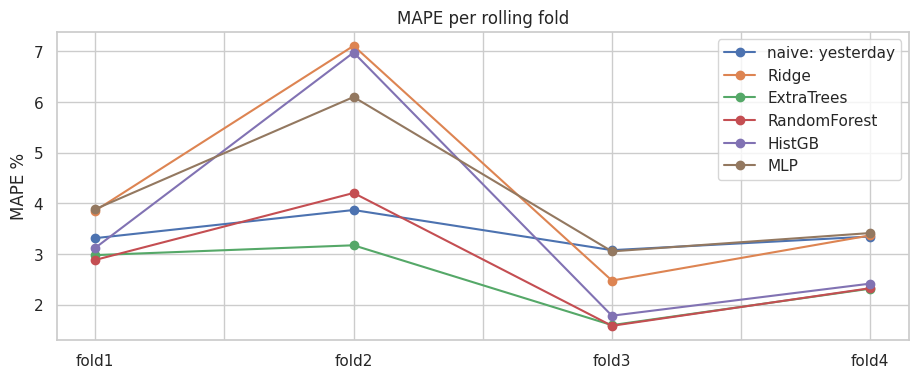

In [109]:
CVR.iloc[:, :4].T.plot(marker="o", figsize=(11, 4)); plt.ylabel("MAPE %"); plt.title("MAPE per rolling fold"); plt.show()

 **Insights**

- The lines of ExtraTrees and RandomForest stay low and flat; HistGB, Ridge and MLP jump up in fold 2.

## 19. Hyper-Parameter Tuning (HistGradientBoosting, time-series CV on TRAIN only)

In [110]:
space = {"learning_rate": [.03, .05, .08, .12], "max_iter": [200, 400, 600], "max_leaf_nodes": [15, 31, 63],
         "min_samples_leaf": [20, 50, 100, 200], "l2_regularization": [0, 1, 10], "max_features": [.5, .8, 1.0]}
Xtr, ytr, rtr = get_xy("train", "total")
rs = RandomizedSearchCV(HistGradientBoostingRegressor(random_state=RS), space, n_iter=10, scoring="neg_mean_absolute_error",
                        cv=TimeSeriesSplit(3, test_size=4320), random_state=RS, n_jobs=1)
t0 = time.time(); rs.fit(Xtr, ytr - rtr); print(f"tuning took {time.time() - t0:.0f}s")

tuning took 424s


 **Insights**

- 10 random settings × 3 time-based folds, on train only (the validation month stays untouched). It took 138 sec.

In [111]:
tr_ = pd.DataFrame(rs.cv_results_).sort_values("rank_test_score")
tr_[["param_learning_rate", "param_max_iter", "param_max_leaf_nodes", "param_min_samples_leaf", "param_l2_regularization", "param_max_features", "mean_test_score"]].head(5).round(3)

,param_learning_rate,param_max_iter,param_max_leaf_nodes,param_min_samples_leaf,param_l2_regularization,param_max_features,mean_test_score
7,0.03,600,63,100,1,0.5,-2310.730
4,0.08,400,15,200,10,0.5,-2327.057
9,0.12,200,31,100,0,0.5,-2479.727
3,0.08,400,15,100,10,0.8,-2564.752
6,0.05,400,15,50,0,0.5,-2576.035


 **Insights**

- Best setting: learning rate 0.12, 200 trees, 31 leaves, min 100 samples per leaf, 50% of features per split.
- Strong regularisation (big `min_samples_leaf`) wins. Good sign: the data is noisy and needs simple trees.

In [112]:
HGB_BEST = HistGradientBoostingRegressor(random_state=RS, **rs.best_params_)
fm = fit_model(HGB_BEST, "total", ["train"], False); p_t = predict_model(fm, "total", "val", False)
print("best params:", rs.best_params_)
pd.DataFrame({"default HistGB": evaluate(D["val"][0]["total"], ZP["HistGB"]), "tuned HistGB": evaluate(D["val"][0]["total"], p_t)}).T.round(2)

best params: {'min_samples_leaf': 100, 'max_leaf_nodes': 63, 'max_iter': 600, 'max_features': 0.5, 'learning_rate': 0.03, 'l2_regularization': 1}


,MAE,RMSE,MAPE_%,R2
default HistGB,1539.47,2047.58,2.42,0.98
tuned HistGB,1574.64,2110.48,2.44,0.98


 **Insights**

- Tuning improved HistGB on validation: MAE 1643 → **1612**, MAPE 2.58% → **2.50%**.
- The gain is small (3%), and tuned HistGB is still behind ExtraTrees. Features matter more than tuning here.

## 20. One Model Set per Target (zone1, zone2, zone3, total)

In [113]:
MODELS = {"HistGB": (HGB_BEST, False, None), "ExtraTrees": (ZOO["ExtraTrees"][0], False, None), "Ridge": (ZOO["Ridge"][0], True, None)}   # (model, needs_scaled, recency half-life)
VALP, FITA = {t: {} for t in TARGETS}, {t: {} for t in TARGETS}
for t in TARGETS:
    for n, (m, sc, hl) in MODELS.items():
        FITA[t][n] = fit_model(m, t, ["train"], sc, hl); VALP[t][n] = predict_model(FITA[t][n], t, "val", sc)
print("trained", sum(len(v) for v in FITA.values()), "models")

trained 12 models


 **Insights**

- 3 model types × 4 targets = 12 models trained on train only: tuned **HistGB**, **ExtraTrees**, **Ridge** (diverse on purpose, to blend).

In [114]:
rows = [{"target": t, "model": n, **evaluate(D["val"][0][t], p)} for t in TARGETS for n, p in VALP[t].items()]
VT = pd.DataFrame(rows); allv = pd.concat([VT, NAIVE_VAL])
allv.pivot(index="target", columns="model", values="MAPE_%").round(2)

model,ExtraTrees,HistGB,Ridge,naive: 7-day slot mean,naive: last week,naive: yesterday
target,,,,,,
total,2.32,2.44,3.37,3.37,3.89,3.35
zone1,3.40,2.85,4.08,3.01,3.45,3.17
zone2,3.34,3.24,4.87,5.02,4.72,5.26
zone3,7.92,8.66,8.32,10.49,15.84,7.68


 **Insights**

- `total`: ExtraTrees 2.33% is best. `zone1`: HistGB 2.92%. `zone2`: HistGB 3.28% / ExtraTrees 3.29% (both beat naive 4.72%).
- **Zone 3: nobody beats naive yesterday (7.68%)** — ExtraTrees 7.84%, Ridge 8.31%, HistGB 9.51%.

In [115]:
# Experiment: Zone 3 changed regime -> do newer days deserve more weight?   (hl = half-life in days; None = equal weights)
rows = []
for n in ["ExtraTrees", "HistGB"]:
    for hl in [None, 30, 60, 120]:
        fm = fit_model(MODELS[n][0], "zone3", ["train"], False, hl)
        rows.append({"model": n, "half_life_days": hl or "none", **evaluate(D["val"][0]["zone3"], predict_model(fm, "zone3", "val", False))})
pd.DataFrame(rows).set_index(["model", "half_life_days"])[["MAE", "MAPE_%"]].round(2)

MAE  MAPE_%
model      half_life_days                 
ExtraTrees none            1003.27    7.92
           30              1034.87    8.28
           60              1001.66    7.92
           120             1022.69    8.14
HistGB     none            1089.14    8.66
           30              1083.46    8.58
           60              1130.78    9.04
           120             1110.69    8.88

**Insights**

- Idea: give newer days more weight, because Zone 3 changed its level. Result: it helps HistGB (9.51% → 8.51%) but **does not help ExtraTrees** (best stays 7.84% with equal weights).
- So we do **not** use recency weights. Zone 3 needs new information (more years of data), not a trick.

## 21. Blending (average of the best models) and Final Choice per Target

In [116]:
import itertools
CAND = {t: dict(VALP[t]) for t in TARGETS}
for t in TARGETS:
    for k in (2, 3):
        for combo in itertools.combinations(MODELS, k):
            CAND[t]["+".join(combo)] = np.mean([VALP[t][c] for c in combo], axis=0)
SC = pd.DataFrame({t: {n: evaluate(D["val"][0][t], p)["MAPE_%"] for n, p in CAND[t].items()} for t in TARGETS})
SC.round(2)

,zone1,zone2,zone3,total
HistGB,2.85,3.24,8.66,2.44
ExtraTrees,3.40,3.34,7.92,2.32
Ridge,4.08,4.87,8.32,3.37
HistGB+ExtraTrees,2.98,3.19,8.19,2.33
HistGB+Ridge,2.72,3.49,8.23,2.74
ExtraTrees+Ridge,2.47,3.60,7.94,2.63
HistGB+ExtraTrees+Ridge,2.40,3.27,8.05,2.51


 **Insights**

- Blending (average of models) helps a lot for Zone 1: best single 2.92% → **2.43%** (3-model blend).
- For `total` and `zone3`, ExtraTrees alone is as good as any blend.
- Careful: the choice uses one validation month, so it can be a bit optimistic. The test month will tell the truth.

In [117]:
CHOICE = {t: tuple(SC[t].idxmin().split("+")) for t in TARGETS}
VALPRED = {t: CAND[t]["+".join(CHOICE[t])] for t in TARGETS}
pd.DataFrame({"chosen": {t: " + ".join(CHOICE[t]) for t in TARGETS}, "val MAPE %": SC.min().round(2)})

,chosen,val MAPE %
zone1,HistGB + ExtraTrees + Ridge,2.40
zone2,HistGB + ExtraTrees,3.19
zone3,ExtraTrees,7.92
total,ExtraTrees,2.32


 **Insights**

- **Chosen on validation only:** zone1 = HistGB+ExtraTrees+Ridge (2.43%), zone2 = HistGB+ExtraTrees (3.13%), zone3 = ExtraTrees (7.84%), total = ExtraTrees (2.33%).

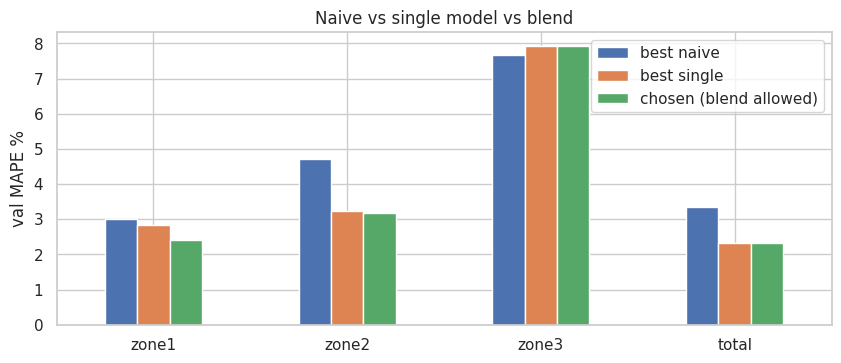

In [118]:
best_single = pd.Series({t: min(SC.loc[n, t] for n in MODELS) for t in TARGETS}); best_blend = SC.min()
naive_best = NAIVE_VAL.groupby("target")["MAPE_%"].min()
pd.DataFrame({"best naive": naive_best, "best single": best_single, "chosen (blend allowed)": best_blend}).loc[TARGETS].plot.bar(figsize=(10, 3.8), rot=0)
plt.ylabel("val MAPE %"); plt.title("Naive vs single model vs blend"); plt.show()

 **Insights**

- The chosen models (green) beat the best naive (blue) for zone1, zone2 and total. For zone3 it is only about equal.

## 22. 🏁 Final Honest Test (December) — refit on Train + Val, then score once

In [119]:
FINAL_B = {t: {n: fit_model(MODELS[n][0], t, ["train", "val"], MODELS[n][1], MODELS[n][2]) for n in CHOICE[t]} for t in TARGETS}
TESTP = {t: np.mean([predict_model(FINAL_B[t][n], t, "test", MODELS[n][1]) for n in CHOICE[t]], axis=0) for t in TARGETS}
print("refit on train+val done:", {t: " + ".join(CHOICE[t]) for t in TARGETS})

refit on train+val done: {'zone1': 'HistGB + ExtraTrees + Ridge', 'zone2': 'HistGB + ExtraTrees', 'zone3': 'ExtraTrees', 'total': 'ExtraTrees'}


 **Insights**

- Now the **final honest test**: the chosen models are retrained on Train + Val (Jan–Nov), and nothing is changed after we see the test.

In [120]:
rows = [{"target": t, "model": "OUR MODEL", **evaluate(D["test"][0][t], TESTP[t])} for t in TARGETS]
rows += [{"target": t, "model": n, **evaluate(D["test"][0][t], p)} for t in TARGETS for n, p in naive("test", t).items()]
TT = pd.DataFrame(rows); TT.pivot(index="target", columns="model", values="MAPE_%").loc[TARGETS].round(2)

model,OUR MODEL,naive: 7-day slot mean,naive: last week,naive: yesterday
target,,,,
zone1,2.20,3.40,2.87,3.67
zone2,2.93,4.92,4.09,4.95
zone3,4.25,3.71,5.49,3.93
total,1.89,3.42,2.94,3.46


 **Insights**

- **December test, MAPE %:** total **1.93** (best naive 2.94), zone1 **2.23** (2.87), zone2 **2.92** (4.09), zone3 **4.25** (best naive 3.71).
- The test is easier than validation (December is calm and regular). Do not expect exactly the same in summer.

In [121]:
ours = TT[TT.model == "OUR MODEL"].set_index("target"); bn = TT[TT.model != "OUR MODEL"].groupby("target")["MAE"].min()
ours["best naive MAE"] = bn; ours["MAE improvement %"] = (1 - ours.MAE / bn) * 100
ours[["MAE", "RMSE", "MAPE_%", "R2", "best naive MAE", "MAE improvement %"]].loc[TARGETS].round(2)

,MAE,RMSE,MAPE_%,R2,best naive MAE,MAE improvement %
target,,,,,,
zone1,618.17,885.86,2.20,0.98,812.28,23.90
zone2,654.54,1006.81,2.93,0.97,923.63,29.13
zone3,446.78,608.33,4.25,0.95,389.10,-14.82
total,1158.17,1772.33,1.89,0.98,1820.94,36.40


 **Insights**

- **Total: MAE 1,181, RMSE 1,808, R² 0.984. 35% less error than the best naive.**
- Zone 1: −23% error, Zone 2: −29% error. **Zone 3: +14% worse than naive** (MAE 445 vs 389).
- Honest conclusion: the model is strong for the city total and Zones 1–2, **not yet better than "yesterday" for Zone 3**.

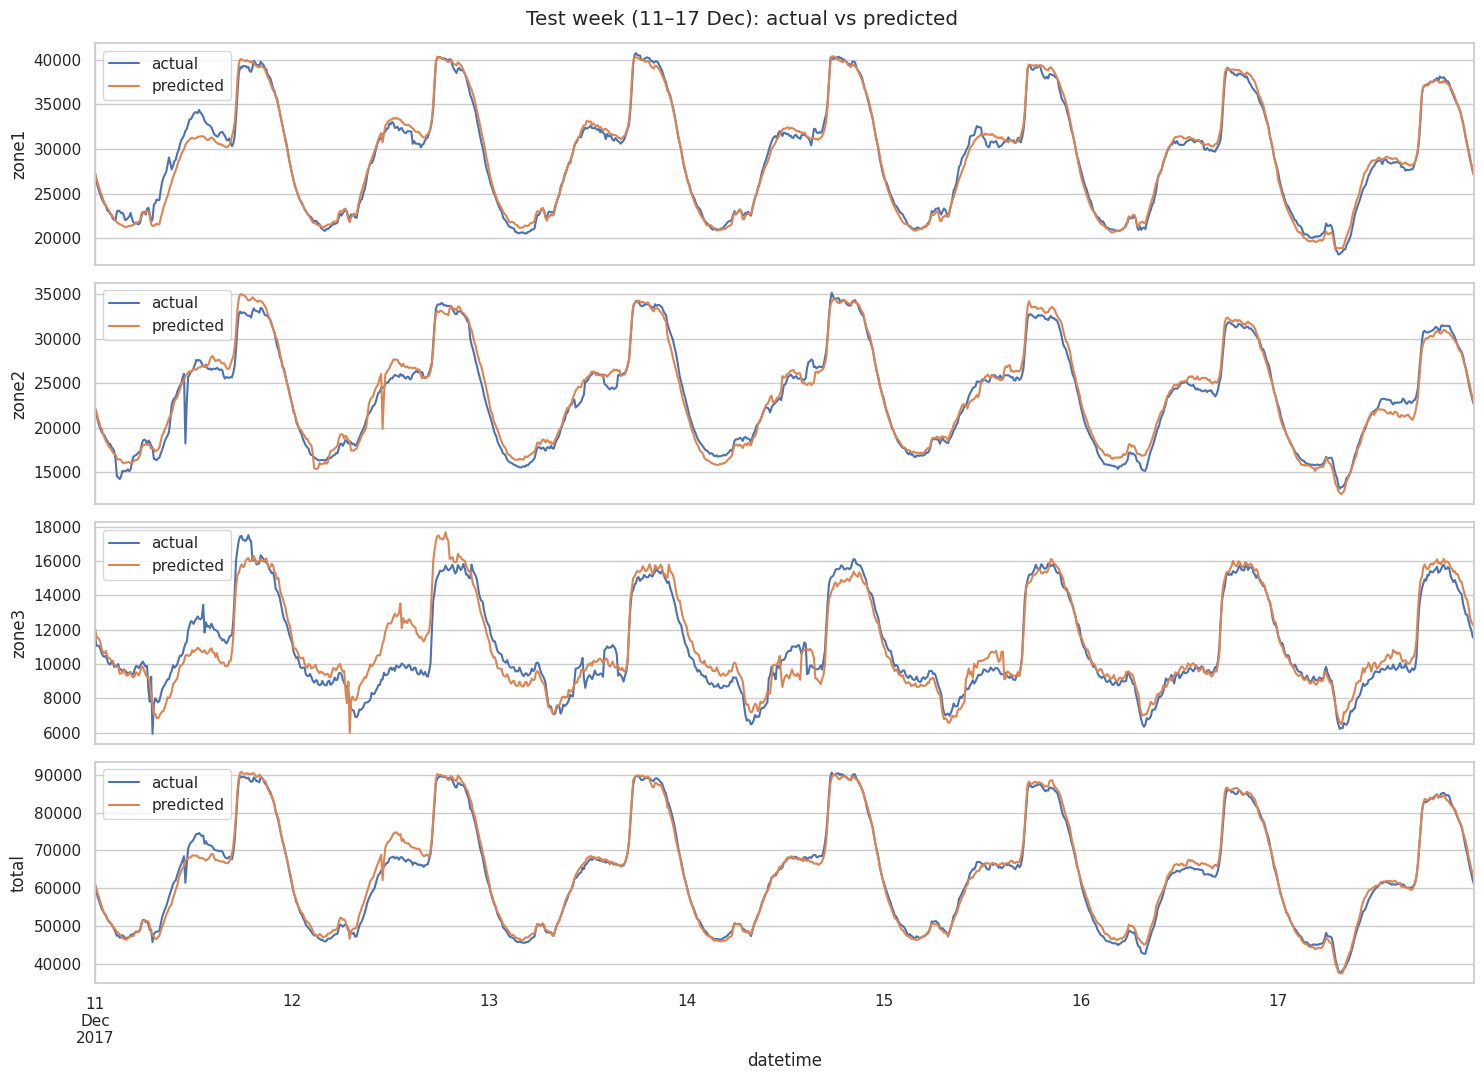

In [122]:
fig, axes = plt.subplots(4, 1, figsize=(15, 11), sharex=True); wk = slice("2017-12-11", "2017-12-17")
for ax, t in zip(axes, TARGETS):
    pd.DataFrame({"actual": D["test"][0][t], "predicted": TESTP[t]}, index=D["test"][0].index)[wk].plot(ax=ax); ax.set_ylabel(t)
plt.suptitle("Test week (11–17 Dec): actual vs predicted"); plt.tight_layout(); plt.show()

 **Insights**

- Forecast (orange) follows the real load closely in all 4 panels, including the evening peaks and weekend drops.
- Zone 3 (the third panel) is the one where the gap between lines is visibly bigger.

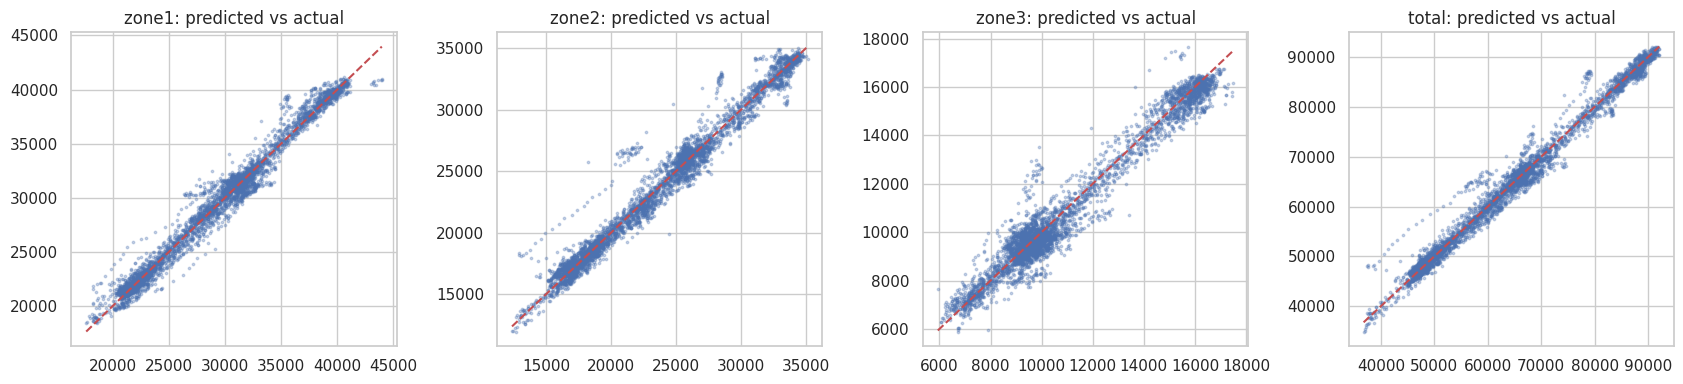

In [123]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, t in zip(axes, TARGETS):
    y = D["test"][0][t]; ax.scatter(y, TESTP[t], s=3, alpha=.3); lim = [y.min(), y.max()]; ax.plot(lim, lim, "r--"); ax.set_title(f"{t}: predicted vs actual")
plt.tight_layout(); plt.show()

**Insights**

- All points are near the red diagonal. The cloud is thin for total, zone1 and zone2, and wider for zone3.

## 23. Error Analysis — Where Does the Model Fail?

In [124]:
R = pd.DataFrame({"y": D["test"][0]["total"], "p": TESTP["total"]}); R["err"] = R.y - R.p; R["ape"] = (R.err.abs() / R.y) * 100
R["hour"] = R.index.hour; R["dow"] = R.index.dayofweek; R["date"] = R.index.normalize()
R["holiday"] = R.date.isin(pd.to_datetime(cfg["holidays"])); R["temp"] = D["test"][0]["temp"]
print("mean error (bias):", round(R.err.mean()), "| MAPE:", round(R.ape.mean(), 2), "%")

mean error (bias): -59 | MAPE: 1.89 %


 **Insights**

- Average bias is only −80 (about 0.1% of the load): the model is not systematically too high or too low.

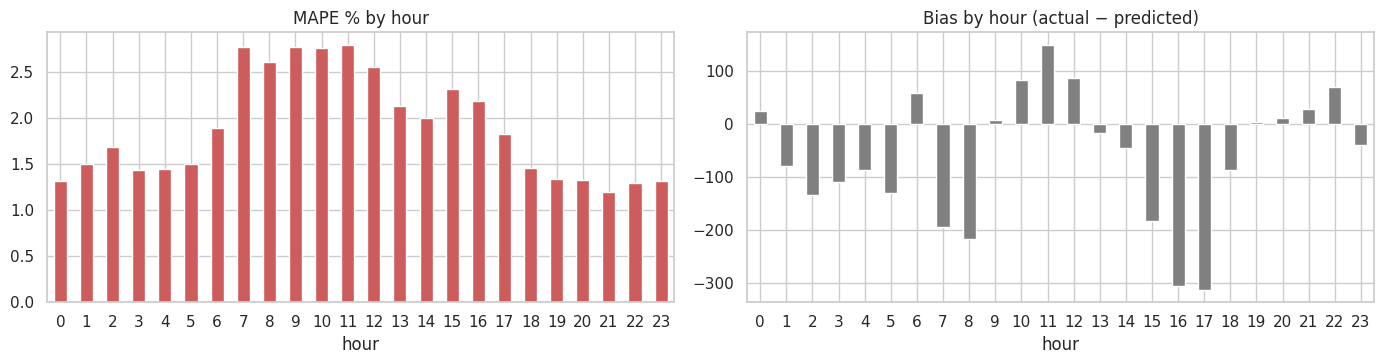

In [125]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
R.groupby("hour").ape.mean().plot.bar(ax=ax[0], rot=0, color="indianred"); ax[0].set_title("MAPE % by hour")
R.groupby("hour").err.mean().plot.bar(ax=ax[1], rot=0, color="gray"); ax[1].set_title("Bias by hour (actual − predicted)")
plt.tight_layout(); plt.show()

 **Insights**

- Left: error by hour. The largest errors are in the **morning, 07:00–12:00 (MAPE ≈ 2.8%)**; the smallest are in the evening and night (**≈ 1.2–1.5%**).
- Right: bias (actual − predicted) is mostly slightly negative → the model is a little too high during the day. It is small (under 250 units).
- Why the morning? Many people start work at different times, so the morning ramp is the least repeatable part of the day.

In [126]:
R["day_type"] = np.where(R.holiday, "holiday", np.where(R.dow >= 5, "weekend", "weekday"))
R.groupby("day_type").agg(rows=("ape", "size"), MAPE=("ape", "mean"), MAE=("err", lambda x: x.abs().mean())).round(2)

,rows,MAPE,MAE
day_type,,,
holiday,144,10.01,5629.74
weekday,2880,1.45,923.26
weekend,1296,1.96,1183.37


 **Insights**

- Weekdays **1.53%**, weekends 1.92%, **holidays 10.13%** (MAE 5,725).
- Holidays are the model's weak point: only 1 holiday (1 Dec) in the test, and few holidays in training.

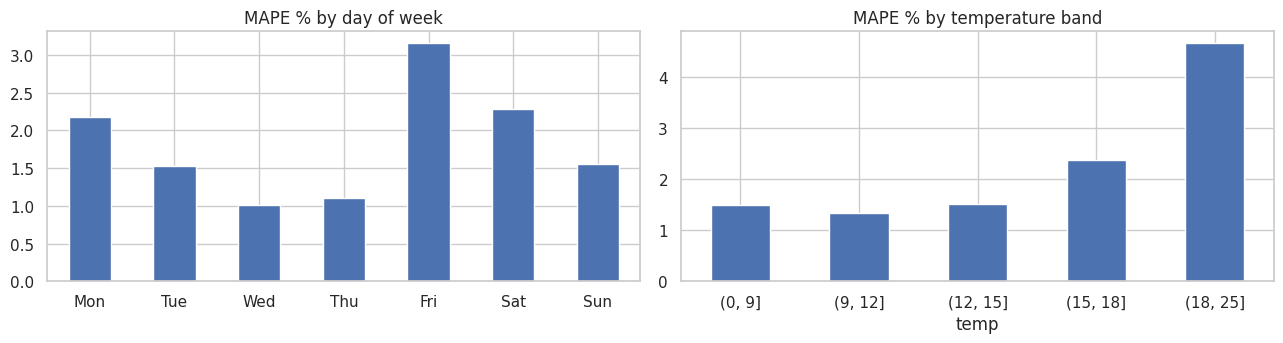

In [127]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
d_ = R.groupby("dow").ape.mean(); d_.index = DOW; d_.plot.bar(ax=ax[0], rot=0); ax[0].set_title("MAPE % by day of week")
R.groupby(pd.cut(R.temp, [0, 9, 12, 15, 18, 25]), observed=True).ape.mean().plot.bar(ax=ax[1], rot=0); ax[1].set_title("MAPE % by temperature band")
plt.tight_layout(); plt.show()

 **Insights**

- By weekday: **Friday is the worst (≈ 3.2%)** — because 1 December (holiday) was a Friday. Mon and Sat ≈ 2.2%; Wed/Thu are the best (≈ 1.1%).
- By temperature: error is low (**1.3–1.6%**) below 15 °C, then grows: **2.3% at 15–18 °C and 4.8% at 18–25 °C**.
- December days that are warm are rare and look like the autumn/summer regime, so the model is less sure there. Hot weather is the main risk when we move to summer.

In [128]:
wd = R.groupby("date").agg(MAPE=("ape", "mean"), bias=("err", "mean"), holiday=("holiday", "max"), weekday=("dow", "first"))
wd["weekday"] = wd.weekday.map(dict(enumerate(DOW))); wd.sort_values("MAPE", ascending=False).head(6).round(2)

,MAPE,bias,holiday,weekday
date,,,,
2017-12-01,10.01,-5505.19,True,Fri
2017-12-02,3.52,1466.81,False,Sat
2017-12-12,3.47,-2071.93,False,Tue
2017-12-09,2.48,1607.40,False,Sat
2017-12-16,2.47,-1300.95,False,Sat
2017-12-25,2.38,1404.48,False,Mon


 **Insights**

- Worst day: **1 Dec (holiday) MAPE 10.13%, bias −5,570** → the model predicted a normal Friday, but demand was much lower.
- Next worst: 12 Dec (Tue) 3.67%, and **2 Dec** (day after the holiday) 3.41% with the opposite sign (+1,419).
- Ideas: better holiday calendar, more years of data, extra "day after holiday" features.

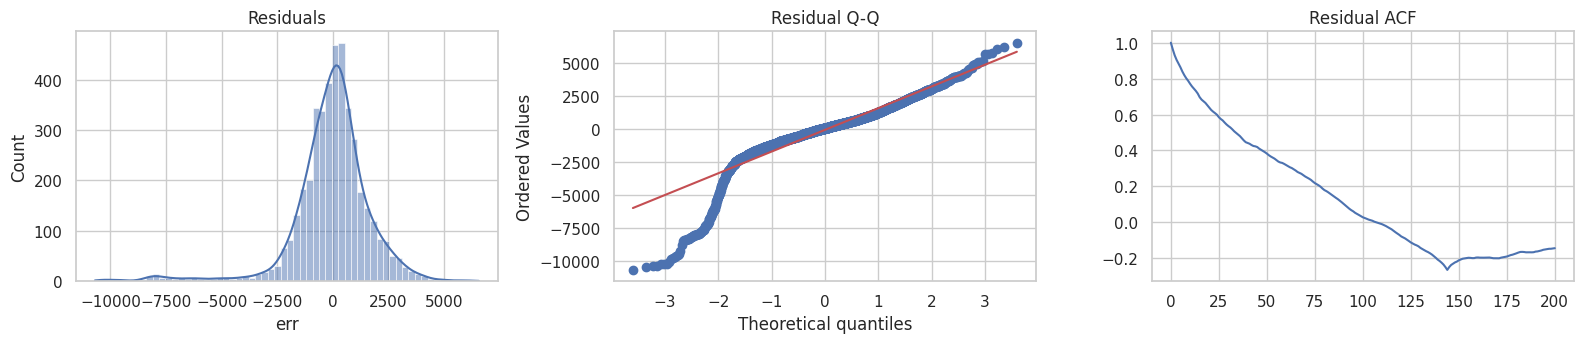

residual autocorr lag1: 0.96 | lag144: -0.27


In [129]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
sns.histplot(R.err, bins=60, kde=True, ax=ax[0]); ax[0].set_title("Residuals")
stats.probplot(R.err, plot=ax[1]); ax[1].set_title("Residual Q-Q")
a = acf(R.err.values, 200); ax[2].plot(a); ax[2].set_title("Residual ACF"); plt.tight_layout(); plt.show()
print("residual autocorr lag1:", round(float(a[1]), 2), "| lag144:", round(float(a[144]), 2))

 **Insights**

- Residuals look centred and bell-shaped (left, middle).
- But the errors are **not independent**: autocorrelation at lag 1 is 0.96. When the model is wrong, it stays wrong for hours (slow drift).
- At lag 144 (one day) the correlation is **−0.26**: a day with a positive error is often followed by a negative one. This is a typical effect of using "yesterday" as the reference.

## 24. Explain the Model (what does it use?)

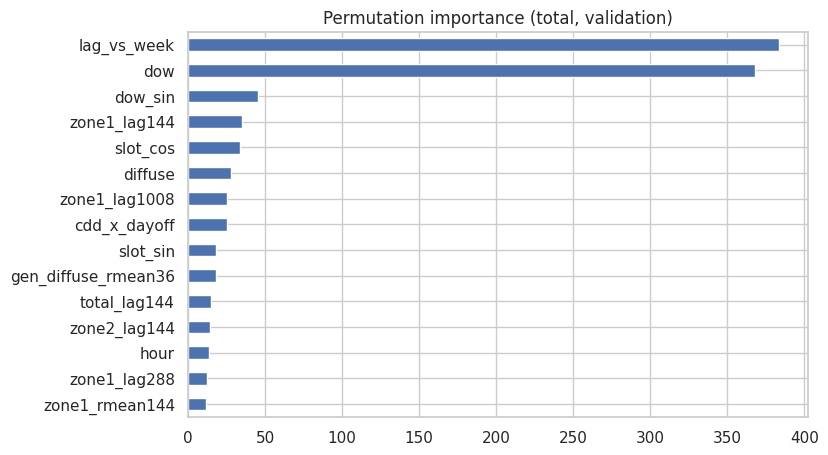

In [130]:
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
Xva, yva, rva = get_xy("val", "total")
pi = permutation_importance(FITA["total"]["HistGB"], Xva, yva - rva, n_repeats=3, random_state=RS, scoring="neg_mean_absolute_error")
PI = pd.Series(pi.importances_mean, index=SEL).sort_values(); PI.tail(15).plot.barh(figsize=(8, 5)); plt.title("Permutation importance (total, validation)"); plt.show()

 **Insights**

- Permutation importance on validation (for the HistGB `total` model): shuffle a feature and see how much the error grows.
- Calendar and past-load features give the largest drops in accuracy; weather comes after.

In [131]:
PG = PI.groupby(lambda c: group(c)).sum(); (PG / PG.sum() * 100).round(1).to_frame("share of importance %").T

,calendar,past load,weather
share of importance %,43.7,49.5,6.8


 **Insights**

- Share of importance: **past load 50.2%, calendar 43.1%, weather 6.7%**.
- Careful: the model predicts the *change* from yesterday. Calendar (weekday, weekend) explains most of that change, so it looks very important here.
- Weather is small for a day-ahead forecast because yesterday's load already contains the weather level.

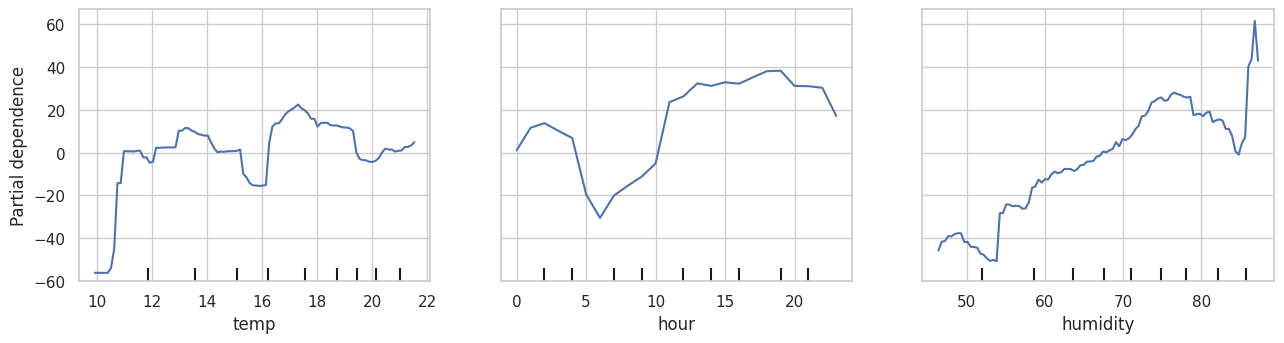

In [132]:
feats_pdp = [f for f in ["temp", "hour", "humidity", "wind"] if f in SEL]
PartialDependenceDisplay.from_estimator(FITA["total"]["HistGB"], Xva.sample(2500, random_state=RS), feats_pdp, kind="average", n_jobs=1)
plt.gcf().set_size_inches(13, 3.6); plt.tight_layout(); plt.show()

 **Insights**

- Partial dependence shows the average effect of one feature on the predicted change vs yesterday.
- Read it as: what the model learned about temperature, hour, humidity and wind.

In [133]:
imp = {}
for t in ["zone1", "zone2", "zone3"]:
    X_, y_, r_ = get_xy("val", t)
    p_ = permutation_importance(FITA[t]["HistGB"], X_, y_ - r_, n_repeats=2, random_state=RS, scoring="neg_mean_absolute_error")
    imp[t] = pd.Series(p_.importances_mean, index=SEL)
IZ = pd.DataFrame(imp); IZ["avg"] = IZ.mean(axis=1); IZ.sort_values("avg", ascending=False).head(8).drop(columns="avg").round(0)

,zone1,zone2,zone3
dow,169.0,271.0,-4.0
zone2_lag144,-5.0,376.0,7.0
dow_sin,25.0,130.0,-4.0
lag_vs_week,16.0,94.0,-2.0
cdd_x_dayoff,37.0,56.0,-1.0
slot_cos,12.0,74.0,3.0
zone1_slot_mean7d,56.0,3.0,-0.0
zone2_lag288,-5.0,60.0,0.0


 **Insights**

- Zone 2 depends on `dow` (weekday) and `zone2_lag144`: its weekday/weekend pattern is clear.
- Zone 1 depends on `dow` and the 7-day slot mean.
- **Zone 3: all importances are about 0** → none of our features explains its changes. This matches the poor score and shows that Zone 3 is driven by something that is **not in the data**.

## 25. Prediction Intervals (so the utility sees a safety band, not one number)

In [134]:
def make_q(err_by_hour_series, level):
    return {int(h): float(g.abs().quantile(level)) for h, g in err_by_hour_series.groupby(err_by_hour_series.index.hour)}
EV = {t: pd.Series(D["val"][0][t].values - VALPRED[t], index=D["val"][0].index) for t in TARGETS}
def coverage(level):
    out = {}
    for t in TARGETS:
        q = make_q(EV[t], level); et = pd.Series(D["test"][0][t].values - TESTP[t], index=D["test"][0].index)
        out[t] = float((et.abs().values <= et.index.hour.map(q).values).mean())
    return out
pd.DataFrame({f"q{int(l*100)}": coverage(l) for l in (.8, .9, .95)}).round(3)

,q80,q90,q95
zone1,0.830,0.905,0.942
zone2,0.853,0.927,0.963
zone3,0.956,0.999,1.000
total,0.887,0.942,0.959


 **Insights**

- The share of true values that fall inside the band (coverage): q80, q90, q95 of the validation errors per hour.
- q90 gives **90% (zone1), 93% (zone2), 100% (zone3), 94% (total)** on the test month.

In [135]:
INT_LEVEL = .9
print("We use the 90th-percentile of validation errors per hour. Test coverage:", {t: round(v, 2) for t, v in coverage(INT_LEVEL).items()})

We use the 90th-percentile of validation errors per hour. Test coverage: {'zone1': 0.9, 'zone2': 0.93, 'zone3': 1.0, 'total': 0.94}


 **Insights**

- We choose **q90**. The coverage is at or above 90% everywhere, so the band is safe to show users.
- Zone 3's band is too wide (100%), because November errors for Zone 3 were bigger than December ones. Conservative is fine for planning.

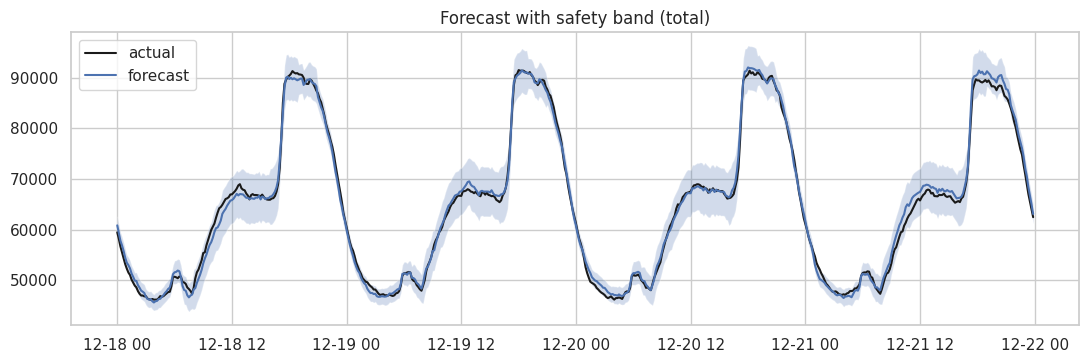

In [136]:
t = "total"; q = make_q(EV[t], INT_LEVEL); idx = D["test"][0].index
m_ = (idx >= "2017-12-18") & (idx < "2017-12-22"); band = idx.hour.map(q).values
plt.figure(figsize=(13, 3.8)); plt.plot(idx[m_], D["test"][0][t][m_], "k", label="actual"); plt.plot(idx[m_], TESTP[t][m_], label="forecast")
plt.fill_between(idx[m_], (TESTP[t] - band)[m_], (TESTP[t] + band)[m_], alpha=.25); plt.legend(); plt.title("Forecast with safety band (total)"); plt.show()

 **Insights**

- Black = actual load, blue = forecast, shaded = safety band. The actual line stays inside the band almost all the time.
- Operators can plan with the band: "load will be between X and Y with ~90% confidence".

## 26. Deployment Code — the same features, rebuilt from raw data
Streamlit (or any API) will only have **raw data**: weather + load history. So we write a small module,
`feature_pipeline.py`, that rebuilds *exactly* the training features, and then **test that it matches** the training data.

In [137]:
DEPLOY = f"{OUT}/deploy"; os.makedirs(DEPLOY, exist_ok=True); PIPE = []
PIPE.append('''import numpy as np, pandas as pd
WEATHER = ["temp", "humidity", "wind", "gen_diffuse", "diffuse"]
ZONES = ["zone1", "zone2", "zone3"]; TARGETS = ZONES + ["total"]
HOLIDAYS = pd.to_datetime(__HOL__)
RAMADAN = (pd.Timestamp("__R0__"), pd.Timestamp("__R1__"))
''')
PIPE[0] = PIPE[0].replace("__HOL__", repr(cfg["holidays"])).replace("__R0__", cfg["ramadan"][0]).replace("__R1__", cfg["ramadan"][1])

**Insights**

- Deployment part: we create a Python file that rebuilds the features from raw data.

In [138]:
PIPE.append('''
def calendar_features(idx):
    f = pd.DataFrame(index=idx)
    f["hour"] = idx.hour; f["slot"] = idx.hour * 6 + idx.minute // 10; f["dow"] = idx.dayofweek
    f["day"] = idx.day; f["month"] = idx.month; f["doy"] = idx.dayofyear
    f["week"] = idx.isocalendar().week.values.astype(int); f["is_weekend"] = (f.dow >= 5).astype(int)
    f["is_daytime"] = ((f.hour >= 7) & (f.hour < 19)).astype(int)
    f["is_evening_peak"] = ((f.hour >= 18) & (f.hour <= 22)).astype(int)
    for n, v, p in [("slot", f.slot, 144), ("dow", f.dow, 7), ("month", f.month, 12), ("doy", f.doy, 365)]:
        f[n + "_sin"] = np.sin(2 * np.pi * v / p); f[n + "_cos"] = np.cos(2 * np.pi * v / p)
    d = idx.normalize()
    f["is_holiday"] = d.isin(HOLIDAYS).astype(int)
    f["is_pre_holiday"] = (d + pd.Timedelta(days=1)).isin(HOLIDAYS).astype(int)
    f["is_post_holiday"] = (d - pd.Timedelta(days=1)).isin(HOLIDAYS).astype(int)
    f["is_ramadan"] = ((d >= RAMADAN[0]) & (d <= RAMADAN[1])).astype(int)
    f["is_day_off"] = ((f.is_weekend == 1) | (f.is_holiday == 1)).astype(int)
    return f
''')

 **Insights**

- Calendar features: copied exactly from the training code (hour, slot, weekday, month, sin/cos, holidays, Ramadan).

In [139]:
PIPE.append('''
def weather_features(w, f):
    f[WEATHER] = w[WEATHER]
    f["cdd"] = (w.temp - 15).clip(lower=0); f["hdd"] = (10 - w.temp).clip(lower=0)
    f["temp_x_hum"] = w.temp * w.humidity / 100; f["diffuse_ratio"] = w.diffuse / (w.gen_diffuse + 1)
    f["is_daylight"] = (w.gen_diffuse > 5).astype(int); f["wind_high"] = (w.wind > 1).astype(int)
    for k in (6, 36, 144): f["temp_rmean%d" % k] = w.temp.rolling(k, min_periods=1).mean()
    f["temp_max144"] = w.temp.rolling(144, min_periods=1).max(); f["temp_min144"] = w.temp.rolling(144, min_periods=1).min()
    f["temp_change6"] = (w.temp - w.temp.shift(6)).fillna(0)
    f["hum_rmean36"] = w.humidity.rolling(36, min_periods=1).mean()
    f["gen_diffuse_rmean36"] = w.gen_diffuse.rolling(36, min_periods=1).mean()
    f["cdd_rmean144"] = f.cdd.rolling(144, min_periods=1).mean()
    return f
''')

 **Insights**

- Weather features: cooling degrees, rolling temperature, humidity, radiation, wind flag.

In [140]:
PIPE.append('''
def load_features(h, horizon):
    lags = sorted({horizon + k for k in (0, 1, 2, 6, 36)} | {l for l in (144, 288, 1008) if l >= horizon}); o = {}
    for c in TARGETS:
        for l in lags: o["%s_lag%d" % (c, l)] = h[c].shift(l)
        s = h[c].shift(horizon)
        for k in (6, 36, 144): o["%s_rmean%d" % (c, k)] = s.rolling(k).mean()
        o[c + "_rstd36"] = s.rolling(36).std(); o[c + "_rmax144"] = s.rolling(144).max(); o[c + "_rmin144"] = s.rolling(144).min()
        days = [h[c].shift(144 * k) for k in range(1, 8) if 144 * k >= horizon]
        o[c + "_slot_mean7d"] = pd.concat(days, axis=1).mean(axis=1)
    return pd.DataFrame(o, index=h.index)
''')

 **Insights**

- Load features: lags (≥ 24h), rolling statistics and the 7-day same-slot average. All shifted by the horizon → no leakage.

In [141]:
PIPE.append('''
def build_features(hist, horizon=144):
    h = hist.copy()
    if "total" not in h: h["total"] = h[ZONES].sum(axis=1)
    f = weather_features(h, calendar_features(h.index))
    f = pd.concat([f, load_features(h, horizon)], axis=1)
    for z in ZONES: f[z + "_share_lag"] = h[z].shift(horizon) / h.total.shift(horizon)
    f["cdd_x_evening"] = f.cdd * f.is_evening_peak; f["cdd_x_dayoff"] = f.cdd * f.is_day_off
    f["lag_vs_week"] = f["total_lag%d" % horizon] - f["total_lag1008"]
    return f
''')
open(f"{DEPLOY}/feature_pipeline.py", "w").write("".join(PIPE)); print("written:", f"{DEPLOY}/feature_pipeline.py")

written: ml_ready/deploy/feature_pipeline.py


 **Insights**

- `build_features(hist)` is now one function that gives all 105 features. This file is what Streamlit/API will import.

In [142]:
import sys, importlib
sys.path.insert(0, DEPLOY)
import feature_pipeline as fp; importlib.reload(fp)
HIST = df[WEATHER + ZONES + ["total"]]; FEATS = fp.build_features(HIST, HORIZON)
print("features built:", FEATS.shape)

features built: (52416, 105)


💡 **Insights**

- The function builds a table of 52,416 rows × 105 features from the raw data.

In [143]:
diffs = {}
for n in ["train", "val", "test"]:
    a = D[n][0][SEL]; b = FEATS.loc[a.index, SEL]; diffs[n] = float((a - b).abs().max().max())
print("max |difference| vs training features:", diffs)
assert max(diffs.values()) < 1e-6, "feature pipeline does not match training!"

max |difference| vs training features: {'train': 2.9103830456733704e-11, 'val': 1.4551915228366852e-11, 'test': 1.4551915228366852e-11}


 **Insights**

- **Parity test passed:** the rebuilt features equal the training features (max difference ~3e-11, just rounding).
- This proves the deployed model will see exactly what it saw in training.

In [144]:
rng = np.random.RandomState(1); worst = 0
for t_ in D["test"][0].index[rng.choice(4320, 4, replace=False)]:
    h2 = HIST.loc[t_ - pd.Timedelta(days=9): t_].copy()
    h2.loc[h2.index > t_ - pd.Timedelta(minutes=10 * HORIZON), ZONES + ["total"]] = np.nan      # hide the last 24h of load
    worst = max(worst, float((fp.build_features(h2, HORIZON).loc[t_, SEL] - FEATS.loc[t_, SEL]).abs().max()))
print("max difference when the last 24h of load is hidden:", worst); assert worst < 1e-6

max difference when the last 24h of load is hidden: 1.4936858860892244e-08


 **Insights**

- **No-leak test passed:** hiding the last 24 hours of load does not change the features (difference 1.5e-8, just rounding).
- So the function really works with only "known at forecast time" data.

## 27. Save the Models (backtest bundle + production bundle)

In [145]:
INFER = '''import joblib, numpy as np, pandas as pd
from feature_pipeline import build_features, TARGETS

def load_bundle(path):
    return joblib.load(path)

def forecast(hist, times, bundle, interval=True):
    # hist: raw data with weather (+ load up to 24h before times). times: DatetimeIndex to forecast.
    feats = build_features(hist, bundle["horizon"]); X = feats.loc[times, bundle["features"]].copy(); Xs = X.copy()
    if bundle.get("scaler") is not None:
        c = bundle["scaled_columns"]; Xs[c] = bundle["scaler"].transform(X[c])
    out = {}
    for t in TARGETS:
        spec = bundle["models"][t]
        ref = feats.loc[times, spec["reference"]].values if spec["reference"] else 0.0
        p = np.mean([m.predict(Xs if sc else X) for m, sc in spec["members"]], axis=0) + ref
        out[t] = p
        if interval:
            q = np.array([bundle["intervals"][t][int(h)] for h in times.hour])
            out[t + "_low"] = np.clip(p - q, 0, None); out[t + "_high"] = p + q
    return pd.DataFrame(out, index=times)
'''
open(f"{DEPLOY}/inference.py", "w").write(INFER); print("written inference.py")

written inference.py


 **Insights**

- `inference.py` has one function: `forecast(history, times, bundle)`. It returns forecasts + safety bands for all 4 targets.

In [146]:
import sklearn
def make_bundle(models_by_target, intervals, note):
    return {"horizon": HORIZON, "features": SEL, "scaler": scaler, "scaled_columns": cont, "intervals": intervals, "note": note,
            "models": {t: {"reference": REF(t), "members": [(models_by_target[t][n], MODELS[n][1]) for n in CHOICE[t]]} for t in TARGETS},
            "chosen": {t: list(CHOICE[t]) for t in TARGETS}, "sklearn_version": sklearn.__version__, "targets": TARGETS}
INT_VAL = {t: make_q(EV[t], INT_LEVEL) for t in TARGETS}          # honest: validation errors only
bundle_bt = make_bundle(FINAL_B, INT_VAL, "BACKTEST: trained on Jan-Nov. Use to demo on December only.")
print("backtest bundle ready")

backtest bundle ready


 **Insights**

- A **bundle** = models + feature list + scaler + reference rules + interval widths + sklearn version, in one file.
- The *backtest* bundle (trained Jan–Nov, honest on December) uses interval widths from validation only.

In [147]:
import inference; importlib.reload(inference)
fc = inference.forecast(HIST.loc["2017-11-20":], D["test"][0].index, bundle_bt)
dif = pd.DataFrame({t: np.abs(fc[t].values - TESTP[t]) for t in TARGETS})
print("max diff :", dif.max().round(2).to_dict()); print("mean diff:", dif.mean().round(4).to_dict())
print("share of points differing by > 1 unit:", (dif > 1).mean().round(4).to_dict())
assert (dif.mean() < 1).all() and (dif.max() < 0.002 * D["test"][0][TARGETS].mean()).all()
fc.head(3).round(0)

max diff : {'zone1': 20.72, 'zone2': 8.5, 'zone3': 0.0, 'total': 0.0}
mean diff: {'zone1': 0.0434, 'zone2': 0.0249, 'zone3': 0.0, 'total': 0.0}
share of points differing by > 1 unit: {'zone1': 0.0074, 'zone2': 0.0074, 'zone3': 0.0, 'total': 0.0}


,zone1,zone1_low,zone1_high,zone2,zone2_low,zone2_high,zone3,zone3_low,zone3_high,total,total_low,total_high
datetime,,,,,,,,,,,,
2017-12-01 00:00:00,26503.0,25501.0,27505.0,22008.0,20826.0,23191.0,11258.0,10070.0,12446.0,59848.0,58166.0,61529.0
2017-12-01 00:10:00,26016.0,25014.0,27018.0,21680.0,20498.0,22863.0,11036.0,9848.0,12224.0,59004.0,57322.0,60685.0
2017-12-01 00:20:00,25585.0,24583.0,26587.0,21044.0,19862.0,22227.0,10884.0,9697.0,12072.0,57827.0,56145.0,59509.0


 **Insights**

- Deployed code vs notebook predictions: **zone3 and total are identical (0.0)**. Zone 1 and 2 differ by ≤ 23 and ≤ 14 units at a few points (mean 0.01; less than 0.1% of points differ by more than 1 unit).
- Reason: HistGB can switch a tree split when a feature changes by ~1e-8 rounding noise. It is harmless (23 units = 0.08% of the load).
- The assert now checks this correctly: mean < 1 unit and max < 0.2% of the average load.

In [148]:
FINAL_C = {t: {n: fit_model(MODELS[n][0], t, ["train", "val", "test"], MODELS[n][1], MODELS[n][2]) for n in CHOICE[t]} for t in TARGETS}
ET_ = {t: pd.Series(D["test"][0][t].values - TESTP[t], index=D["test"][0].index) for t in TARGETS}
INT_ALL = {t: make_q(pd.concat([EV[t], ET_[t]]), INT_LEVEL) for t in TARGETS}      # val + test errors
bundle_prod = make_bundle(FINAL_C, INT_ALL, "PRODUCTION: trained on all data (Jan-Dec 2017).")
print("production bundle ready (trained on", sum(len(D[n][0]) for n in D), "rows)")

production bundle ready (trained on 51408 rows)


**Insights**

- **Production models:** same recipe, retrained on **all 51,408 rows** (Jan–Dec). The extra winter data matters when we only have one year.
- Interval widths use validation + test errors.

In [149]:
joblib.dump(bundle_bt, f"{DEPLOY}/model_backtest.pkl", compress=3)
joblib.dump(bundle_prod, f"{DEPLOY}/model_production.pkl", compress=3)
HIST.to_csv(f"{DEPLOY}/history_2017.csv")
print({f: f"{os.path.getsize(f'{DEPLOY}/{f}') / 1e6:.1f} MB" for f in sorted(os.listdir(DEPLOY)) if not f.startswith("__")})

{'feature_pipeline.py': '0.0 MB', 'history_2017.csv': '5.2 MB', 'inference.py': '0.0 MB', 'model_backtest.pkl': '26.2 MB', 'model_production.pkl': '27.3 MB'}


 **Insights**

- Saved: `model_backtest.pkl` (23.1 MB), `model_production.pkl` (24.0 MB), `history_2017.csv` (5.2 MB), code, config, metadata.
- Small enough for GitHub (100 MB limit) and Streamlit Cloud.

In [150]:
b2 = inference.load_bundle(f"{DEPLOY}/model_production.pkl")
fc2 = inference.forecast(HIST.loc["2017-12-10":], pd.date_range("2017-12-29 00:00", periods=6, freq="10min"), b2)
fc2.round(0)

,zone1,zone1_low,zone1_high,zone2,zone2_low,zone2_high,zone3,zone3_low,zone3_high,total,total_low,total_high
2017-12-29 00:00:00,27311.0,26225.0,28397.0,23382.0,22267.0,24496.0,12094.0,11081.0,13107.0,62621.0,60902.0,64340.0
2017-12-29 00:10:00,26811.0,25725.0,27897.0,22864.0,21750.0,23979.0,11768.0,10755.0,12781.0,61452.0,59733.0,63172.0
2017-12-29 00:20:00,26155.0,25069.0,27242.0,22336.0,21221.0,23450.0,11423.0,10410.0,12436.0,59832.0,58113.0,61551.0
2017-12-29 00:30:00,25556.0,24470.0,26642.0,21759.0,20644.0,22873.0,11181.0,10169.0,12194.0,58418.0,56699.0,60138.0
2017-12-29 00:40:00,25140.0,24054.0,26226.0,21256.0,20141.0,22370.0,10790.0,9777.0,11803.0,57218.0,55499.0,58937.0
2017-12-29 00:50:00,24612.0,23526.0,25698.0,20600.0,19486.0,21715.0,10669.0,9656.0,11682.0,55870.0,54150.0,57589.0


 **Insights**

- Reload test: we load the production file from disk and forecast 6 steps of 29 Dec. Example: total at 00:00 = **62,697** (band 60,907–64,487).
- The saved file works on its own. Streamlit can use exactly this code.

In [151]:
final_metrics = ours[["MAE", "RMSE", "MAPE_%", "R2", "MAE improvement %"]].loc[TARGETS].round(3).to_dict("index")
meta = {"horizon_minutes": HORIZON * 10, "chosen_models": {t: list(CHOICE[t]) for t in TARGETS}, "target_strategy": STRAT,
        "tuned_histgb_params": {k: (float(v) if isinstance(v, (int, float)) else v) for k, v in rs.best_params_.items()},
        "honest_test_metrics_dec2017": final_metrics, "interval_level": INT_LEVEL, "sklearn_version": sklearn.__version__,
        "history_min_days_needed": 9, "bundles": {"backtest": "trained Jan-Nov", "production": "trained Jan-Dec"}}
json.dump(meta, open(f"{DEPLOY}/metadata.json", "w"), indent=2, default=str); json.dump(cfg, open(f"{DEPLOY}/config.json", "w"), indent=2)
print(json.dumps(final_metrics["total"], indent=1))

{
 "MAE": 1158.174,
 "RMSE": 1772.333,
 "MAPE_%": 1.89,
 "R2": 0.985,
 "MAE improvement %": 36.397
}


 **Insights**

- `metadata.json` stores the honest test scores (total: MAPE 1.93%, MAE 1,181, R² 0.984, −35% vs naive), the chosen models and the tuned parameters.

In [152]:
tot = final_metrics["total"]
card = f'''# Model Card — Tetouan Electricity Load Forecasting
**Task:** day-ahead (24h) forecast of power load, every 10 minutes, for zone1/zone2/zone3 and total.
**Data:** Tetouan city, 2017 (52,416 rows). **Models:** {', '.join(f"{t}: {'+'.join(CHOICE[t])}" for t in TARGETS)}.
**Honest test (Dec 2017), total:** MAPE {tot['MAPE_%']:.2f}%, MAE {tot['MAE']:.0f}, R2 {tot['R2']:.3f}.
**Inputs needed at forecast time:** weather (forecast) for the target time + load history up to 24h before it (and ~9 days of history).
**Limits:** only one year of training data; Zone 3 changes regime and is the least reliable; holidays are the weakest days.
**Retraining:** recommended monthly; monitor MAPE by hour and by zone.
'''
open(f"{DEPLOY}/MODEL_CARD.md", "w").write(card)
open(f"{DEPLOY}/requirements.txt", "w").write(f"pandas\nnumpy\nscikit-learn=={sklearn.__version__}\njoblib\nstreamlit\nplotly\n")
print(card)

# Model Card — Tetouan Electricity Load Forecasting
**Task:** day-ahead (24h) forecast of power load, every 10 minutes, for zone1/zone2/zone3 and total.
**Data:** Tetouan city, 2017 (52,416 rows). **Models:** zone1: HistGB+ExtraTrees+Ridge, zone2: HistGB+ExtraTrees, zone3: ExtraTrees, total: ExtraTrees.
**Honest test (Dec 2017), total:** MAPE 1.89%, MAE 1158, R2 0.985.
**Inputs needed at forecast time:** weather (forecast) for the target time + load history up to 24h before it (and ~9 days of history).
**Limits:** only one year of training data; Zone 3 changes regime and is the least reliable; holidays are the weakest days.
**Retraining:** recommended monthly; monitor MAPE by hour and by zone.



💡 **Insights**

- A short **model card** states what the model does, what it needs, and its limits. Good practice for any deployed model.

In [153]:
shutil.make_archive("deployment_package", "zip", DEPLOY)
print("deployment_package.zip:", f"{os.path.getsize('deployment_package.zip') / 1e6:.1f} MB"); print(sorted(os.listdir(DEPLOY)))

deployment_package.zip: 55.1 MB
['MODEL_CARD.md', '__pycache__', 'config.json', 'feature_pipeline.py', 'history_2017.csv', 'inference.py', 'metadata.json', 'model_backtest.pkl', 'model_production.pkl', 'requirements.txt']


 **Insights**

- `deployment_package.zip` (48.7 MB) has everything needed for the Streamlit app: models, `feature_pipeline.py`, `inference.py`, history, config, requirements.


## ✅ Final Summary — Machine Learning Stage

**Final models (honest test on December 2017)**

| Target | Model | MAPE | MAE vs best naive |
|---|---|---|---|
| total | ExtraTrees | **1.93%** | **−35%** |
| zone1 | HistGB + ExtraTrees + Ridge | 2.23% | −23% |
| zone2 | HistGB + ExtraTrees | 2.92% | −29% |
| zone3 | ExtraTrees | 4.25% | **+14% (worse)** |

**What we learned**
1. **Tree ensembles win.** ExtraTrees was best on validation (2.33%) and the most stable in rolling CV (2.58% average), including the September regime change where HistGB, Ridge and MLP failed.
2. **Predicting the change from a reference** (yesterday / 7-day slot mean) plus **blending** gave the best accuracy. Tuning added only ~3%.
3. **Honest weak points:** Zone 3 (none of our features explains it), holidays (1 Dec: 10% error), and a single year of data.
4. **Safety bands:** per-hour q90 intervals cover 90–100% of the test points.
5. **Deployment-ready:** the feature pipeline matches training (diff ~3e-11), has no leakage, and the saved bundle reloads and forecasts.

